# Building damage segmentation with SegFormer-B2 for INSARAG worksite triage: training and evaluation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/leeelyehezkel/Turkey-Building-Data/blob/main/notebooks/01_segformer_training_and_evaluation.ipynb)

This notebook trains and evaluates the semantic segmentation model used in the accompanying manuscript. A SegFormer-B2 network pretrained on the Cityscapes urban dataset is fine-tuned by transfer learning to assign every pixel of a ground-level building photograph to one of nine classes: background, machinery, personnel, or one of the six INSARAG worksite triage categories A to F. The data are 361 geotagged ground-level photographs collected by USAR engineers during the 2023 Kahramanmaraş earthquake sequence in Türkiye, published as two Kaggle datasets. The trained model is evaluated on a held-out test set of 59 images, first at pixel level (IoU and a row-normalised confusion matrix) and then at image level, after each predicted and ground-truth mask has been aggregated into a single triage score. The image-level scores written here, together with the GPS positions of the photographs, are the input to `02_prediction_error_and_spatial_analysis.ipynb`, which computes the image-level errors and the damage heatmaps.

### Requirements

- A Colab runtime with a GPU (Runtime > Change runtime type). The saved outputs were produced on a Colab T4 GPU with Python 3.12, PyTorch 2.11 and segmentation_models_pytorch 0.5.0.
- A Kaggle account and API token, used to download the two public datasets. Section 2.1 describes the two ways to provide the token.
- About 76 minutes of GPU time for training (Section 6). The other sections take a few minutes in total. Training can be skipped by loading the released weights from Hugging Face (Section 6.1).

The outputs stored in this notebook come from the original run and were not regenerated after the code was tidied for publication. The code was changed only where this does not affect the results (paths, comments, removal of unused code). File paths printed in the outputs therefore refer to the folders of the original run (`/content/segformer_runtime_checkpoints`, mirrored to `MyDrive/segformer_checkpoints` on Google Drive) rather than to the defaults in the configuration cell.

### Where the manuscript's tables and figures come from

| Manuscript | Produced in |
|---|---|
| Table 2 (images where present and bin thresholds per class) | Section 4.2, split cell, table "Class-specific binning thresholds" |
| Table 3 (test-set images per ground-truth class for each aggregation rule) | Section 10, evaluation cell, "GT class counts" for each rule |
| Table 4 (pixel percentage per class) | Section 4.2, split cell, column "Full %" of "Mean pixel percentage per class" |
| Figure 5 (pixel-level row-normalised confusion matrix, 0.56) | Section 8.2, heatmap cell; the 0.56 is computed in the cell after it |
| Figure 6 (image-level confusion matrix, mode, balanced accuracy 0.43) | Section 10, first heatmap of the evaluation cell |
| Figure 7 (image-level confusion matrix, weighted average rounded, balanced accuracy 0.49) | Section 10, second heatmap of the evaluation cell |

Table 5 and Figures 8 to 11 are produced in notebook 02.

### Contents

1. Setup and configuration
2. Data
3. Exploring the labels
4. Dataset class and train/validation/test split
5. Model
6. Training
7. Inference
8. Pixel-level evaluation
9. Image-level triage scores
10. Image-level evaluation
11. Outputs and the next notebook

## 1. Setup and configuration

The first cell installs the packages that are not part of the standard Colab image, pinned to the versions that produced the saved outputs. PyTorch, torchvision, scikit-learn, SciPy, seaborn and OpenCV are taken from the Colab image. The second cell prints the versions that were active in the original run.

In [ ]:
%%capture
!pip install "pandas==2.2.2" "albumentations==2.0.8" "huggingface_hub==1.18.0" \
    "iterative-stratification==0.1.9" "segmentation_models_pytorch==0.5.0" certifi kaggle

In [ ]:
import pandas as pd
import albumentations as A
import huggingface_hub
import iterstrat

print("pandas:", pd.__version__)
print("albumentations:", A.__version__)
print("huggingface_hub:", huggingface_hub.__version__)
print("iterative-stratification installed successfully")

pandas: 2.2.2
albumentations: 2.0.8
huggingface_hub: 1.18.0
iterative-stratification installed successfully


### 1.1 Configuration

All paths and settings that a user is likely to change are collected in the next cell. The datasets are extracted to `/content`, and everything the notebook writes goes to `OUTPUT_DIR` (`/content/outputs` by default). Colab deletes this folder when the runtime ends. Set `MIRROR_TO_DRIVE = True` to mount Google Drive and copy checkpoints, metrics and CSV files to `DRIVE_OUTPUT_DIR` as well; this is the folder notebook 02 reads from by default.

The training settings are those used for the reported model. `DAMAGE_CLASSES` lists the model IDs of the triage categories A to F (see Section 2); it is used wherever the code needs to separate triage pixels from background, machinery and personnel.

In [ ]:
import os

# Data: Kaggle datasets and where they are extracted
KAGGLE_IMAGES_DATASET = "leeelyehezkel/turkey-gt-images"
KAGGLE_MASKS_DATASET = "leeelyehezkel/turkey-gt-masks"
KAGGLE_DOWNLOAD_DIR = "/content/kaggle_downloads"
IMAGE_DIR = "/content/turkey_gt_images"
MASK_DIR = "/content/turkey_gt_masks"

# Outputs (local to the Colab runtime)
OUTPUT_DIR = "/content/outputs"
METRICS_DIR = os.path.join(OUTPUT_DIR, "metrics")
IMAGE_LEVEL_EVAL_DIR = os.path.join(OUTPUT_DIR, "image_level_evaluation")
INFERENCE_DIR = os.path.join(OUTPUT_DIR, "inference_outputs")

# Optional: mirror outputs to Google Drive (notebook 02 reads from DRIVE_OUTPUT_DIR by default)
MIRROR_TO_DRIVE = False
DRIVE_OUTPUT_DIR = "/content/drive/MyDrive/segformer_checkpoints"

# Model and classes
CHECKPOINT = "smp-hub/segformer-b2-1024x1024-city-160k"  # Cityscapes-pretrained SegFormer-B2
NUM_CLASSES = 9
DAMAGE_CLASSES = [3, 4, 5, 6, 7, 8]  # model IDs of damage levels A-F
IMAGE_SIZE = (1024, 1024)            # (height, width)

# Split and training
SEED = 42
TRAIN_FRACTION, VAL_FRACTION, TEST_FRACTION = 0.70, 0.15, 0.15
BATCH_SIZE = 4
NUM_WORKERS = 2
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
LR_SCHEDULER_FACTOR = 0.5
LR_SCHEDULER_PATIENCE = 2
EARLY_STOPPING_PATIENCE = 8
MIN_DELTA = 1e-4          # minimum decrease in validation loss that counts as improvement
CHECKPOINT_EVERY = 5      # epochs between numbered checkpoints / Drive backups

# Released weights on Hugging Face (Section 6.1)
USE_RELEASED_WEIGHTS = False
HF_WEIGHTS_REPO = "leeely/segformer-b2-turkey-building-damage"
HF_WEIGHTS_FILE = "best_model.pt"

os.makedirs(OUTPUT_DIR, exist_ok=True)

DRIVE_CHECKPOINT_DIR = None
if MIRROR_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_CHECKPOINT_DIR = DRIVE_OUTPUT_DIR
    os.makedirs(DRIVE_CHECKPOINT_DIR, exist_ok=True)

The next cell imports the common libraries, selects the GPU, and loads the preprocessing pipeline stored with the pretrained checkpoint. For `smp-hub/segformer-b2-1024x1024-city-160k` this pipeline resizes an image to 1024 × 1024 pixels and normalises it with the ImageNet channel means and standard deviations. It is applied to every image, in training and at inference. The original run also pointed `SSL_CERT_FILE` at the certifi certificate bundle, and we keep that setting.

In [ ]:
import certifi
os.environ["SSL_CERT_FILE"] = certifi.where()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import albumentations as A
import torch
import segmentation_models_pytorch as smp
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Resize to 1024x1024 and ImageNet normalisation, as used for the pretrained model
preprocessing = A.Compose.from_pretrained(CHECKPOINT)

## 2. Data

The photographs were taken by certified civil engineers during building surveys after the earthquakes of February 2023 in south-eastern Türkiye, and each was annotated pixel by pixel by a trained engineer in MATLAB Image Labeler. The data are two public Kaggle datasets:

- `leeelyehezkel/turkey-gt-images`: 383 JPEG photographs, each named by a UUID, for example `684586A6-5FE3-4604-9A55-31F094D3541B.jpg`;
- `leeelyehezkel/turkey-gt-masks`: 361 single-channel PNG masks named `Label_<n>_<UUID>.png`, in which each pixel value is a class ID.

A mask belongs to the photograph with the same UUID. All 361 masks have a matching photograph. The remaining 22 photographs have no mask; they are not used for training or evaluation and serve only as examples of inference on unlabelled images in Section 7.

### Classes

Classes 3 to 8 are the INSARAG worksite triage categories, which describe a building by its damage characteristics and, in particular, by the presence of voids in which trapped victims could survive. The descriptions follow Table 1 of the manuscript.

| Model ID | Class | Damage characteristics (INSARAG) |
|---|---|---|
| 0 | Background | |
| 1 | Machinery | |
| 2 | Personnel | rescue personnel |
| 3 | Triage category A | intact |
| 4 | Triage category B | minor damage (broken windows, etc.) |
| 5 | Triage category C | standing building with cracks |
| 6 | Triage category D | fallen building: mosaic of pieces including hanging elements, voids |
| 7 | Triage category E | pancake collapse, no voids |
| 8 | Triage category F | debris pile |

In the code and in the figure legends the triage categories are labelled "Damage: Level A" to "Damage: Level F" or "Damage A" to "Damage F".

The pixel values of the released masks are these model IDs, so the code reads them as class IDs without any remapping. (An earlier version of the annotations used a different pixel coding; the masks on Kaggle are already converted.) The three non-triage classes take IDs 0 to 2 and the triage categories A to F the consecutive IDs 3 to 8. The rest of the notebook relies on this numbering: triage pixels are selected as IDs 3 to 8, and the image-level weighted average in Section 9 treats the ID as a numerical score, with F equal to 8.

To use the notebook with another label set, either keep the same convention (non-triage classes first, ordered triage or damage classes last) or change `NUM_CLASSES`, `DAMAGE_CLASSES` and the class names and colours in Section 7.

### 2.1 Kaggle credentials

The Kaggle API requires a token even for public datasets. Create one on kaggle.com under Settings > API ("Create New Token"); this downloads a file `kaggle.json` containing your user name and key. Then either

1. store the two values as Colab secrets named `KAGGLE_USERNAME` and `KAGGLE_KEY` (key icon in the left sidebar of Colab) and give this notebook access to them, or
2. upload `kaggle.json` when the next cell asks for it.

The cell uses the secrets if they exist and otherwise opens an upload dialog. If `~/.kaggle/kaggle.json` already exists, for example when running outside Colab, it is used as is.

In [ ]:
import json

kaggle_json = os.path.expanduser("~/.kaggle/kaggle.json")
os.makedirs(os.path.dirname(kaggle_json), exist_ok=True)

if not os.path.exists(kaggle_json):
    credentials = None
    try:
        from google.colab import userdata
        credentials = {
            "username": userdata.get("KAGGLE_USERNAME"),
            "key": userdata.get("KAGGLE_KEY"),
        }
    except Exception:
        pass  # secrets not set, access not granted, or not running in Colab

    if credentials is None:
        from google.colab import files
        print("Upload your kaggle.json")
        uploaded = files.upload()
        credentials = json.loads(next(iter(uploaded.values())))

    with open(kaggle_json, "w") as f:
        json.dump(credentials, f)

os.chmod(kaggle_json, 0o600)

### 2.2 Download

The next cell downloads both datasets as zip files and extracts them to `IMAGE_DIR` and `MASK_DIR`. The cell after it lists which photographs have a mask. The 22 without a mask are kept in `unlabeled_files` for Section 7.

In [ ]:
import glob
import zipfile

MASKS_DATASET = KAGGLE_MASKS_DATASET
IMAGES_DATASET = KAGGLE_IMAGES_DATASET

MASKS_DOWNLOAD_DIR = os.path.join(KAGGLE_DOWNLOAD_DIR, "masks_zip")
IMAGES_DOWNLOAD_DIR = os.path.join(KAGGLE_DOWNLOAD_DIR, "images_zip")

MASKS_EXTRACT_DIR = MASK_DIR
IMAGES_EXTRACT_DIR = IMAGE_DIR

for path in [
    MASKS_DOWNLOAD_DIR,
    IMAGES_DOWNLOAD_DIR,
    MASKS_EXTRACT_DIR,
    IMAGES_EXTRACT_DIR,
]:
    os.makedirs(path, exist_ok=True)

def download_and_extract_kaggle_dataset(dataset_slug, download_dir, extract_dir):
    """
    Downloads a Kaggle dataset as a zip file into download_dir,
    then extracts it into extract_dir.
    """

    print("\n" + "=" * 80)
    print(f"Downloading Kaggle dataset: {dataset_slug}")
    print(f"Download directory: {download_dir}")
    print(f"Extract directory: {extract_dir}")
    print("=" * 80)

    # Remove zip files from earlier downloads
    for old_zip in glob.glob(os.path.join(download_dir, "*.zip")):
        os.remove(old_zip)

    # Download dataset
    command = f'kaggle datasets download -d "{dataset_slug}" -p "{download_dir}"'
    result = os.system(command)

    if result != 0:
        raise RuntimeError(
            f"Failed to download dataset: {dataset_slug}\n"
            "Check that:\n"
            "1. The dataset slug is correct.\n"
            "2. ~/.kaggle/kaggle.json exists and contains a valid token (Section 2.1)."
        )

    # Find downloaded zip
    zip_files = glob.glob(os.path.join(download_dir, "*.zip"))

    if len(zip_files) == 0:
        raise FileNotFoundError(f"No zip file found in {download_dir}")

    zip_path = zip_files[0]
    print(f"Found zip file: {zip_path}")

    # Extract dataset
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_dir)

    print(f"Extracted successfully to: {extract_dir}")

    # Print quick summary
    total_files = 0
    for _, _, files in os.walk(extract_dir):
        total_files += len(files)

    print(f"Total extracted files: {total_files}")

    return extract_dir

# Download and extract both datasets
mask_folder_root = download_and_extract_kaggle_dataset(
    dataset_slug=MASKS_DATASET,
    download_dir=MASKS_DOWNLOAD_DIR,
    extract_dir=MASKS_EXTRACT_DIR
)

image_folder_root = download_and_extract_kaggle_dataset(
    dataset_slug=IMAGES_DATASET,
    download_dir=IMAGES_DOWNLOAD_DIR,
    extract_dir=IMAGES_EXTRACT_DIR
)


Download directory: /content/kaggle_downloads/masks_zip
Extract directory: /content/turkey_gt_masks
Found zip file: /content/kaggle_downloads/masks_zip/turkey-gt-masks.zip
Extracted successfully to: /content/turkey_gt_masks
Total extracted files: 361

Download directory: /content/kaggle_downloads/images_zip
Extract directory: /content/turkey_gt_images
Found zip file: /content/kaggle_downloads/images_zip/turkey-gt-images.zip
Extracted successfully to: /content/turkey_gt_images
Total extracted files: 383


In [ ]:
import os

image_folder = IMAGE_DIR
mask_folder = MASK_DIR

# Get image and mask filenames
all_building_files = [
    f for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

mask_files = [
    f for f in os.listdir(mask_folder)
    if f.startswith("Label_") and f.lower().endswith(".png")
]

# Extract shared image ID from mask filename
def extract_image_id_from_mask(mask_filename):
    """
    Example:
    Label_42_E1E60398-3FA2-417B-99B2-0337C7694517.png

    Returns:
    E1E60398-3FA2-417B-99B2-0337C7694517
    """
    name_without_ext = os.path.splitext(mask_filename)[0]
    parts = name_without_ext.split("_", 2)

    if len(parts) < 3:
        return None

    return parts[2]

# Create image lookup
image_id_to_file = {
    os.path.splitext(f)[0]: f
    for f in all_building_files
}

# Get labeled image IDs from masks
labeled_image_ids = set()

for mask_file in mask_files:
    image_id = extract_image_id_from_mask(mask_file)

    if image_id:
        labeled_image_ids.add(image_id)

# Identify unlabeled images
unlabeled_files = []

for image_file in all_building_files:
    image_id = os.path.splitext(image_file)[0]

    if image_id not in labeled_image_ids:
        image_path = os.path.join(image_folder, image_file)
        unlabeled_files.append(image_path)

# Create labeled image-mask pairs
labeled_pairs = []
unmatched_masks = []

for mask_file in mask_files:
    image_id = extract_image_id_from_mask(mask_file)

    if image_id in image_id_to_file:
        image_file = image_id_to_file[image_id]

        image_path = os.path.join(image_folder, image_file)
        mask_path = os.path.join(mask_folder, mask_file)

        labeled_pairs.append((image_path, mask_path))

    else:
        unmatched_masks.append(mask_file)

# Print summary
print("Total building images:", len(all_building_files))
print("Total mask files:", len(mask_files))
print("Labeled image-mask pairs:", len(labeled_pairs))
print("Unlabeled building images:", len(unlabeled_files))
print("Unmatched masks:", len(unmatched_masks))

print("\nExample labeled pairs:")
for image_path, mask_path in labeled_pairs[:5]:
    print(os.path.basename(image_path), "<-->", os.path.basename(mask_path))

print("\nExample unlabeled images:")
for image_path in unlabeled_files[:10]:
    print(os.path.basename(image_path))

if unmatched_masks:
    print("\nExample unmatched masks:")
    for mask_file in unmatched_masks[:10]:
        print(mask_file)

Total building images: 383
Total mask files: 361
Labeled image-mask pairs: 361
Unlabeled building images: 22
Unmatched masks: 0

Example labeled pairs:
684586A6-5FE3-4604-9A55-31F094D3541B.jpg <--> Label_197_684586A6-5FE3-4604-9A55-31F094D3541B.png
BE11E2F6-7A43-4B94-B9E4-76959ABEB005.jpg <--> Label_92_BE11E2F6-7A43-4B94-B9E4-76959ABEB005.png
5D226B46-E96D-46C3-BD96-42A5BEC9A4C1.jpg <--> Label_214_5D226B46-E96D-46C3-BD96-42A5BEC9A4C1.png
C2875EE1-8F21-47EC-AE8E-9266FC298D05.jpg <--> Label_85_C2875EE1-8F21-47EC-AE8E-9266FC298D05.png
869B730A-D1B9-4DFB-8841-1DD70CFEBD82.jpg <--> Label_153_869B730A-D1B9-4DFB-8841-1DD70CFEBD82.png

Example unlabeled images:
BEE0083B-0D0E-4382-8CCE-C00193BE314D.jpg
212216A8-1FF2-488A-9FA6-0827660C6CE2.jpg
9AB8059A-C322-414D-8B9F-1DD889B61969.jpg
09B0A8BE-FC31-4BCD-9286-E6C3D6D4E400.jpg
4FB04A3B-5B94-45C9-9F88-F5C7BD978EC0.jpg
32CBDBEC-142A-48D6-8646-5462725F94C3.jpg
C6BEE5A4-9718-46E5-8BEC-42FD24DA2406.jpg
EB439EF3-5195-4E12-9EC7-C04E0EB641A2.jpg
13BE3E10-B

### 2.3 GPS coordinates

Most photographs record the camera position in their EXIF metadata. The next cell pairs each mask with its photograph and reads latitude and longitude from the EXIF GPS tags, converting degrees, minutes and seconds to decimal degrees (negative for southern latitudes and western longitudes). Of the 361 annotated photographs, 311 have coordinates and 50 do not. The table is saved as `matched_image_mask_gps.csv`. Section 9 repeats the same conversion when it attaches coordinates to the image-level scores.

In [ ]:
from PIL import Image, ExifTags
import os
import pandas as pd

image_folder = IMAGE_DIR
mask_folder = MASK_DIR

output_csv_path = os.path.join(OUTPUT_DIR, "matched_image_mask_gps.csv")

# Function to extract GPS coordinates from EXIF metadata
def extract_gps_coordinates(image_path):
    """
    Extract latitude and longitude from an image's EXIF GPS data.

    Returns:
        (latitude, longitude) if GPS exists
        (None, None) if GPS is missing
    """
    try:
        image = Image.open(image_path)
        exif_data = image._getexif()

        if not exif_data:
            return None, None

        exif = {
            ExifTags.TAGS.get(tag, tag): value
            for tag, value in exif_data.items()
        }

        if "GPSInfo" not in exif:
            return None, None

        gps_info = exif["GPSInfo"]

        latitude = gps_info.get(2)       # GPSLatitude
        latitude_ref = gps_info.get(1)   # N or S
        longitude = gps_info.get(4)      # GPSLongitude
        longitude_ref = gps_info.get(3)  # E or W

        if not (latitude and latitude_ref and longitude and longitude_ref):
            return None, None

        lat = (
            float(latitude[0])
            + float(latitude[1]) / 60.0
            + float(latitude[2]) / 3600.0
        )

        lon = (
            float(longitude[0])
            + float(longitude[1]) / 60.0
            + float(longitude[2]) / 3600.0
        )

        if latitude_ref == "S":
            lat = -lat

        if longitude_ref == "W":
            lon = -lon

        return lat, lon

    except Exception as e:
        print(f"Error processing {image_path}: {e}")
        return None, None

# Function to extract image ID from mask filename
def extract_image_id_from_mask(mask_filename):
    """
    Example:
    Label_138_93C31A94-5FB3-4199-9685-EECC1833BC93.png

    Returns:
    93C31A94-5FB3-4199-9685-EECC1833BC93
    """
    name_without_ext = os.path.splitext(mask_filename)[0]
    parts = name_without_ext.split("_", 2)

    if len(parts) < 3:
        return None

    return parts[2]

# Collect image files and mask files
image_files = [
    f for f in os.listdir(image_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

mask_files = [
    f for f in os.listdir(mask_folder)
    if f.startswith("Label_") and f.lower().endswith(".png")
]

print("Total images found:", len(image_files))
print("Total masks found:", len(mask_files))

# Build image lookup by image ID
image_id_to_file = {
    os.path.splitext(f)[0]: f
    for f in image_files
}

# Match masks to images and extract GPS coordinates
matched_rows = []
unmatched_masks = []

for mask_file in mask_files:
    image_id = extract_image_id_from_mask(mask_file)

    if image_id in image_id_to_file:
        image_file = image_id_to_file[image_id]

        image_path = os.path.join(image_folder, image_file)
        mask_path = os.path.join(mask_folder, mask_file)

        latitude, longitude = extract_gps_coordinates(image_path)

        matched_rows.append({
            "image_id": image_id,
            "image_file": image_file,
            "mask_file": mask_file,
            "image_path": image_path,
            "mask_path": mask_path,
            "latitude": latitude,
            "longitude": longitude
        })

    else:
        unmatched_masks.append(mask_file)

# Create DataFrame
matched_df = pd.DataFrame(matched_rows)

print("\nMatched image-mask pairs:", len(matched_df))
print("Unmatched masks:", len(unmatched_masks))

print("\nImages with GPS coordinates:", matched_df["latitude"].notna().sum())
print("Images missing GPS coordinates:", matched_df["latitude"].isna().sum())

print("\nPreview:")
display(matched_df.head())

# Save CSV
matched_df.to_csv(output_csv_path, index=False)

print("\nSaved matched image-mask GPS CSV to:")
print(output_csv_path)

# Show unmatched masks, if any
if len(unmatched_masks) > 0:
    print("\nExample unmatched masks:")
    print(unmatched_masks[:10])

Total images found: 383
Total masks found: 361

Matched image-mask pairs: 361
Unmatched masks: 0

Images with GPS coordinates: 311
Images missing GPS coordinates: 50

Preview:


,image_id,image_file,mask_file,image_path,mask_path,latitude,longitude
0,684586A6-5FE3-4604-9A55-31F094D3541B,684586A6-5FE3-4604-9A55-31F094D3541B.jpg,Label_197_684586A6-5FE3-4604-9A55-31F094D3541B...,/content/turkey_gt_images/684586A6-5FE3-4604-9...,/content/turkey_gt_masks/Label_197_684586A6-5F...,36.194684,36.145004
1,BE11E2F6-7A43-4B94-B9E4-76959ABEB005,BE11E2F6-7A43-4B94-B9E4-76959ABEB005.jpg,Label_92_BE11E2F6-7A43-4B94-B9E4-76959ABEB005.png,/content/turkey_gt_images/BE11E2F6-7A43-4B94-B...,/content/turkey_gt_masks/Label_92_BE11E2F6-7A4...,37.572276,36.937432
2,5D226B46-E96D-46C3-BD96-42A5BEC9A4C1,5D226B46-E96D-46C3-BD96-42A5BEC9A4C1.jpg,Label_214_5D226B46-E96D-46C3-BD96-42A5BEC9A4C1...,/content/turkey_gt_images/5D226B46-E96D-46C3-B...,/content/turkey_gt_masks/Label_214_5D226B46-E9...,NaN,NaN
3,C2875EE1-8F21-47EC-AE8E-9266FC298D05,C2875EE1-8F21-47EC-AE8E-9266FC298D05.jpg,Label_85_C2875EE1-8F21-47EC-AE8E-9266FC298D05.png,/content/turkey_gt_images/C2875EE1-8F21-47EC-A...,/content/turkey_gt_masks/Label_85_C2875EE1-8F2...,NaN,NaN
4,869B730A-D1B9-4DFB-8841-1DD70CFEBD82,869B730A-D1B9-4DFB-8841-1DD70CFEBD82.jpg,Label_153_869B730A-D1B9-4DFB-8841-1DD70CFEBD82...,/content/turkey_gt_images/869B730A-D1B9-4DFB-8...,/content/turkey_gt_masks/Label_153_869B730A-D1...,36.217467,36.141870



Saved matched image-mask GPS CSV to:
/content/matched_image_mask_gps.csv


## 3. Exploring the labels

Two summaries of the ground truth over all 361 masks informed the later choices. The first counts pixels per class, pooled over all masks. Background makes up 40.42% of all pixels, triage category A 26.94%, F 10.77% and D 7.30%; machinery, personnel and categories B, C and E each make up less than 5%, B only 1.38%. This imbalance is the reason for the weighted cross-entropy loss in Section 6 and for stratifying the split on the triage categories in Section 4.

These pooled shares weight each mask by its number of pixels. The pixel percentages in Table 4 of the manuscript are a different quantity: the mean over images of each image's class percentages, printed by the split cell in Section 4.2 (column "Full %"). For example, category A is 26.94% of all pooled pixels but 7.447% of an average image.

In [ ]:
import os
import numpy as np
from PIL import Image
import pandas as pd

mask_folder = MASK_DIR

# Collect mask files
mask_files = [
    os.path.join(mask_folder, f)
    for f in os.listdir(mask_folder)
    if f.startswith("Label_") and f.lower().endswith(".png")
]

print("Number of mask files:", len(mask_files))

# Load mask helper
def load_mask_as_class_ids(mask_path):
    """
    Loads a mask as a 2D raw class-ID array.

    If the mask is RGB/RGBA, this takes the first channel.
    This assumes class IDs are stored directly as pixel values.
    """
    mask = np.array(Image.open(mask_path))

    if mask.ndim == 3:
        mask = mask[:, :, 0]

    return mask.astype(np.uint8)

# First check all unique raw values
all_unique_values = set()

for mask_file in mask_files:
    mask = load_mask_as_class_ids(mask_file)
    all_unique_values.update(np.unique(mask).tolist())

all_unique_values = sorted(all_unique_values)

print("\nRaw mask values found across all masks:")
print(all_unique_values)

# Count pixels per raw class value
max_class_value = max(all_unique_values)

class_pixel_counts = np.zeros(max_class_value + 1, dtype=np.int64)
total_pixels = 0

for mask_file in mask_files:
    try:
        mask = load_mask_as_class_ids(mask_file)
    except Exception as e:
        print(f"Error reading {mask_file}: {e}")
        continue

    counts = np.bincount(mask.flatten(), minlength=max_class_value + 1)

    class_pixel_counts[:len(counts)] += counts
    total_pixels += mask.size

# Create summary table
rows = []

for class_value, pixel_count in enumerate(class_pixel_counts):
    if pixel_count > 0:
        percentage = (pixel_count / total_pixels) * 100

        rows.append({
            "raw_class_value": class_value,
            "pixel_count": pixel_count,
            "percentage": percentage
        })

pixel_distribution_df = pd.DataFrame(rows)

print("\nPixel distribution per raw mask value:")
display(pixel_distribution_df)

# Text summary
print("\nPixel percentages per raw class value:")
for _, row in pixel_distribution_df.iterrows():
    print(
        f"Class {int(row['raw_class_value'])}: "
        f"{row['percentage']:.2f}% "
        f"({int(row['pixel_count'])} pixels)"
    )

Number of mask files: 361

Raw mask values found across all masks:
[0, 1, 2, 3, 4, 5, 6, 7, 8]

Pixel distribution per raw mask value:


,raw_class_value,pixel_count,percentage
0,0,298524293,40.423327
1,1,20062838,2.716719
2,2,17415581,2.358253
3,3,198926646,26.936759
4,4,10172522,1.377466
5,5,36172547,4.898143
6,6,53905905,7.299426
7,7,23761857,3.217605
8,8,79552915,10.772301



Pixel percentages per raw class value:
Class 0: 40.42% (298524293 pixels)
Class 1: 2.72% (20062838 pixels)
Class 2: 2.36% (17415581 pixels)
Class 3: 26.94% (198926646 pixels)
Class 4: 1.38% (10172522 pixels)
Class 5: 4.90% (36172547 pixels)
Class 6: 7.30% (53905905 pixels)
Class 7: 3.22% (23761857 pixels)
Class 8: 10.77% (79552915 pixels)


The second summary aggregates every ground-truth mask into a single triage class, using the rules that Section 9 later applies to the predictions. Only pixels of the triage categories (IDs 3 to 8) are counted; background, machinery and personnel are excluded:

- the mode is the triage category with the largest number of pixels;
- the weighted average is the pixel-weighted mean of the category IDs, sum(c × n_c) / sum(n_c) over c = 3, ..., 8, where n_c is the number of pixels of category c. It is a continuous score between 3 (all triage pixels in A) and 8 (all in F) and is converted to a class by rounding, flooring (floor) or ceiling (ceil).

The table and the plot show how many of the 361 images fall into each class under each rule. The rules disagree considerably because most images contain several categories. F is the mode of 151 images, but the rounded weighted average assigns only 43 images to F and 135 to E, and the floored weighted average assigns 8 images to F: since 8 is the highest ID, flooring gives F only when every triage pixel of the image is F. The per-image table, `full_dataset_gt_image_level_aggregations_from_raw_masks.csv`, is used again in notebook 02. In this file name and the next, "raw masks" means the mask files as downloaded; the values are the model IDs described in Section 2. The corresponding counts for the 59 test images (Table 3 of the manuscript) are printed in Section 10.

In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image

# Helper: extract image ID from mask filename
def extract_image_id_from_mask(mask_filename):
    """
    Example:
    Label_138_93C31A94-5FB3-4199-9685-EECC1833BC93.png

    Returns:
    93C31A94-5FB3-4199-9685-EECC1833BC93
    """

    name_without_ext = os.path.splitext(mask_filename)[0]
    parts = name_without_ext.split("_", 2)

    if len(parts) < 3:
        return None

    return parts[2]

# Helper: aggregate one raw GT mask
def aggregate_single_gt_mask(mask_path, valid_classes=DAMAGE_CLASSES):
    """
    Calculates image-level GT aggregation from one raw mask.

    Uses only damage classes 3–8.
    Ignores background/personnel/machinery classes 0–2.

    Returns:
    - Mode_GT
    - Weighted Average_GT
    - pixel counts for classes 3–8
    """

    mask = np.array(Image.open(mask_path))

    # If mask is RGB/RGBA, use first channel.
    if mask.ndim == 3:
        mask = mask[:, :, 0]

    mask = mask.astype(np.uint8)

    # Count pixels for each valid damage class
    class_pixel_counts = {
        class_id: int(np.sum(mask == class_id))
        for class_id in valid_classes
    }

    total_damage_pixels = sum(class_pixel_counts.values())

    # If image has no damage-class pixels, return NaN
    if total_damage_pixels == 0:
        mode_gt = np.nan
        weighted_average_gt = np.nan
    else:
        # Mode = class with the highest number of damage-class pixels
        mode_gt = max(class_pixel_counts, key=class_pixel_counts.get)

        # Weighted average = sum(class_id * pixel_count) / total damage pixels
        weighted_average_gt = sum(
            class_id * count
            for class_id, count in class_pixel_counts.items()
        ) / total_damage_pixels

    return mode_gt, weighted_average_gt, total_damage_pixels, class_pixel_counts

# Main function
def compute_full_dataset_gt_distribution_from_masks(
    mask_folder=MASK_DIR,
    output_dir=IMAGE_LEVEL_EVAL_DIR,
    valid_classes=DAMAGE_CLASSES
):
    """
    Computes the full-dataset image-level GT class distribution
    directly from raw GT masks.

    Saves:
    1. Per-image aggregation table
    2. Aggregated class-count summary table
    """

    if not os.path.exists(mask_folder):
        raise FileNotFoundError(f"Mask folder not found: {mask_folder}")

    os.makedirs(output_dir, exist_ok=True)

    mask_files = sorted([
        f for f in os.listdir(mask_folder)
        if f.startswith("Label_") and f.lower().endswith(".png")
    ])

    print("Mask folder:", mask_folder)
    print("Number of GT masks found:", len(mask_files))

    if len(mask_files) == 0:
        raise ValueError("No mask files found. Check the mask folder path.")

    rows = []

    # Loop over every GT mask in the full dataset
    for mask_file in mask_files:
        mask_path = os.path.join(mask_folder, mask_file)
        image_id = extract_image_id_from_mask(mask_file)

        mode_gt, weighted_average_gt, total_damage_pixels, class_pixel_counts = (
            aggregate_single_gt_mask(
                mask_path=mask_path,
                valid_classes=valid_classes
            )
        )

        row = {
            "Mask_Filename": mask_file,
            "Image_ID": image_id,
            "Mask_Path": mask_path,
            "Mode_GT": mode_gt,
            "Weighted Average_GT": weighted_average_gt,
            "Total_Damage_Pixels_3_to_8": total_damage_pixels
        }

        # Add per-class pixel counts
        for class_id in valid_classes:
            row[f"Pixels_Class_{class_id}"] = class_pixel_counts[class_id]

        rows.append(row)

    # Create per-image aggregation table
    agg_df = pd.DataFrame(rows)

    # Create different aggregation-method class labels
    agg_df["Mode"] = pd.to_numeric(agg_df["Mode_GT"], errors="coerce")

    agg_df["Weighted Average ceil"] = np.ceil(
        pd.to_numeric(agg_df["Weighted Average_GT"], errors="coerce")
    )

    agg_df["Weighted Average floor"] = np.floor(
        pd.to_numeric(agg_df["Weighted Average_GT"], errors="coerce")
    )

    agg_df["Weighted Average round"] = np.round(
        pd.to_numeric(agg_df["Weighted Average_GT"], errors="coerce")
    )

    # Count how many images fall into each class
    aggregation_columns = [
        "Mode",
        "Weighted Average ceil",
        "Weighted Average floor",
        "Weighted Average round"
    ]

    counts = {}

    for col in aggregation_columns:
        counts[col] = (
            agg_df[col]
            .dropna()
            .astype(int)
            .value_counts()
            .reindex(valid_classes, fill_value=0)
        )

    counts_table = pd.DataFrame(counts)
    counts_table.index.name = "Aggregated Class"
    counts_table = counts_table.reset_index()

    # Add total row
    total_row = pd.DataFrame({
        "Aggregated Class": ["Total"],
        "Mode": [counts_table["Mode"].sum()],
        "Weighted Average ceil": [counts_table["Weighted Average ceil"].sum()],
        "Weighted Average floor": [counts_table["Weighted Average floor"].sum()],
        "Weighted Average round": [counts_table["Weighted Average round"].sum()]
    })

    counts_table = pd.concat([counts_table, total_row], ignore_index=True)

    # Save results
    per_image_csv_path = os.path.join(
        output_dir,
        "full_dataset_gt_image_level_aggregations_from_raw_masks.csv"
    )

    counts_csv_path = os.path.join(
        output_dir,
        "full_dataset_gt_class_distribution_from_raw_masks.csv"
    )

    agg_df.to_csv(per_image_csv_path, index=False)
    counts_table.to_csv(counts_csv_path, index=False)

    print("\nSaved per-image GT aggregation CSV:")
    print(per_image_csv_path)

    print("\nSaved GT class distribution CSV:")
    print(counts_csv_path)

    # Display summary
    print("\nFull-dataset GT image counts per aggregated class:")
    display(counts_table)

    print("\nDataset summary:")
    print("Total masks:", len(agg_df))
    print("Masks with valid damage pixels:", int(agg_df["Mode_GT"].notna().sum()))
    print("Masks without valid damage pixels:", int(agg_df["Mode_GT"].isna().sum()))

    return agg_df, counts_table

In [ ]:
full_gt_agg_df, full_gt_counts_table = compute_full_dataset_gt_distribution_from_masks(
    mask_folder=MASK_DIR,
    output_dir=IMAGE_LEVEL_EVAL_DIR
)

Mask folder: /content/turkey_gt_masks
Number of GT masks found: 361

Saved per-image GT aggregation CSV:
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/full_dataset_gt_image_level_aggregations_from_raw_masks.csv

Saved GT class distribution CSV:
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/full_dataset_gt_class_distribution_from_raw_masks.csv

Full-dataset GT image counts per aggregated class:


,Aggregated Class,Mode,Weighted Average ceil,Weighted Average floor,Weighted Average round
0,3,41,36,36,36
1,4,12,4,20,10
2,5,51,23,68,40
3,6,77,67,122,97
4,7,29,121,107,135
5,8,151,110,8,43
6,Total,361,361,361,361



Dataset summary:
Total masks: 361
Masks with valid damage pixels: 361
Masks without valid damage pixels: 0


,Mode,Weighted Average ceil,Weighted Average floor,Weighted Average round
Aggregated Class,,,,
3,41,36,36,36
4,12,4,20,10
5,51,23,68,40
6,77,67,122,97
7,29,121,107,135
8,151,110,8,43


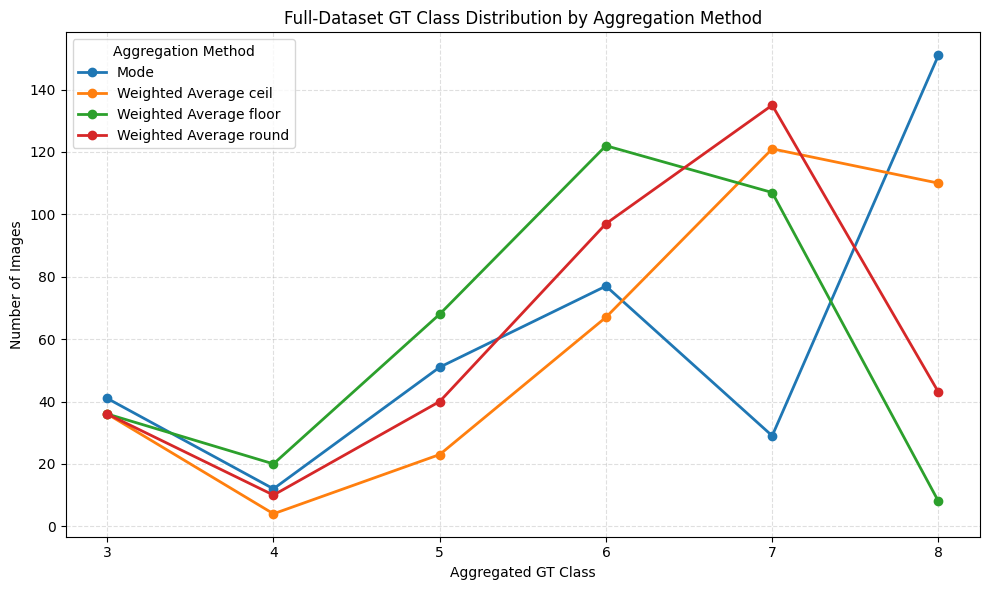

In [ ]:
# Remove Total row and prepare table
counts_no_total = full_gt_counts_table[
    full_gt_counts_table["Aggregated Class"] != "Total"
].copy()

counts_no_total["Aggregated Class"] = counts_no_total["Aggregated Class"].astype(int)

counts_no_total = counts_no_total.sort_values("Aggregated Class")

# Set class ID as index
counts_no_total = counts_no_total.set_index("Aggregated Class")

display(counts_no_total)

# Plot all aggregation methods on same figure
plt.figure(figsize=(10, 6))

for method in counts_no_total.columns:
    plt.plot(
        counts_no_total.index,
        counts_no_total[method],
        marker="o",
        linewidth=2,
        label=method
    )

plt.xlabel("Aggregated GT Class")
plt.ylabel("Number of Images")
plt.title("Full-Dataset GT Class Distribution by Aggregation Method")

plt.xticks(DAMAGE_CLASSES)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend(title="Aggregation Method")

plt.tight_layout()
plt.show()

## 4. Dataset class and train/validation/test split

### 4.1 Dataset class

`BuildingDataset` pairs every mask with its photograph: the UUID that follows `Label_<n>_` in the mask name must be the start of an image file name. For each sample it

1. reads the photograph as RGB in its stored pixel orientation (the EXIF orientation tag is not applied, here or at inference in Section 7) and reads the mask values as class IDs;
2. resizes image and mask to `IMAGE_SIZE` (1024 × 1024); Albumentations resizes masks with nearest-neighbour interpolation, so class IDs are preserved;
3. if `augment=True`, applies a horizontal flip, a rotation by a random multiple of 90°, a random shift, scale and rotation (shift up to 6.25% of the image size, scale ±10%, rotation up to ±45°) and colour jitter, each with probability 0.5;
4. applies the checkpoint preprocessing to the image.

One dataset object with `augment=True` is created, and the three splits below are subsets of it. Section 6 explains the consequence for the validation and test losses. If your masks were drawn on photographs that had been rotated according to their EXIF tag, apply `ImageOps.exif_transpose` to the image in step 1 and in `perform_segmentation`.

In [ ]:
from torch.utils.data import Dataset

class BuildingDataset(Dataset):
    def __init__(self, image_folder, mask_folder, preprocessing, base_transforms=None,
                 augment=False, image_size=(1024, 1024)):
        """
        image_folder: folder with the building photographs.
        mask_folder: folder with the class-ID masks (Label_<n>_<UUID>.png).
        preprocessing: preprocessing pipeline of the pretrained checkpoint.
        base_transforms: optional Albumentations transforms applied to every sample.
        augment: if True, random augmentation is applied after resizing.
        image_size: (height, width) to which image and mask are resized.
        """
        self.image_folder = image_folder
        self.mask_folder = mask_folder
        self.preprocessing = preprocessing
        self.base_transforms = base_transforms
        self.augment = augment
        self.pairs = self._collect_pairs()
        self.image_size = image_size

        if self.augment:
            self.augmentation_pipeline = A.Compose([
                A.HorizontalFlip(p=0.5),
                A.RandomRotate90(p=0.5),
                A.ShiftScaleRotate(shift_limit=0.0625, scale_limit=0.1, rotate_limit=45, p=0.5),
                A.ColorJitter(p=0.5),
            ])
        else:
            self.augmentation_pipeline = None

    def _collect_pairs(self):
        # Label_<n>_<UUID>.png belongs to the image whose file name starts with <UUID>
        pairs = []
        mask_files = [f for f in os.listdir(self.mask_folder) if f.startswith("Label_") and f.endswith(".png")]
        building_files = os.listdir(self.image_folder)

        def find_building_image(base_img_name, building_files):
            for file in building_files:
                if file.startswith(base_img_name):
                    return file
            return None

        for mask_file in mask_files:
            parts = mask_file.split('_')
            if len(parts) < 3:
                continue
            image_part = "_".join(parts[2:])
            base_img_name = os.path.splitext(image_part)[0]
            building_img_file = find_building_image(base_img_name, building_files)
            if building_img_file:
                original_path = os.path.join(self.image_folder, building_img_file)
                mask_path = os.path.join(self.mask_folder, mask_file)
                pairs.append((original_path, mask_path))
        return pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        image_path, mask_path = self.pairs[idx]
        image = np.array(Image.open(image_path).convert("RGB"))  # EXIF orientation not applied
        mask = np.array(Image.open(mask_path))                    # pixel values are model class IDs

        resize_transform = A.Resize(height=self.image_size[0], width=self.image_size[1])
        resized = resize_transform(image=image, mask=mask)
        image, mask = resized["image"], resized["mask"]

        if self.base_transforms:
            augmented = self.base_transforms(image=image, mask=mask)
            image, mask = augmented["image"], augmented["mask"]

        if self.augment and self.augmentation_pipeline:
            augmented = self.augmentation_pipeline(image=image, mask=mask)
            image, mask = augmented["image"], augmented["mask"]

        # Normalisation from the pretrained checkpoint (image only)
        preprocessed = self.preprocessing(image=image)
        image = preprocessed["image"]

        image = torch.as_tensor(image).permute(2, 0, 1).float()
        mask = torch.as_tensor(mask).long()
        return image, mask

building_dataset = BuildingDataset(IMAGE_DIR, MASK_DIR, preprocessing, base_transforms=None,
                                   augment=True, image_size=IMAGE_SIZE)

### 4.2 Multilabel stratified split

The dataset is divided into training, validation and test sets by a priority-based iterative multilabel stratification. A single image usually contains several classes, so a conventional single-label stratified split is not suitable; the split is based instead on the class composition of each ground-truth mask.

For each image the proportion of pixels in each class is computed. Because the masks were annotated by hand, any non-zero proportion counts as an occurrence, without a minimum area. The stratification gives priority to the triage categories (classes 3 to 8). For each of them, the images in which the class is present are divided into low, medium and high bins at the 33rd and 67th percentiles of that class's non-zero proportions; the thresholds are computed separately for each class because the classes differ in frequency and coverage. The table "Class-specific binning thresholds for priority classes" in the output gives the number of images where each class is present and the two thresholds in percent; it is Table 2 of the manuscript. (The code would use two bins split at the median for a class present in fewer than 50 images, and only a presence flag below 15 images, but all six categories occur in at least 66 images.) Only the non-zero bins are one-hot encoded, since absence is implied when all three bin indicators of a class are zero. This gives 18 labels for the triage categories. Machinery and personnel (classes 1 and 2) add one presence/absence label each, and background (class 0) is excluded because it appears in almost every image. The stratification matrix therefore has shape 361 × 20.

The images are then split by iterative multilabel stratification (`MultilabelStratifiedShuffleSplit` from the iterative-stratification package) in two stages: first 15% of the images are assigned to the test set, then the remaining 85% are split so that the validation set is 15% of all images. With `SEED = 42` this yields 249 training, 53 validation and 59 test images.

The cell then compares the subsets. The table "Mean pixel percentage per class" gives, for each class, the mean over images of the per-image pixel percentage; its "Full %" column is Table 4 of the manuscript. Every triage category is present in every subset. For the rarest category, B (class 4), the 66 images in which it occurs form three bins of 22 images, each split into 16 training, 3 validation and 3 test images. For every triage category the mean pixel percentage in the validation and test sets is within 50% (relative) of its full-set value, the threshold used for the warnings. The cell also creates the three data loaders with batch size 4.

The split is defined by positions in `building_dataset.pairs`, which follow the order in which `os.listdir` returns the mask files. That order is not guaranteed to be the same on another file system, so a re-run may give a different, equally stratified split. The cell after the split saves the file names of each subset to `split_assignment.csv`. The test images of the reported run are listed in `gt_agg_test.csv` and `pred_agg_test.csv` (Section 9).

In [ ]:
import os
import numpy as np
import pandas as pd
from PIL import Image

import torch
from torch.utils.data import Subset, DataLoader

from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

num_classes = NUM_CLASSES
random_state = SEED

# Damage classes drive the split; machinery (1) and personnel (2) enter only as presence
# labels, and background (0) is not used.
priority_classes = DAMAGE_CLASSES
secondary_presence_classes = [1, 2]

train_fraction = TRAIN_FRACTION
val_fraction = VAL_FRACTION
test_fraction = TEST_FRACTION

assert abs(train_fraction + val_fraction + test_fraction - 1.0) < 1e-8

# Image and mask paths from building_dataset.pairs
if not hasattr(building_dataset, "pairs"):
    raise AttributeError(
        "building_dataset does not have a .pairs attribute. "
        "Please inspect the dataset object again."
    )

pairs = building_dataset.pairs

if len(pairs) != len(building_dataset):
    raise ValueError(
        f"len(building_dataset.pairs) = {len(pairs)}, "
        f"but len(building_dataset) = {len(building_dataset)}. "
        "These must match."
    )

image_paths = [p[0] for p in pairs]
mask_paths = [p[1] for p in pairs]

dataset_size = len(building_dataset)

print(f"Dataset size: {dataset_size}")
print(f"Number of image paths: {len(image_paths)}")
print(f"Number of mask paths: {len(mask_paths)}")

print("\nFirst 5 image-mask pairs:")
for img_p, mask_p in pairs[:5]:
    print("IMAGE:", img_p)
    print("MASK: ", mask_p)
    print()

# Helper functions
def read_mask_as_class_ids(mask_path):
    """
    Reads a manually labeled semantic segmentation mask as a 2D class-ID array.

    This function assumes that mask pixel values are already class IDs 0–8.

    If the mask is RGB/RGBA, this function raises an error rather than silently
    using one channel, because RGB masks may require color-to-class remapping.
    """
    mask = np.array(Image.open(mask_path))

    if mask.ndim == 3:
        raise ValueError(
            f"Mask appears to be RGB/RGBA or multi-channel:\n{mask_path}\n\n"
            "This stratification code assumes class-ID masks where pixel values are 0–8.\n"
            "If your masks are RGB color masks, you need a color-to-class-ID conversion first."
        )

    unique_vals = np.unique(mask)

    if unique_vals.min() < 0 or unique_vals.max() >= num_classes:
        raise ValueError(
            f"Unexpected class values in mask:\n{mask_path}\n"
            f"Unique values found: {unique_vals}\n"
            f"Expected values only from 0 to {num_classes - 1}."
        )

    return mask.astype(np.int64)

def get_class_percentages(mask_path, num_classes=9):
    """
    Computes the fraction of pixels belonging to each class in one mask.
    Returns an array of length num_classes.
    """
    mask = read_mask_as_class_ids(mask_path)
    counts = np.bincount(mask.ravel(), minlength=num_classes)
    percentages = counts / counts.sum()
    return percentages

def compute_all_percentages(mask_paths, num_classes=9):
    """
    Computes per-image class percentages for all masks.

    Output shape:
    [number_of_images, num_classes]
    """
    all_percentages = []

    for i, mask_path in enumerate(mask_paths):
        percentages = get_class_percentages(mask_path, num_classes=num_classes)
        all_percentages.append(percentages)

        if (i + 1) % 50 == 0:
            print(f"Processed {i + 1}/{len(mask_paths)} masks")

    return np.array(all_percentages)

def assign_class_specific_bins(class_percentages):
    """
    Assigns bins for one class based on the nonzero distribution.

    Manual ground-truth assumption:
    If percentage > 0, the class is meaningful.
    Therefore, there is no minimum threshold.

    Bin logic:
    - 0 means absent
    - if n_present < 15:
        bin 1 = present
    - if 15 <= n_present < 50:
        bin 1 = low
        bin 2 = high
        threshold = median of nonzero percentages
    - if n_present >= 50:
        bin 1 = low
        bin 2 = medium
        bin 3 = high
        thresholds = 33rd and 67th percentiles of nonzero percentages
    """
    bins = np.zeros_like(class_percentages, dtype=int)
    nonzero = class_percentages[class_percentages > 0]
    n_present = len(nonzero)

    threshold_info = {
        "n_present": n_present,
        "binning": None,
        "thresholds": []
    }

    if n_present == 0:
        threshold_info["binning"] = "absent_from_dataset"
        return bins, threshold_info

    if n_present < 15:
        bins[class_percentages > 0] = 1
        threshold_info["binning"] = "absent/present"

    elif n_present < 50:
        median = np.quantile(nonzero, 0.50)

        bins[(class_percentages > 0) & (class_percentages <= median)] = 1
        bins[class_percentages > median] = 2

        threshold_info["binning"] = "absent/low/high"
        threshold_info["thresholds"] = [median]

    else:
        q33 = np.quantile(nonzero, 1 / 3)
        q67 = np.quantile(nonzero, 2 / 3)

        bins[(class_percentages > 0) & (class_percentages <= q33)] = 1
        bins[(class_percentages > q33) & (class_percentages <= q67)] = 2
        bins[class_percentages > q67] = 3

        threshold_info["binning"] = "absent/low/medium/high"
        threshold_info["thresholds"] = [q33, q67]

    return bins, threshold_info

def build_priority_stratification_matrix(all_percentages, priority_classes, secondary_presence_classes):
    """
    Builds a multilabel binary matrix for iterative stratification.

    Priority classes:
    - use class-specific bins
    - one-hot encode nonzero bins

    Secondary classes:
    - use only simple presence/absence
    - this gives weak balancing without letting them dominate

    Background class 0 is excluded from stratification.
    It will still be evaluated in the verification report.
    """
    label_columns = []
    label_names = []
    class_bins = {}
    threshold_records = {}

    # Priority damage/triage classes with class-specific bins
    for c in priority_classes:
        class_percentages = all_percentages[:, c]
        bins, threshold_info = assign_class_specific_bins(class_percentages)

        class_bins[c] = bins
        threshold_records[c] = threshold_info

        nonzero_bins = sorted([b for b in np.unique(bins) if b > 0])

        for b in nonzero_bins:
            label_columns.append((bins == b).astype(int))
            label_names.append(f"class_{c}_bin_{b}")

    # Secondary classes with presence/absence only
    for c in secondary_presence_classes:
        class_percentages = all_percentages[:, c]
        present = (class_percentages > 0).astype(int)

        if present.sum() > 0:
            label_columns.append(present)
            label_names.append(f"class_{c}_present_secondary")

    if len(label_columns) == 0:
        raise ValueError(
            "No stratification labels were created. "
            "Check whether priority classes are present in the masks."
        )

    Y = np.vstack(label_columns).T

    return Y, label_names, class_bins, threshold_records

def pixel_distribution_for_indices(all_percentages, indices):
    """
    Since all_percentages are per-image percentages, this returns the mean
    image-level class percentages for a subset.

    For equal-size masks, this is equivalent to the pixel distribution.
    For unequal-size masks, use raw pixel counts instead.
    """
    return all_percentages[indices].mean(axis=0)

def class_presence_counts_for_indices(all_percentages, indices):
    """
    Counts how many images in a subset contain each class.
    Manual labels: percentage > 0 means present.
    """
    return (all_percentages[indices] > 0).sum(axis=0)

def print_split_verification(
    all_percentages,
    train_idx,
    val_idx,
    test_idx,
    priority_classes,
    class_bins,
    threshold_records
):
    """
    Prints a detailed verification report for the split.
    """
    split_indices = {
        "Full": np.arange(len(all_percentages)),
        "Train": train_idx,
        "Val": val_idx,
        "Test": test_idx
    }

    print("\n============================================================")
    print("Split sizes")
    print("============================================================")
    for name, idx in split_indices.items():
        print(f"{name}: {len(idx)} images")

    # Pixel percentage table
    pixel_rows = []

    for c in range(num_classes):
        row = {"Class": c}

        for split_name, idx in split_indices.items():
            dist = pixel_distribution_for_indices(all_percentages, idx)
            row[f"{split_name} %"] = dist[c] * 100

        pixel_rows.append(row)

    pixel_table = pd.DataFrame(pixel_rows)

    print("\n============================================================")
    print("Mean pixel percentage per class")
    print("============================================================")
    display(pixel_table.round(3))

    # Presence counts table
    presence_rows = []

    for c in range(num_classes):
        row = {"Class": c}

        for split_name, idx in split_indices.items():
            counts = class_presence_counts_for_indices(all_percentages, idx)
            row[f"{split_name} present images"] = int(counts[c])

        presence_rows.append(row)

    presence_table = pd.DataFrame(presence_rows)

    print("\n============================================================")
    print("Number of images where each class is present")
    print("Manual mask rule: percentage > 0 means present")
    print("============================================================")
    display(presence_table)

    # Thresholds for priority classes
    threshold_rows = []

    for c in priority_classes:
        info = threshold_records[c]
        thresholds_percent = [t * 100 for t in info["thresholds"]]

        threshold_rows.append({
            "Class": c,
            "n_present_full": info["n_present"],
            "binning": info["binning"],
            "thresholds_percent": thresholds_percent
        })

    threshold_table = pd.DataFrame(threshold_rows)

    print("\n============================================================")
    print("Class-specific binning thresholds for priority classes")
    print("============================================================")
    display(threshold_table)

    # Bin counts for priority classes
    print("\n============================================================")
    print("Priority-class bin counts by split")
    print("============================================================")

    for c in priority_classes:
        bins = class_bins[c]
        possible_bins = sorted(np.unique(bins))

        rows = []

        for b in possible_bins:
            row = {
                "Class": c,
                "Bin": b
            }

            for split_name, idx in split_indices.items():
                row[split_name] = int((bins[idx] == b).sum())

            rows.append(row)

        bin_table = pd.DataFrame(rows)
        print(f"\nClass {c} bin counts:")
        display(bin_table)

    # Warnings
    print("\n============================================================")
    print("Warnings")
    print("============================================================")

    warnings_found = False

    full_presence = class_presence_counts_for_indices(all_percentages, split_indices["Full"])
    val_presence = class_presence_counts_for_indices(all_percentages, split_indices["Val"])
    test_presence = class_presence_counts_for_indices(all_percentages, split_indices["Test"])

    full_dist = pixel_distribution_for_indices(all_percentages, split_indices["Full"])
    train_dist = pixel_distribution_for_indices(all_percentages, split_indices["Train"])
    val_dist = pixel_distribution_for_indices(all_percentages, split_indices["Val"])
    test_dist = pixel_distribution_for_indices(all_percentages, split_indices["Test"])

    for c in priority_classes:
        if full_presence[c] > 0 and val_presence[c] == 0:
            print(f"HIGH PRIORITY WARNING: Class {c} exists in full dataset but is missing from validation.")
            warnings_found = True

        if full_presence[c] > 0 and test_presence[c] == 0:
            print(f"HIGH PRIORITY WARNING: Class {c} exists in full dataset but is missing from test.")
            warnings_found = True

        # Relative pixel-percentage difference warning
        # Avoid division by zero.
        if full_dist[c] > 0:
            val_rel_diff = abs(val_dist[c] - full_dist[c]) / full_dist[c]
            test_rel_diff = abs(test_dist[c] - full_dist[c]) / full_dist[c]

            if val_rel_diff > 0.50:
                print(
                    f"HIGH PRIORITY WARNING: Class {c} validation percentage differs from full dataset "
                    f"by {val_rel_diff * 100:.1f}% relative."
                )
                warnings_found = True

            if test_rel_diff > 0.50:
                print(
                    f"HIGH PRIORITY WARNING: Class {c} test percentage differs from full dataset "
                    f"by {test_rel_diff * 100:.1f}% relative."
                )
                warnings_found = True

    for c in [0, 1, 2]:
        if full_presence[c] > 0 and val_presence[c] == 0:
            print(f"Lower-priority warning: Class {c} is missing from validation.")
            warnings_found = True

        if full_presence[c] > 0 and test_presence[c] == 0:
            print(f"Lower-priority warning: Class {c} is missing from test.")
            warnings_found = True

    if not warnings_found:
        print("No major split warnings detected.")

# Compute per-image class percentages
print("\nComputing per-image class percentages from masks...")
all_percentages = compute_all_percentages(mask_paths, num_classes=num_classes)

print("\nFinished computing class percentages.")
print("Shape of all_percentages:", all_percentages.shape)

# Build priority multilabel stratification matrix
Y, label_names, class_bins, threshold_records = build_priority_stratification_matrix(
    all_percentages=all_percentages,
    priority_classes=priority_classes,
    secondary_presence_classes=secondary_presence_classes
)

print("\nStratification matrix created.")
print("Y shape:", Y.shape)
print("Number of stratification labels:", len(label_names))

print("\nStratification labels:")
for name in label_names:
    print("-", name)

# First split: train_val / test
all_indices = np.arange(dataset_size)

msss_test = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=test_fraction,
    random_state=random_state
)

train_val_idx, test_idx = next(msss_test.split(all_indices, Y))

train_val_idx = np.array(train_val_idx)
test_idx = np.array(test_idx)

print("\nFirst split complete:")
print("Train+Val:", len(train_val_idx))
print("Test:", len(test_idx))

# Second split: train / validation
# Validation is 15% of the full dataset.
# After removing 15% test, validation should be:
# 0.15 / 0.85 of the remaining train_val set.
val_fraction_of_train_val = val_fraction / (train_fraction + val_fraction)

Y_train_val = Y[train_val_idx]

msss_val = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=val_fraction_of_train_val,
    random_state=random_state
)

train_rel_idx, val_rel_idx = next(msss_val.split(train_val_idx, Y_train_val))

train_idx = train_val_idx[train_rel_idx]
val_idx = train_val_idx[val_rel_idx]

train_idx = np.array(train_idx)
val_idx = np.array(val_idx)

print("\nSecond split complete:")
print("Train:", len(train_idx))
print("Val:", len(val_idx))
print("Test:", len(test_idx))

# Create PyTorch dataset subsets
train_dataset = Subset(building_dataset, train_idx.tolist())
val_dataset = Subset(building_dataset, val_idx.tolist())
test_dataset = Subset(building_dataset, test_idx.tolist())

print("\nPyTorch Subsets created:")
print("train_dataset:", len(train_dataset))
print("val_dataset:", len(val_dataset))
print("test_dataset:", len(test_dataset))

# Create DataLoaders
batch_size = BATCH_SIZE
num_workers = NUM_WORKERS

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers
)

print("\nDataLoaders created:")
print("train_loader batches:", len(train_loader))
print("val_loader batches:", len(val_loader))
print("test_loader batches:", len(test_loader))

# Verification report
print_split_verification(
    all_percentages=all_percentages,
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,
    priority_classes=priority_classes,
    class_bins=class_bins,
    threshold_records=threshold_records
)

Dataset size: 361
Number of image paths: 361
Number of mask paths: 361

First 5 image-mask pairs:
IMAGE: /content/turkey_gt_images/684586A6-5FE3-4604-9A55-31F094D3541B.jpg
MASK:  /content/turkey_gt_masks/Label_197_684586A6-5FE3-4604-9A55-31F094D3541B.png

IMAGE: /content/turkey_gt_images/BE11E2F6-7A43-4B94-B9E4-76959ABEB005.jpg
MASK:  /content/turkey_gt_masks/Label_92_BE11E2F6-7A43-4B94-B9E4-76959ABEB005.png

IMAGE: /content/turkey_gt_images/5D226B46-E96D-46C3-BD96-42A5BEC9A4C1.jpg
MASK:  /content/turkey_gt_masks/Label_214_5D226B46-E96D-46C3-BD96-42A5BEC9A4C1.png

IMAGE: /content/turkey_gt_images/C2875EE1-8F21-47EC-AE8E-9266FC298D05.jpg
MASK:  /content/turkey_gt_masks/Label_85_C2875EE1-8F21-47EC-AE8E-9266FC298D05.png

IMAGE: /content/turkey_gt_images/869B730A-D1B9-4DFB-8841-1DD70CFEBD82.jpg
MASK:  /content/turkey_gt_masks/Label_153_869B730A-D1B9-4DFB-8841-1DD70CFEBD82.png


Computing per-image class percentages from masks...
Processed 50/361 masks
Processed 100/361 masks
Processed 150/

,Class,Full %,Train %,Val %,Test %
0,0,37.408,37.781,32.522,40.221
1,1,2.741,2.852,2.596,2.404
2,2,3.626,3.906,4.143,1.979
3,3,7.447,7.103,9.177,7.345
4,4,2.280,2.522,1.591,1.879
5,5,8.079,8.127,8.687,7.330
6,6,11.726,11.404,12.880,12.046
7,7,6.036,6.017,5.925,6.218
8,8,20.658,20.289,22.478,20.578



Number of images where each class is present
Manual mask rule: percentage > 0 means present


,Class,Full present images,Train present images,Val present images,Test present images
0,0,356,246,51,59
1,1,147,101,24,22
2,2,183,127,28,28
3,3,159,109,24,26
4,4,66,48,9,9
5,5,111,75,18,18
6,6,176,120,27,29
7,7,125,89,18,18
8,8,272,187,41,44



Class-specific binning thresholds for priority classes


,Class,n_present_full,binning,thresholds_percent
0,3,159,absent/low/medium/high,"[5.40283203125, 13.18919818904124]"
1,4,66,absent/low/medium/high,"[4.102973090277776, 10.295124127402442]"
2,5,111,absent/low/medium/high,"[9.484555844907407, 30.922489872685183]"
3,6,176,absent/low/medium/high,"[8.456958912037036, 27.805374710648138]"
4,7,125,absent/low/medium/high,"[8.088939525462962, 17.146773726851848]"
5,8,272,absent/low/medium/high,"[15.580674913194445, 32.09020543981481]"


... (9 outputs left out)

,Class,Bin,Full,Train,Val,Test
0,7,0,236,160,35,41
1,7,1,42,30,6,6
2,7,2,41,29,6,6
3,7,3,42,30,6,6



Class 8 bin counts:


,Class,Bin,Full,Train,Val,Test
0,8,0,89,62,12,15
1,8,1,91,63,14,14
2,8,2,90,61,13,16
3,8,3,91,63,14,14



Warnings
No major split warnings detected.


In [ ]:
# Record which files ended up in which subset
split_rows = []
for split_name, indices in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    for i in indices:
        image_path, mask_path = building_dataset.pairs[i]
        split_rows.append({
            "image_file": os.path.basename(image_path),
            "mask_file": os.path.basename(mask_path),
            "split": split_name,
        })
pd.DataFrame(split_rows).to_csv(os.path.join(OUTPUT_DIR, "split_assignment.csv"), index=False)

## 5. Model

The starting point is `smp-hub/segformer-b2-1024x1024-city-160k`, the SegFormer-B2 model distributed with segmentation_models_pytorch: a Mix Transformer encoder (MiT-B2) and an all-MLP decoder with 768 output channels, trained on Cityscapes (19 classes) at 1024 × 1024 pixels. The checkpoint is public, so no Hugging Face token is needed; a warning about a missing `HF_TOKEN` may still appear and can be ignored.

The pretrained segmentation head, a 1 × 1 convolution from the 768 decoder channels to the 19 Cityscapes classes followed by 4× bilinear upsampling, is replaced by a single new 1 × 1 convolution from 768 channels to `NUM_CLASSES` = 9 (six INSARAG triage categories, personnel, machinery and background). The new head is randomly initialised with the PyTorch default; no weights are copied from the Cityscapes head, whose output channels belong to unrelated classes. Since the new head has no upsampling layer, the model returns logits at a quarter of the input resolution (256 × 256 for a 1024 × 1024 input). The training loop and `perform_segmentation` upsample them bilinearly to the size of the mask or image. The head is created before the random seed is set in Section 6, so its initial weights are not reproducible between runs.

The encoder weights are then frozen to preserve the general urban visual features learned on Cityscapes, and only the decoder and the new head are trained, so that the model adapts to post-earthquake textures and damage patterns with limited data.

To adapt the model, change `NUM_CLASSES` for a different number of classes (and the class names and colours in Section 7), or `CHECKPOINT` for another smp-hub checkpoint, for example a larger SegFormer. The input width of the new head is read from the old head, so the code needs no other change as long as the checkpoint's head is a convolution followed by upsampling. To fine-tune the whole network, skip the cell that freezes the encoder.

In [ ]:
model = smp.from_pretrained(CHECKPOINT).to(device)

# Replace the 19-class Cityscapes head (1x1 conv + 4x upsampling) with a randomly
# initialised 1x1 conv for our classes. The model then outputs logits at 1/4 resolution.
in_channels = model.segmentation_head[0].in_channels
new_head = torch.nn.Conv2d(in_channels, NUM_CLASSES, kernel_size=1)
model.segmentation_head = new_head.to(device)

In [ ]:
# Freeze the encoder; the decoder and the new head are trained
for param in model.encoder.parameters():
    param.requires_grad = False

print("Encoder layers frozen. Only the head and later layers will be trained.")

Encoder layers frozen. Only the head and later layers will be trained.


## 6. Training

The training cell does the following.

Loss. Weighted cross-entropy, so that errors on rare classes are penalised more than errors on frequent ones. The class weights are computed from the pixel frequencies of the training masks only, so the loss uses no information from the validation or test sets. For a class with pooled training pixel frequency f_c the weight is median(f) / f_c (median-frequency balancing), and the nine weights are then rescaled to a mean of 1. The rarest class in training, triage category B (1.366% of training pixels), receives weight 2.8807, while background (0.0989) and category A (0.1430) are down-weighted.

Optimisation. Adam with learning rate 1e-3, batch size 4 and at most 50 epochs. Parameters of the frozen encoder receive no gradients and are not updated. The learning rate is halved when the validation loss has not improved for 2 epochs (`ReduceLROnPlateau`). An epoch counts as an improvement if the validation loss falls by more than 1e-4, and training stops after 8 epochs without improvement.

Checkpoints. The latest state is saved after every epoch and `best_model.pt` whenever the validation loss improves; every 5 epochs a numbered checkpoint is written and, if Drive mirroring is on, copied to Drive together with the latest state, the current best model and the loss history. If the runtime disconnects, re-running the cell resumes from the latest checkpoint in `OUTPUT_DIR`, or from the Drive copy if the local one is gone. After training, the best checkpoint is reloaded and its loss on the test set is computed. The cell also shows one image and mask from each subset as a visual check; the images look unnatural because they are normalised, and the matplotlib clipping warnings are expected.

Augmentation of the validation and test sets. The cell tries to switch augmentation off for the validation and test sets, but the three subsets are `torch.utils.data.Subset` objects that share the single dataset created with `augment=True`, and a `Subset` has no `augment` attribute (the output reports "No augment attribute"). The validation and test losses were therefore computed on randomly augmented images. This affects the validation losses used for learning-rate scheduling, early stopping and the choice of the best epoch (best validation loss 1.5627 at epoch 21), and the reported test loss of 1.4063. It does not affect the test IoU, the confusion matrix or the image-level results in Sections 8 to 10, because `perform_segmentation` reads the original image files of the test pairs without augmentation. To evaluate the losses without augmentation, build a second `BuildingDataset` with `augment=False` and create the validation and test subsets from it with the same indices.

Result. Training stopped early after epoch 29. The lowest validation loss, 1.5627, was reached at epoch 21. The learning rate was reduced to 5e-4 after epoch 12, 2.5e-4 after epoch 18, 1.25e-4 after epoch 24 and 6.25e-5 after epoch 27. One epoch took about 156 s on the T4 GPU and the whole run 76.21 minutes. The best checkpoint has a test loss of 1.4063. These are weighted cross-entropy values on augmented images and serve mainly to compare epochs; Sections 8 to 10 give the evaluation of the model.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Runtime checkpoint directory: /content/segformer_runtime_checkpoints
Drive checkpoint directory: /content/drive/MyDrive/segformer_checkpoints
Device: cuda

Dataset sizes:
Train: 249
Val:   53
Test:  59

Augmentation status:
Train augment: No augment attribute
Val augment:   No augment attribute
Test augment:  No augment attribute

DataLoader batches:
Train: 63
Val:   14
Test:  15

Train batch check:
images shape: torch.Size([4, 3, 1024, 1024])
masks shape:  torch.Size([4, 1024, 1024])
images dtype: torch.float32
masks dtype:  torch.int64
mask min/max: 0 8
unique mask values in first item: [0 1 2 6 7 8]

Validation batch check:
images shape: torch.Size([4, 3, 1024, 1024])
masks shape:  torch.Size([4, 1024, 1024])
images dtype: torch.float32
masks dtype:  torch.int64
mask min/max: 0 8
unique mask values in first item: [0 1 2 3 5 6 7 8]



Test batch check:
images shape: torch.Size([4, 3, 1024, 1024])
masks shape:  torch.Size([4, 1024, 1024])
images dtype: torch.float32
masks dtype:  torch.int64
mask min/max: 0 8
unique mask values in first item: [0 4 6 7 8]


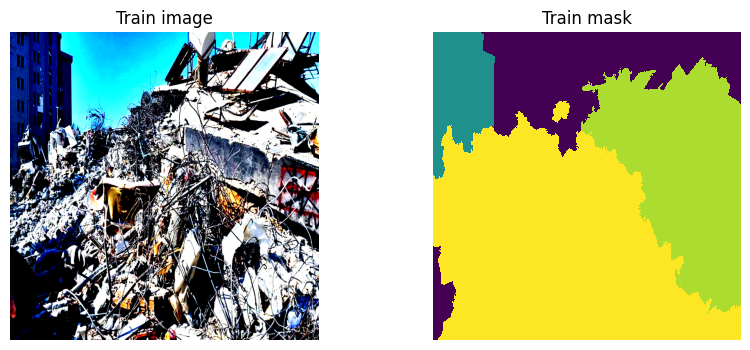

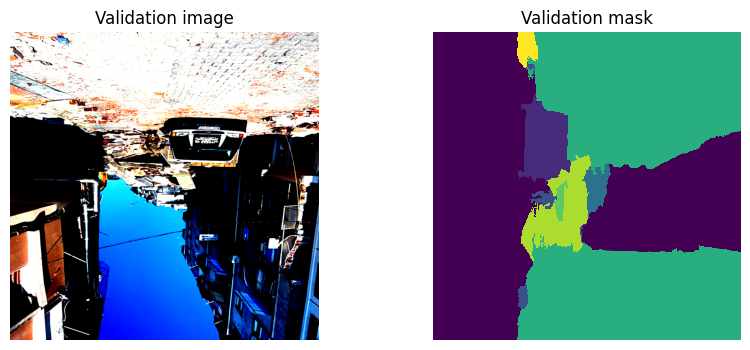

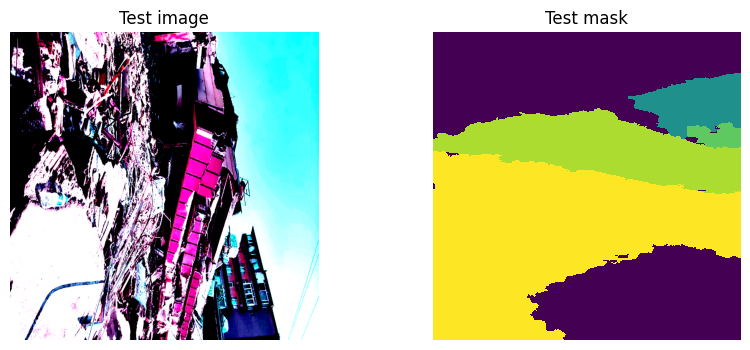


Training class pixel counts:
Class 0: 213447009
Class 1: 15715349
Class 2: 13615575
Class 3: 147586412
Class 4: 7328352
Class 5: 27412406
Class 6: 39975171
Class 7: 16209218
Class 8: 55123340

Class frequencies from training set:
Class 0: 39.792%
Class 1: 2.930%
Class 2: 2.538%
Class 3: 27.514%
Class 4: 1.366%
Class 5: 5.110%
Class 6: 7.452%
Class 7: 3.022%
Class 8: 10.276%

Class weights used in loss:
Class 0: 0.0989
Class 1: 1.3433
Class 2: 1.5505
Class 3: 0.1430
Class 4: 2.8807
Class 5: 0.7701
Class 6: 0.5281
Class 7: 1.3024
Class 8: 0.3830

No checkpoint found. Starting training from scratch.
Epoch 001/50 | Train Loss: 1.9751 | Val Loss: 1.7083 | LR: 0.001000 | Time: 161.4s
Saved checkpoint: /content/segformer_runtime_checkpoints/latest_runtime_checkpoint.pt
Saved checkpoint: /content/segformer_runtime_checkpoints/best_model.pt
New best model saved in runtime at epoch 1. Best val loss: 1.7083
Epoch 002/50 | Train Loss: 1.7318 | Val Loss: 1.6822 | LR: 0.001000 | Time: 155.7s
Saved 

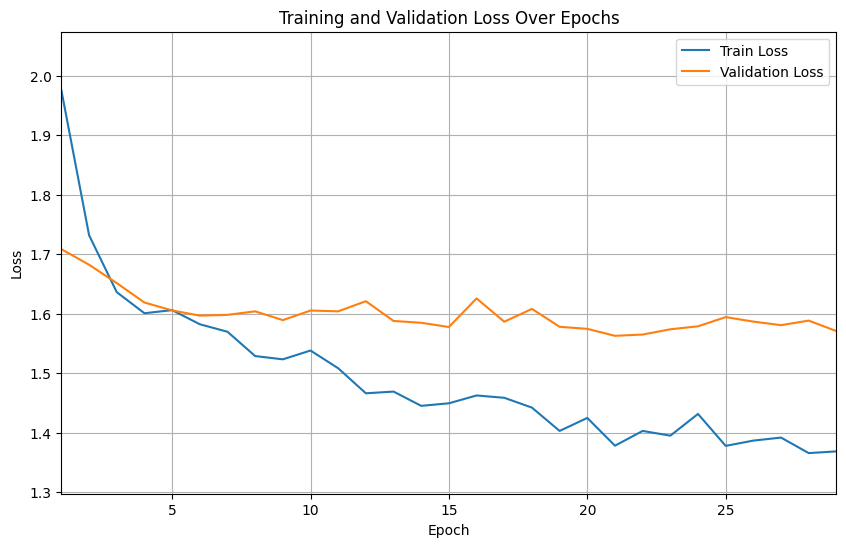

Saved runtime loss curve: /content/segformer_runtime_checkpoints/loss_curve.png
Copied to Drive: /content/drive/MyDrive/segformer_checkpoints/loss_curve.png


In [ ]:
import os
import json
import time
import shutil
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.optim as optim
import torch.nn.functional as F

import matplotlib.pyplot as plt

# Optional Google Drive backup (see MIRROR_TO_DRIVE)
if MIRROR_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_AVAILABLE = True
    except Exception as e:
        print("Google Drive mount failed. Continuing with runtime-only saving.")
        print("Error:", e)
        DRIVE_AVAILABLE = False
else:
    DRIVE_AVAILABLE = False

# Checkpoint directories
# Local runtime storage (lost when the runtime ends) and optional persistent Drive copy
RUNTIME_CHECKPOINT_DIR = OUTPUT_DIR
os.makedirs(RUNTIME_CHECKPOINT_DIR, exist_ok=True)

if DRIVE_AVAILABLE:
    DRIVE_CHECKPOINT_DIR = DRIVE_OUTPUT_DIR
    os.makedirs(DRIVE_CHECKPOINT_DIR, exist_ok=True)
else:
    DRIVE_CHECKPOINT_DIR = None

print("Runtime checkpoint directory:", RUNTIME_CHECKPOINT_DIR)
print("Drive checkpoint directory:", DRIVE_CHECKPOINT_DIR)

# Training settings
num_classes = NUM_CLASSES
num_epochs = NUM_EPOCHS
learning_rate = LEARNING_RATE

checkpoint_every = CHECKPOINT_EVERY
early_stopping_patience = EARLY_STOPPING_PATIENCE
min_delta = MIN_DELTA

random_state = SEED

torch.manual_seed(random_state)
np.random.seed(random_state)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_state)

print("Device:", device)

# Attempt to switch augmentation off for val/test. The splits are Subset objects without
# an .augment attribute, so these checks have no effect (see the markdown above).

if hasattr(train_dataset, "augment"):
    train_dataset.augment = True

if hasattr(val_dataset, "augment"):
    val_dataset.augment = False

if hasattr(test_dataset, "augment"):
    test_dataset.augment = False

print("\nDataset sizes:")
print("Train:", len(train_dataset))
print("Val:  ", len(val_dataset))
print("Test: ", len(test_dataset))

print("\nAugmentation status:")
print("Train augment:", getattr(train_dataset, "augment", "No augment attribute"))
print("Val augment:  ", getattr(val_dataset, "augment", "No augment attribute"))
print("Test augment: ", getattr(test_dataset, "augment", "No augment attribute"))

# Sanity checks for loaded DataLoaders
print("\nDataLoader batches:")
print("Train:", len(train_loader))
print("Val:  ", len(val_loader))
print("Test: ", len(test_loader))

def inspect_one_batch(loader, split_name):
    images, masks = next(iter(loader))

    print(f"\n{split_name} batch check:")
    print("images shape:", images.shape)
    print("masks shape: ", masks.shape)
    print("images dtype:", images.dtype)
    print("masks dtype: ", masks.dtype)
    print("mask min/max:", masks.min().item(), masks.max().item())
    print("unique mask values in first item:", torch.unique(masks[0]).cpu().numpy())

    assert images.ndim == 4, f"{split_name}: images should be [B, C, H, W]"
    assert masks.ndim == 3, f"{split_name}: masks should be [B, H, W]"
    assert images.shape[0] == masks.shape[0], f"{split_name}: batch size mismatch"
    assert images.shape[2:] == masks.shape[1:], (
        f"{split_name}: image/mask spatial mismatch. "
        f"Image H/W: {images.shape[2:]}, mask H/W: {masks.shape[1:]}"
    )
    assert masks.min() >= 0, f"{split_name}: mask has negative labels"
    assert masks.max() < num_classes, f"{split_name}: mask contains labels >= {num_classes}"

    return images, masks

_ = inspect_one_batch(train_loader, "Train")
_ = inspect_one_batch(val_loader, "Validation")
_ = inspect_one_batch(test_loader, "Test")

# Optional visual sanity check
# This helps check that image and mask orientation match.
# The displayed image may look strange because it is normalized.

def show_image_mask_sample(dataset, split_name, sample_index=0):
    image, mask = dataset[sample_index]

    image_np = image.detach().cpu().numpy()
    mask_np = mask.detach().cpu().numpy()

    if image_np.ndim == 3:
        image_np = np.transpose(image_np, (1, 2, 0))

    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(image_np)
    plt.title(f"{split_name} image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(mask_np, interpolation="nearest")
    plt.title(f"{split_name} mask")
    plt.axis("off")

    plt.show()

show_image_mask_sample(train_dataset, "Train", sample_index=0)
show_image_mask_sample(val_dataset, "Validation", sample_index=0)
show_image_mask_sample(test_dataset, "Test", sample_index=0)

# Compute class weights from TRAINING masks only
def read_mask_as_class_ids(mask_path):
    mask = np.array(Image.open(mask_path))

    if mask.ndim == 3:
        raise ValueError(
            f"Mask appears to be RGB/RGBA:\n{mask_path}\n"
            "Expected a 2D class-ID mask."
        )

    if mask.min() < 0 or mask.max() >= num_classes:
        raise ValueError(
            f"Unexpected mask values in:\n{mask_path}\n"
            f"min={mask.min()}, max={mask.max()}"
        )

    return mask.astype(np.int64)

def get_pairs_from_dataset(dataset):
    """
    Gets image-mask pairs from a dataset.

    Expected for your BuildingDataset:
        dataset.pairs = [(image_path, mask_path), ...]

    If the dataset is a Subset, tries to recover pairs from dataset.dataset.pairs.
    """
    if hasattr(dataset, "pairs"):
        return dataset.pairs

    if hasattr(dataset, "dataset") and hasattr(dataset.dataset, "pairs"):
        return [dataset.dataset.pairs[i] for i in dataset.indices]

    raise AttributeError(
        "Could not find .pairs in train_dataset. "
        "Class weights require access to the training mask paths."
    )

def compute_class_pixel_counts_from_pairs(pairs, num_classes=9):
    counts = np.zeros(num_classes, dtype=np.int64)

    for _, mask_path in pairs:
        mask = read_mask_as_class_ids(mask_path)
        counts += np.bincount(mask.ravel(), minlength=num_classes)

    return counts

train_pairs = get_pairs_from_dataset(train_dataset)

train_class_pixel_counts = compute_class_pixel_counts_from_pairs(
    train_pairs,
    num_classes=num_classes
)

print("\nTraining class pixel counts:")
for c, count in enumerate(train_class_pixel_counts):
    print(f"Class {c}: {count}")

# Median-frequency class weights
# Weights are calculated only from the training set.
# This avoids leaking validation/test label information into training.

epsilon = 1e-6

class_freq = train_class_pixel_counts / train_class_pixel_counts.sum()
nonzero_freq = class_freq[class_freq > 0]
median_freq = np.median(nonzero_freq)

class_weights_np = median_freq / np.maximum(class_freq, epsilon)

# Normalize weights so the average weight is approximately 1.
class_weights_np = class_weights_np / class_weights_np.mean()

class_weights = torch.tensor(
    class_weights_np,
    dtype=torch.float32,
    device=device
)

print("\nClass frequencies from training set:")
for c, freq in enumerate(class_freq):
    print(f"Class {c}: {freq * 100:.3f}%")

print("\nClass weights used in loss:")
for c, w in enumerate(class_weights_np):
    print(f"Class {c}: {w:.4f}")

# Optimizer, scheduler, loss
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=LR_SCHEDULER_FACTOR,
    patience=LR_SCHEDULER_PATIENCE
)

criterion = torch.nn.CrossEntropyLoss(weight=class_weights)

# Helper: get logits from model output
def get_logits(model_output):
    if hasattr(model_output, "logits"):
        return model_output.logits
    return model_output

# Training and evaluation functions
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0

    for images, masks in loader:
        images = images.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True).long()

        optimizer.zero_grad()

        outputs = model(images)
        logits = get_logits(outputs)

        if logits.shape[-2:] != masks.shape[-2:]:
            logits = F.interpolate(
                logits,
                size=masks.shape[-2:],
                mode="bilinear",
                align_corners=False
            )

        loss = criterion(logits, masks)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)

def evaluate_loss(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True).long()

            outputs = model(images)
            logits = get_logits(outputs)

            if logits.shape[-2:] != masks.shape[-2:]:
                logits = F.interpolate(
                    logits,
                    size=masks.shape[-2:],
                    mode="bilinear",
                    align_corners=False
                )

            loss = criterion(logits, masks)
            total_loss += loss.item()

    return total_loss / len(loader)

# Checkpoint helpers
def save_checkpoint(
    path,
    model,
    optimizer,
    scheduler,
    epoch,
    train_losses,
    val_losses,
    best_val_loss,
    best_epoch,
    epochs_without_improvement,
    class_weights_np,
    history_rows,
    extra_info=None
):
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "train_losses": train_losses,
        "val_losses": val_losses,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "epochs_without_improvement": epochs_without_improvement,
        "class_weights": class_weights_np.tolist(),
        "history_rows": history_rows,
        "extra_info": extra_info or {}
    }

    torch.save(checkpoint, path)
    print(f"Saved checkpoint: {path}")

def copy_to_drive_if_available(src_path, dst_filename=None):
    if DRIVE_CHECKPOINT_DIR is None:
        return

    if dst_filename is None:
        dst_filename = os.path.basename(src_path)

    dst_path = os.path.join(DRIVE_CHECKPOINT_DIR, dst_filename)
    shutil.copy2(src_path, dst_path)
    print(f"Copied to Drive: {dst_path}")

runtime_best_path = os.path.join(RUNTIME_CHECKPOINT_DIR, "best_model.pt")
runtime_latest_path = os.path.join(RUNTIME_CHECKPOINT_DIR, "latest_runtime_checkpoint.pt")
runtime_history_path = os.path.join(RUNTIME_CHECKPOINT_DIR, "training_history.csv")
runtime_summary_path = os.path.join(RUNTIME_CHECKPOINT_DIR, "training_summary.json")
runtime_loss_plot_path = os.path.join(RUNTIME_CHECKPOINT_DIR, "loss_curve.png")

drive_latest_path = None
if DRIVE_CHECKPOINT_DIR is not None:
    drive_latest_path = os.path.join(DRIVE_CHECKPOINT_DIR, "latest_drive_checkpoint.pt")

# Resume logic
# Priority:
# 1. Resume from runtime latest checkpoint if it exists.
# 2. Otherwise resume from Drive latest checkpoint if it exists.
# 3. Otherwise start from scratch.
#
# Drive is updated only every 5 epochs, so after runtime loss,
# you resume from the most recent 5-epoch backup.

start_epoch = 1
train_losses = []
val_losses = []
best_val_loss = float("inf")
best_epoch = -1
epochs_without_improvement = 0
history_rows = []

resume_path = None

if os.path.exists(runtime_latest_path):
    resume_path = runtime_latest_path
elif drive_latest_path is not None and os.path.exists(drive_latest_path):
    resume_path = drive_latest_path

if resume_path is not None:
    print("\nFound checkpoint. Resuming from:", resume_path)

    checkpoint = torch.load(resume_path, map_location=device)

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    start_epoch = checkpoint["epoch"] + 1
    train_losses = checkpoint["train_losses"]
    val_losses = checkpoint["val_losses"]
    best_val_loss = checkpoint["best_val_loss"]
    best_epoch = checkpoint.get("best_epoch", -1)
    epochs_without_improvement = checkpoint.get("epochs_without_improvement", 0)
    history_rows = checkpoint.get("history_rows", [])

    print(f"Resuming from epoch {start_epoch}")
    print(f"Best epoch so far: {best_epoch}")
    print(f"Best validation loss so far: {best_val_loss:.4f}")
else:
    print("\nNo checkpoint found. Starting training from scratch.")

# Training loop
training_start_time = time.time()

for epoch in range(start_epoch, num_epochs + 1):
    epoch_start_time = time.time()

    avg_train_loss = train_one_epoch(
        model=model,
        loader=train_loader,
        optimizer=optimizer,
        criterion=criterion,
        device=device
    )

    avg_val_loss = evaluate_loss(
        model=model,
        loader=val_loader,
        criterion=criterion,
        device=device
    )

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    scheduler.step(avg_val_loss)
    current_lr = optimizer.param_groups[0]["lr"]

    epoch_time = time.time() - epoch_start_time

    print(
        f"Epoch {epoch:03d}/{num_epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"LR: {current_lr:.6f} | "
        f"Time: {epoch_time:.1f}s"
    )

    history_rows.append({
        "epoch": epoch,
        "train_loss": avg_train_loss,
        "val_loss": avg_val_loss,
        "lr": current_lr,
        "epoch_time_sec": epoch_time
    })

    # Save latest runtime checkpoint every epoch
    # This protects progress while the current runtime is alive.
    save_checkpoint(
        path=runtime_latest_path,
        model=model,
        optimizer=optimizer,
        scheduler=scheduler,
        epoch=epoch,
        train_losses=train_losses,
        val_losses=val_losses,
        best_val_loss=best_val_loss,
        best_epoch=best_epoch,
        epochs_without_improvement=epochs_without_improvement,
        class_weights_np=class_weights_np,
        history_rows=history_rows,
        extra_info={
            "checkpoint_type": "latest_runtime",
            "num_classes": num_classes,
            "learning_rate": learning_rate,
            "train_size": len(train_dataset),
            "val_size": len(val_dataset),
            "test_size": len(test_dataset)
        }
    )

    # Save best model in runtime immediately when validation improves
    # This overwrites the previous runtime best_model.pt.
    improved = avg_val_loss < (best_val_loss - min_delta)

    if improved:
        best_val_loss = avg_val_loss
        best_epoch = epoch
        epochs_without_improvement = 0

        save_checkpoint(
            path=runtime_best_path,
            model=model,
            optimizer=optimizer,
            scheduler=scheduler,
            epoch=epoch,
            train_losses=train_losses,
            val_losses=val_losses,
            best_val_loss=best_val_loss,
            best_epoch=best_epoch,
            epochs_without_improvement=epochs_without_improvement,
            class_weights_np=class_weights_np,
            history_rows=history_rows,
            extra_info={
                "checkpoint_type": "best_runtime",
                "num_classes": num_classes,
                "learning_rate": learning_rate,
                "train_size": len(train_dataset),
                "val_size": len(val_dataset),
                "test_size": len(test_dataset)
            }
        )

        print(f"New best model saved in runtime at epoch {epoch}. Best val loss: {best_val_loss:.4f}")

    else:
        epochs_without_improvement += 1
        print(
            f"No meaningful validation improvement. "
            f"Patience: {epochs_without_improvement}/{early_stopping_patience}"
        )

    # Save training history in runtime every epoch
    history_df = pd.DataFrame(history_rows)
    history_df.to_csv(runtime_history_path, index=False)

    # Persistent backup to Drive every checkpoint_every epochs only
    if epoch % checkpoint_every == 0:
        print(f"\nEpoch {epoch}: creating persistent Drive backup...")

        periodic_runtime_path = os.path.join(
            RUNTIME_CHECKPOINT_DIR,
            f"checkpoint_epoch_{epoch:03d}.pt"
        )

        save_checkpoint(
            path=periodic_runtime_path,
            model=model,
            optimizer=optimizer,
            scheduler=scheduler,
            epoch=epoch,
            train_losses=train_losses,
            val_losses=val_losses,
            best_val_loss=best_val_loss,
            best_epoch=best_epoch,
            epochs_without_improvement=epochs_without_improvement,
            class_weights_np=class_weights_np,
            history_rows=history_rows,
            extra_info={
                "checkpoint_type": "periodic_runtime",
                "num_classes": num_classes,
                "learning_rate": learning_rate,
                "train_size": len(train_dataset),
                "val_size": len(val_dataset),
                "test_size": len(test_dataset)
            }
        )

        # Save periodic checkpoint to Drive.
        copy_to_drive_if_available(
            src_path=periodic_runtime_path,
            dst_filename=f"checkpoint_epoch_{epoch:03d}.pt"
        )

        # Save latest checkpoint to Drive.
        # This file is used for resume after runtime disconnection.
        copy_to_drive_if_available(
            src_path=runtime_latest_path,
            dst_filename="latest_drive_checkpoint.pt"
        )

        # Save current best model to Drive, replacing previous Drive best_model.pt.
        if os.path.exists(runtime_best_path):
            copy_to_drive_if_available(
                src_path=runtime_best_path,
                dst_filename="best_model.pt"
            )

        # Save history to Drive.
        if os.path.exists(runtime_history_path):
            copy_to_drive_if_available(
                src_path=runtime_history_path,
                dst_filename="training_history.csv"
            )

        print("Persistent Drive backup complete.\n")

    # Early stopping
    if epochs_without_improvement >= early_stopping_patience:
        print("\nEarly stopping triggered.")
        print(f"Best epoch: {best_epoch}")
        print(f"Best validation loss: {best_val_loss:.4f}")
        break

# Training summary
total_training_time = time.time() - training_start_time

print("\nTraining finished.")
print(f"Training time in this session: {total_training_time / 60:.2f} minutes")
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")

summary = {
    "best_epoch": int(best_epoch),
    "best_val_loss": float(best_val_loss),
    "num_epochs_completed": len(train_losses),
    "train_size": len(train_dataset),
    "val_size": len(val_dataset),
    "test_size": len(test_dataset),
    "learning_rate": learning_rate,
    "num_classes": num_classes,
    "runtime_checkpoint_dir": RUNTIME_CHECKPOINT_DIR,
    "drive_checkpoint_dir": DRIVE_CHECKPOINT_DIR,
    "checkpoint_every": checkpoint_every
}

with open(runtime_summary_path, "w") as f:
    json.dump(summary, f, indent=4)

print("Saved runtime summary:", runtime_summary_path)

if DRIVE_CHECKPOINT_DIR is not None:
    copy_to_drive_if_available(
        src_path=runtime_summary_path,
        dst_filename="training_summary.json"
    )

# Load best model before test evaluation
best_model_to_load = None

if os.path.exists(runtime_best_path):
    best_model_to_load = runtime_best_path
elif DRIVE_CHECKPOINT_DIR is not None:
    drive_best_path = os.path.join(DRIVE_CHECKPOINT_DIR, "best_model.pt")
    if os.path.exists(drive_best_path):
        best_model_to_load = drive_best_path

if best_model_to_load is not None:
    checkpoint = torch.load(best_model_to_load, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    print(f"\nLoaded best model from epoch {checkpoint['epoch']}")
    print("Loaded from:", best_model_to_load)
else:
    print("\nWarning: best_model.pt not found. Using current model state.")

# Final test loss
test_loss = evaluate_loss(
    model=model,
    loader=test_loader,
    criterion=criterion,
    device=device
)

print(f"\nFinal test loss using best validation checkpoint: {test_loss:.4f}")

summary["test_loss"] = float(test_loss)

with open(runtime_summary_path, "w") as f:
    json.dump(summary, f, indent=4)

if DRIVE_CHECKPOINT_DIR is not None:
    copy_to_drive_if_available(
        src_path=runtime_summary_path,
        dst_filename="training_summary.json"
    )

# Plot and save loss curve
plt.figure(figsize=(10, 6))

epochs = range(1, len(train_losses) + 1)

plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss Over Epochs")
plt.legend()
plt.grid(True)

if len(train_losses) > 0 and len(val_losses) > 0:
    ymin = min(min(train_losses), min(val_losses)) * 0.95
    ymax = max(max(train_losses), max(val_losses)) * 1.05
    plt.ylim(ymin, ymax)

plt.xlim(1, len(train_losses))

plt.savefig(runtime_loss_plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved runtime loss curve:", runtime_loss_plot_path)

if DRIVE_CHECKPOINT_DIR is not None:
    copy_to_drive_if_available(
        src_path=runtime_loss_plot_path,
        dst_filename="loss_curve.png"
    )

The next two cells save the class weights (as a tensor and as CSV) and the state dictionary of the model in memory, which at this point is the best checkpoint (epoch 21).

In [ ]:
save_dir = OUTPUT_DIR

os.makedirs(save_dir, exist_ok=True)

# Tensor version
class_weights_path = os.path.join(save_dir, "class_weights.pt")

torch.save(class_weights.detach().cpu(), class_weights_path)

print(f"Class weights tensor saved to: {class_weights_path}")

# CSV version
weights_for_csv = class_weights_np

class_weights_csv_path = os.path.join(save_dir, "class_weights.csv")

pd.DataFrame({
    "class_id": list(range(len(weights_for_csv))),
    "class_weight": weights_for_csv
}).to_csv(class_weights_csv_path, index=False)

print(f"Class weights CSV saved to: {class_weights_csv_path}")

# Copy to Google Drive if mirroring is on
if DRIVE_CHECKPOINT_DIR is not None:
    os.makedirs(DRIVE_CHECKPOINT_DIR, exist_ok=True)

    drive_pt_path = os.path.join(DRIVE_CHECKPOINT_DIR, "class_weights.pt")
    drive_csv_path = os.path.join(DRIVE_CHECKPOINT_DIR, "class_weights.csv")

    torch.save(class_weights.detach().cpu(), drive_pt_path)

    pd.DataFrame({
        "class_id": list(range(len(weights_for_csv))),
        "class_weight": weights_for_csv
    }).to_csv(drive_csv_path, index=False)

    print(f"Class weights tensor also saved to Drive: {drive_pt_path}")
    print(f"Class weights CSV also saved to Drive: {drive_csv_path}")

Class weights tensor saved to: /content/segformer_runtime_checkpoints/class_weights.pt
Class weights CSV saved to: /content/segformer_runtime_checkpoints/class_weights.csv
Class weights tensor also saved to Drive: /content/drive/MyDrive/segformer_checkpoints/class_weights.pt
Class weights CSV also saved to Drive: /content/drive/MyDrive/segformer_checkpoints/class_weights.csv


In [ ]:
save_dir = OUTPUT_DIR

os.makedirs(save_dir, exist_ok=True)

model_weights_path = os.path.join(save_dir, "final_model_state_dict.pt")

torch.save(model.state_dict(), model_weights_path)

print(f"Model weights saved to: {model_weights_path}")

# Reload to confirm the file works
state_dict = torch.load(model_weights_path, map_location=device)
model.load_state_dict(state_dict)

print("Model weights reloaded successfully.")

Model weights saved to: /content/segformer_runtime_checkpoints/final_model_state_dict.pt
Model weights reloaded successfully.


### 6.1 Skipping training: released weights

The trained model is published on Hugging Face as `leeely/segformer-b2-turkey-building-damage`. Its file `best_model.pt` is the checkpoint written by the training cell at the best epoch: a dictionary that holds the weights under `model_state_dict` and, among other entries, `epoch` and `best_val_loss`.

To evaluate the model without training, set `USE_RELEASED_WEIGHTS = True` in the configuration cell, run Sections 1 to 5, skip the three code cells of Section 6 above, and run the next cell. It downloads the checkpoint, loads it into the model built in Section 5, and copies it to `OUTPUT_DIR/best_model.pt`, where the evaluation cells look for it.

In [ ]:
if USE_RELEASED_WEIGHTS:
    import shutil
    from huggingface_hub import hf_hub_download

    weights_path = hf_hub_download(repo_id=HF_WEIGHTS_REPO, filename=HF_WEIGHTS_FILE)
    checkpoint = torch.load(weights_path, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    shutil.copy2(weights_path, os.path.join(OUTPUT_DIR, "best_model.pt"))
    print(f"Loaded released weights: epoch {checkpoint['epoch']}, "
          f"validation loss {checkpoint['best_val_loss']:.4f}")

## 7. Inference

The first cell defines the class names and the colours used in all figures. The second defines `perform_segmentation`, which predicts a class mask for one image file. It reads the image as RGB in its stored orientation, applies the checkpoint preprocessing (resize to 1024 × 1024 and normalisation), runs the model, upsamples the logits bilinearly to the original image size and takes the arg-max over the nine classes. The dataset class is not involved, so no augmentation is applied. All evaluations in Sections 8 to 10 use this function. Before defining it, the cell loads `best_model.pt` from `OUTPUT_DIR` (or from the Drive copy), so that the evaluation can also be run in a new session after Sections 1 to 5. This cell has no saved output: the run that produced the results below printed its output, but the cell was later re-run in a session without a model and its output was replaced by an error message, which we removed.

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

# Class mapping
# Class IDs match the mask pixel values and the model output channels

class_names = {
    0: "Background",
    1: "Machinery",
    2: "Personnel",
    3: "Damage: Level A",
    4: "Damage: Level B",
    5: "Damage: Level C",
    6: "Damage: Level D",
    7: "Damage: Level E",
    8: "Damage: Level F",
}

num_classes = len(class_names)

# Class colors
# One RGB color per class.
# Values are in matplotlib format: 0–1, not 0–255.

colors = [
    (0.0000, 0.0000, 0.0000),  # Class 0: Background
    (0.0000, 0.4470, 0.7410),  # Class 1: Machinery
    (0.8500, 0.3250, 0.0980),  # Class 2: Personnel
    (0.9290, 0.6940, 0.1250),  # Class 3: Damage A
    (0.4940, 0.1840, 0.5560),  # Class 4: Damage B
    (0.4660, 0.6740, 0.1880),  # Class 5: Damage C
    (0.3010, 0.7450, 0.9330),  # Class 6: Damage D
    (0.6350, 0.0780, 0.1840),  # Class 7: Damage E
    (1.0000, 0.0000, 0.0000),  # Class 8: Damage F
]

assert len(colors) == num_classes, (
    f"Number of colors ({len(colors)}) must match number of classes ({num_classes})."
)

# Colormap
custom_cmap = ListedColormap(colors, name="damage_segmentation_cmap")

# Legend patches
patches = [
    mpatches.Patch(color=colors[i], label=f"{i}: {class_names[i]}")
    for i in sorted(class_names.keys())
]

print("Class colormap and legend patches created successfully.")

Class colormap and legend patches created successfully.


In [ ]:
import torch.nn.functional as F

def get_logits(model_output):
    # smp models return logits directly; Hugging Face models return an object with .logits
    if hasattr(model_output, "logits"):
        return model_output.logits
    return model_output

def load_best_model_if_available(model, device):
    possible_paths = [os.path.join(OUTPUT_DIR, "best_model.pt")]
    if DRIVE_CHECKPOINT_DIR is not None:
        possible_paths.append(os.path.join(DRIVE_CHECKPOINT_DIR, "best_model.pt"))

    for path in possible_paths:
        if os.path.exists(path):
            checkpoint = torch.load(path, map_location=device)
            if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
                model.load_state_dict(checkpoint["model_state_dict"])
                print(f"Loaded best model checkpoint from: {path}")
                print(f"Checkpoint epoch: {checkpoint.get('epoch', 'unknown')}")
                print(f"Best val loss: {checkpoint.get('best_val_loss', 'unknown')}")
            else:
                model.load_state_dict(checkpoint)
                print(f"Loaded model state_dict from: {path}")
            return model

    print("No best_model.pt found. Using the model currently in memory.")
    return model

model = load_best_model_if_available(model, device)

def perform_segmentation(image_path, model, preprocessing, device):
    """
    Predict a class-ID mask for one image file.

    Returns the RGB image as [H, W, 3] and the predicted mask as [H, W] (uint8),
    resized to the original image size. Returns (None, None) if the image cannot be read.
    """
    try:
        image = Image.open(image_path).convert("RGB")
    except Exception as e:
        print(f"Error opening image {image_path}: {e}")
        return None, None

    image_np = np.array(image)
    original_h, original_w = image_np.shape[:2]

    # Resize + normalisation only; no random augmentation
    processed_image = preprocessing(image=image_np)["image"]

    if isinstance(processed_image, torch.Tensor):
        input_tensor = processed_image.unsqueeze(0).float().to(device)
        if input_tensor.ndim == 4 and input_tensor.shape[-1] == 3:
            input_tensor = input_tensor.permute(0, 3, 1, 2)
    else:
        input_tensor = (
            torch.as_tensor(processed_image)
            .permute(2, 0, 1)
            .unsqueeze(0)
            .float()
            .to(device)
        )

    model.eval()
    with torch.no_grad():
        logits = get_logits(model(input_tensor))
        logits = F.interpolate(
            logits,
            size=(original_h, original_w),
            mode="bilinear",
            align_corners=False
        )
        pred_mask = logits.argmax(dim=1)[0].cpu().numpy().astype(np.uint8)

    return image_np, pred_mask

### 7.1 Unlabelled photographs

The next cell applies the model to the 22 photographs without a mask and saves, for each, the class-ID mask, a colour mask and an overlay to `INFERENCE_DIR`. In the original run the loop was stopped by hand after five images, which is why the output ends with a `KeyboardInterrupt`.

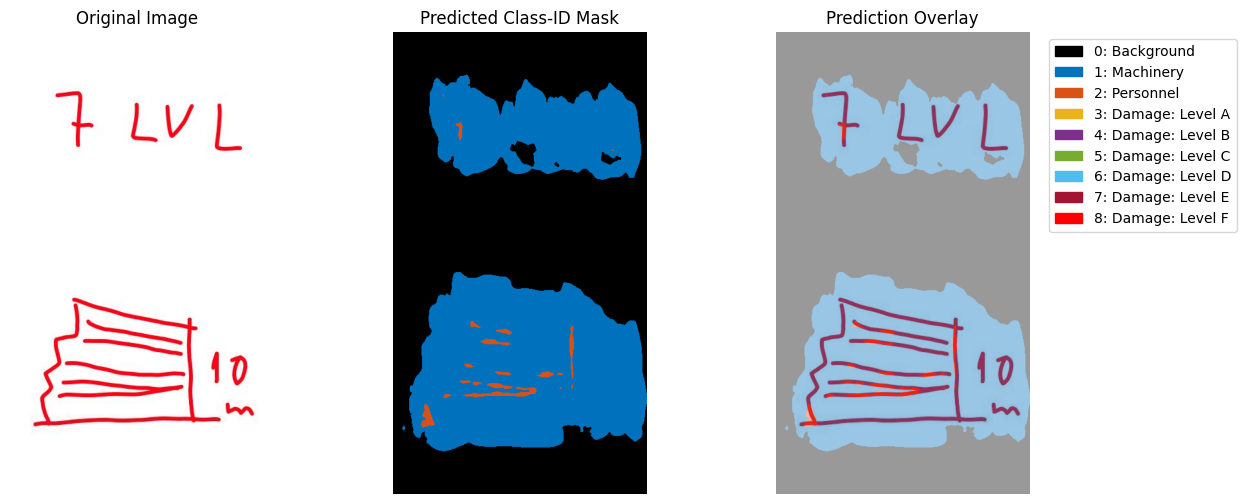

Saved raw mask:      /content/segformer_runtime_checkpoints/inference_outputs/pred_mask_ids_BEE0083B-0D0E-4382-8CCE-C00193BE314D.png
Saved colored mask:  /content/segformer_runtime_checkpoints/inference_outputs/pred_mask_color_BEE0083B-0D0E-4382-8CCE-C00193BE314D.png
Saved overlay:       /content/segformer_runtime_checkpoints/inference_outputs/pred_overlay_BEE0083B-0D0E-4382-8CCE-C00193BE314D.png


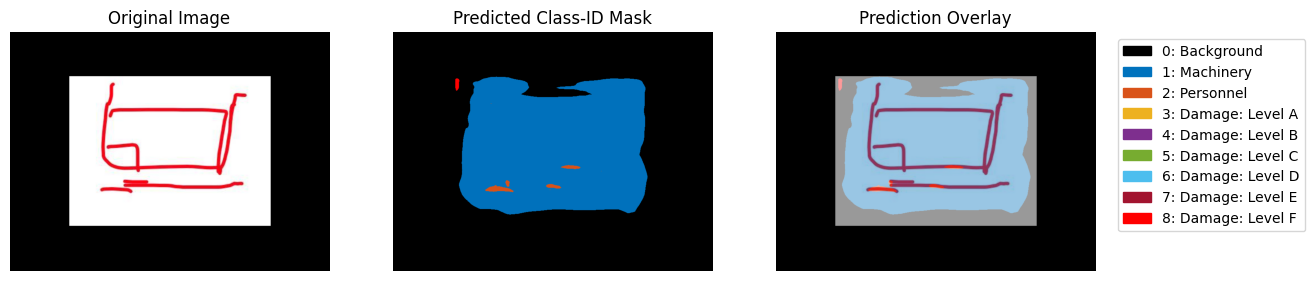

Saved raw mask:      /content/segformer_runtime_checkpoints/inference_outputs/pred_mask_ids_212216A8-1FF2-488A-9FA6-0827660C6CE2.png
Saved colored mask:  /content/segformer_runtime_checkpoints/inference_outputs/pred_mask_color_212216A8-1FF2-488A-9FA6-0827660C6CE2.png
Saved overlay:       /content/segformer_runtime_checkpoints/inference_outputs/pred_overlay_212216A8-1FF2-488A-9FA6-0827660C6CE2.png


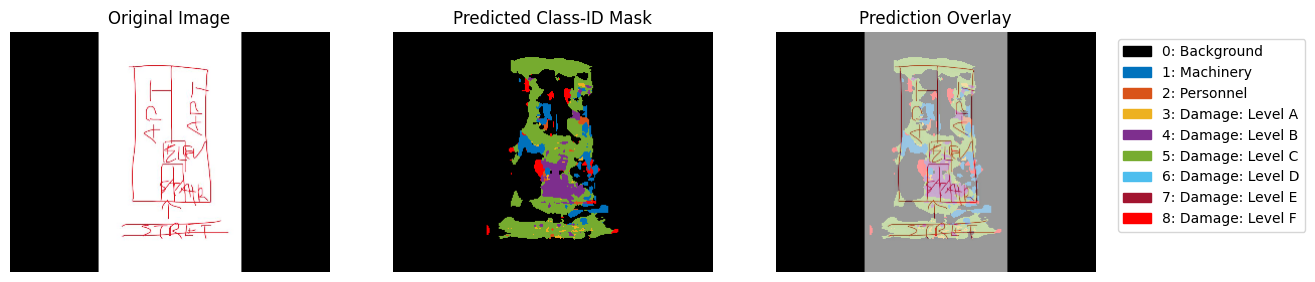

Saved raw mask:      /content/segformer_runtime_checkpoints/inference_outputs/pred_mask_ids_9AB8059A-C322-414D-8B9F-1DD889B61969.png
Saved colored mask:  /content/segformer_runtime_checkpoints/inference_outputs/pred_mask_color_9AB8059A-C322-414D-8B9F-1DD889B61969.png
Saved overlay:       /content/segformer_runtime_checkpoints/inference_outputs/pred_overlay_9AB8059A-C322-414D-8B9F-1DD889B61969.png


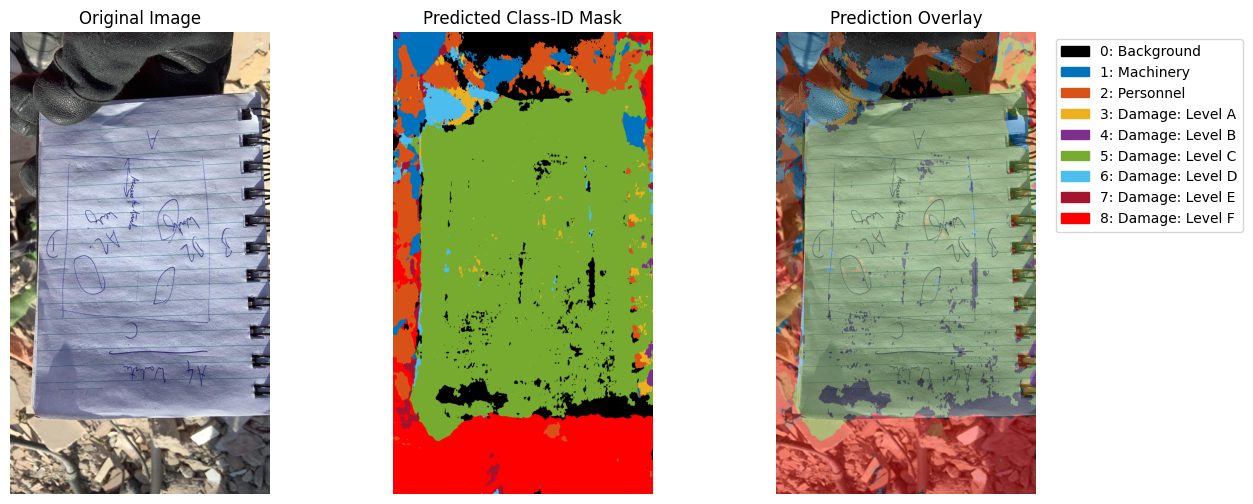

Saved raw mask:      /content/segformer_runtime_checkpoints/inference_outputs/pred_mask_ids_09B0A8BE-FC31-4BCD-9286-E6C3D6D4E400.png
Saved colored mask:  /content/segformer_runtime_checkpoints/inference_outputs/pred_mask_color_09B0A8BE-FC31-4BCD-9286-E6C3D6D4E400.png
Saved overlay:       /content/segformer_runtime_checkpoints/inference_outputs/pred_overlay_09B0A8BE-FC31-4BCD-9286-E6C3D6D4E400.png


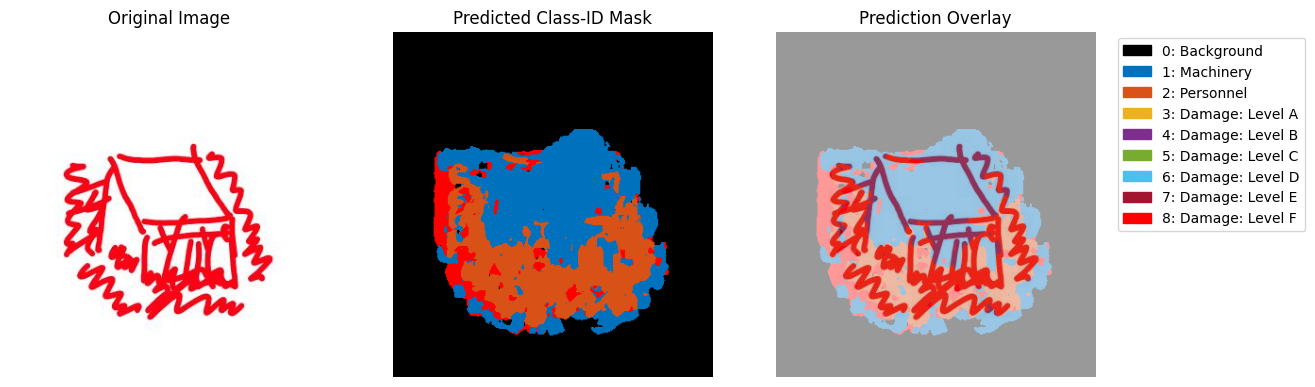

Saved raw mask:      /content/segformer_runtime_checkpoints/inference_outputs/pred_mask_ids_4FB04A3B-5B94-45C9-9F88-F5C7BD978EC0.png
Saved colored mask:  /content/segformer_runtime_checkpoints/inference_outputs/pred_mask_color_4FB04A3B-5B94-45C9-9F88-F5C7BD978EC0.png
Saved overlay:       /content/segformer_runtime_checkpoints/inference_outputs/pred_overlay_4FB04A3B-5B94-45C9-9F88-F5C7BD978EC0.png


KeyboardInterrupt: 

In [ ]:
import cv2
from PIL import UnidentifiedImageError

os.makedirs(INFERENCE_DIR, exist_ok=True)

for img_path in unlabeled_files:
    try:
        image_np, mask = perform_segmentation(
            img_path,
            model,
            preprocessing,
            device
        )

        if image_np is None or mask is None:
            print(f"Skipping image {img_path} due to error.")
            continue

    except UnidentifiedImageError:
        print(f"Skipping file {img_path} because it cannot be identified as an image.")
        continue

    except Exception as e:
        print(f"Skipping file {img_path} because of error: {e}")
        continue

    basename = os.path.basename(img_path)
    name_no_ext = os.path.splitext(basename)[0]

    # Save raw class-ID mask
    raw_mask_path = os.path.join(INFERENCE_DIR, f"pred_mask_ids_{name_no_ext}.png")
    cv2.imwrite(raw_mask_path, mask.astype(np.uint8))

    # Create colored mask
    color_array = np.array(colors)

    # Convert colors from 0–1 to 0–255
    color_array_255 = (color_array * 255).astype(np.uint8)

    colored_mask = color_array_255[mask]

    colored_mask_path = os.path.join(INFERENCE_DIR, f"pred_mask_color_{name_no_ext}.png")

    # cv2 saves in BGR, so convert RGB to BGR
    cv2.imwrite(colored_mask_path, cv2.cvtColor(colored_mask, cv2.COLOR_RGB2BGR))

    # Overlay
    overlay = (0.6 * image_np + 0.4 * colored_mask).astype(np.uint8)

    overlay_path = os.path.join(INFERENCE_DIR, f"pred_overlay_{name_no_ext}.png")
    cv2.imwrite(overlay_path, cv2.cvtColor(overlay, cv2.COLOR_RGB2BGR))

    # Display result
    plt.figure(figsize=(14, 6))

    plt.subplot(1, 3, 1)
    plt.imshow(image_np)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask, cmap=custom_cmap, vmin=0, vmax=num_classes - 1)
    plt.title("Predicted Class-ID Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title("Prediction Overlay")
    plt.axis("off")

    plt.legend(handles=patches, bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.show()

    print(f"Saved raw mask:      {raw_mask_path}")
    print(f"Saved colored mask:  {colored_mask_path}")
    print(f"Saved overlay:       {overlay_path}")

### 7.2 Examples from the validation set

The next cell goes through the validation images and keeps an image whenever its ground truth contains a class not yet covered, until all nine classes are covered. For each kept image it saves a figure with the photograph, the ground truth and the prediction. The first validation image already contains eight of the nine classes (all except triage category B). The loop was stopped by hand while it searched for an image with category B, so only this one figure was produced.

Comparison directory: /content/segformer_runtime_checkpoints/image_comparisons
Original image directory: /content/segformer_runtime_checkpoints/comparison_original_images
Ground-truth mask directory: /content/segformer_runtime_checkpoints/comparison_gt_masks
Raw prediction directory: /content/segformer_runtime_checkpoints/pred_masks_final/raw_class_id_masks
Colored prediction directory: /content/segformer_runtime_checkpoints/pred_masks_final/colored_masks
Overlay directory: /content/segformer_runtime_checkpoints/pred_masks_final/overlays
Number of validation pairs available: 53

Selected: 684586A6-5FE3-4604-9A55-31F094D3541B
GT classes: [0, 1, 2, 3, 5, 6, 7, 8]
Predicted classes: [0, 1, 3, 4, 5, 6, 7, 8]
New classes added: [0, 1, 2, 3, 5, 6, 7, 8]
Represented classes so far: [0, 1, 2, 3, 5, 6, 7, 8]


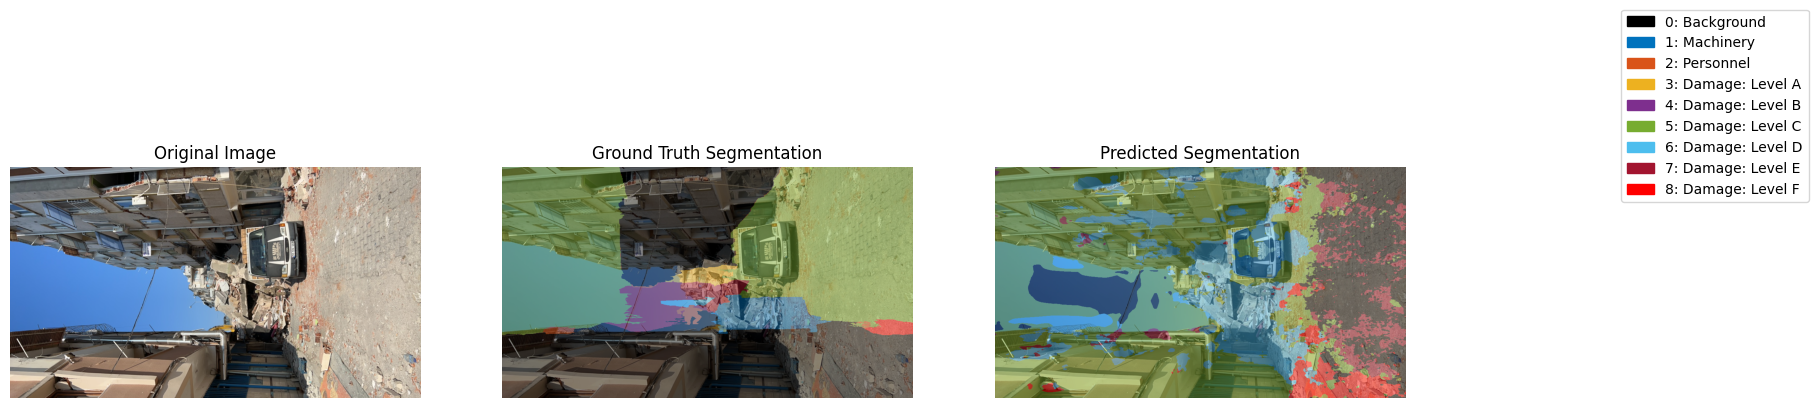

Saved comparison to: /content/segformer_runtime_checkpoints/image_comparisons/684586A6-5FE3-4604-9A55-31F094D3541B_comparison.png


KeyboardInterrupt: 

In [ ]:
import cv2
from PIL import UnidentifiedImageError

# Output directories
comparison_dir = os.path.join(OUTPUT_DIR, "image_comparisons")
pred_dir = os.path.join(OUTPUT_DIR, "pred_masks_final")

original_dir = os.path.join(OUTPUT_DIR, "comparison_original_images")
gt_dir = os.path.join(OUTPUT_DIR, "comparison_gt_masks")
pred_raw_dir = os.path.join(pred_dir, "raw_class_id_masks")
pred_colored_dir = os.path.join(pred_dir, "colored_masks")
overlay_dir = os.path.join(pred_dir, "overlays")

for d in [comparison_dir, original_dir, gt_dir, pred_raw_dir, pred_colored_dir, overlay_dir]:
    os.makedirs(d, exist_ok=True)

print("Comparison directory:", comparison_dir)
print("Original image directory:", original_dir)
print("Ground-truth mask directory:", gt_dir)
print("Raw prediction directory:", pred_raw_dir)
print("Colored prediction directory:", pred_colored_dir)
print("Overlay directory:", overlay_dir)

# Get validation pairs
# This handles either:
# - val_dataset.pairs
# - val_dataset as a PyTorch Subset of a dataset with .pairs

def get_pairs_from_dataset(dataset):
    if hasattr(dataset, "pairs"):
        return dataset.pairs

    if hasattr(dataset, "dataset") and hasattr(dataset.dataset, "pairs"):
        return [dataset.dataset.pairs[i] for i in dataset.indices]

    raise AttributeError(
        "Could not find image-mask pairs in val_dataset. "
        "Expected val_dataset.pairs or val_dataset.dataset.pairs."
    )

val_pairs = get_pairs_from_dataset(val_dataset)

print(f"Number of validation pairs available: {len(val_pairs)}")

# Settings
num_classes = 9
target_classes = set(range(num_classes))

# Stop once the selected examples together contain every ground-truth class
coverage_source = "ground_truth"  # options: "ground_truth", "prediction", "either"

represented_classes = set()
selected_examples = []

max_images_to_process = len(val_pairs)  # safety limit
alpha = 0.45                            # mask overlay transparency

# Helper functions
def resize_mask_nearest(mask, target_hw):
    """
    Resizes a class-ID mask using nearest-neighbor interpolation.
    This preserves integer class IDs.
    """
    target_h, target_w = target_hw

    if mask.shape[:2] == (target_h, target_w):
        return mask

    resized = cv2.resize(
        mask.astype(np.uint8),
        (target_w, target_h),
        interpolation=cv2.INTER_NEAREST
    )

    return resized

def mask_to_colored(mask, colors):
    """
    Converts a class-ID mask [H, W] to an RGB color mask [H, W, 3].
    """
    color_array = (np.array(colors) * 255).astype(np.uint8)
    return color_array[mask.astype(np.uint8)]

def get_classes_from_mask(mask):
    """
    Returns the set of class IDs present in a mask.
    """
    return set(np.unique(mask).astype(int).tolist())

# Loop through validation images until all classes are covered
for i, (img_path, gt_mask_path) in enumerate(val_pairs[:max_images_to_process]):

    if represented_classes == target_classes:
        print("\nAll classes have already been represented. Stopping.")
        break

    try:
        # Load original image
        image_pil = Image.open(img_path).convert("RGB")
        image_np = np.array(image_pil)
        original_h, original_w = image_np.shape[:2]

        # Load ground-truth mask
        gt_mask = np.array(Image.open(gt_mask_path))

        if gt_mask.ndim == 3:
            raise ValueError(
                f"Ground-truth mask is RGB/multi-channel: {gt_mask_path}. "
                "Expected class-ID mask."
            )

        gt_mask = gt_mask.astype(np.uint8)
        gt_mask = resize_mask_nearest(gt_mask, (original_h, original_w))

        # Run model prediction
        _, pred_mask = perform_segmentation(
            image_path=img_path,
            model=model,
            preprocessing=preprocessing,
            device=device
        )

        if image_np is None or pred_mask is None:
            print(f"Skipping image {img_path} due to invalid model output.")
            continue

        pred_mask = pred_mask.astype(np.uint8)
        pred_mask = resize_mask_nearest(pred_mask, (original_h, original_w))

    except UnidentifiedImageError:
        print(f"Skipping file {img_path}: cannot identify as image.")
        continue

    except Exception as e:
        print(f"Skipping file {img_path} due to error: {e}")
        continue

    # Determine whether this image adds new class coverage
    gt_classes = get_classes_from_mask(gt_mask)
    pred_classes = get_classes_from_mask(pred_mask)

    if coverage_source == "ground_truth":
        classes_for_coverage = gt_classes
    elif coverage_source == "prediction":
        classes_for_coverage = pred_classes
    elif coverage_source == "either":
        classes_for_coverage = gt_classes.union(pred_classes)
    else:
        raise ValueError("coverage_source must be 'ground_truth', 'prediction', or 'either'.")

    new_classes = classes_for_coverage - represented_classes

    # Skip images that do not add any new class.
    if len(new_classes) == 0:
        continue

    represented_classes.update(new_classes)

    filename = os.path.splitext(os.path.basename(img_path))[0]
    selected_examples.append({
        "filename": filename,
        "image_path": img_path,
        "gt_mask_path": gt_mask_path,
        "gt_classes": sorted(gt_classes),
        "pred_classes": sorted(pred_classes),
        "new_classes_added": sorted(new_classes),
        "represented_classes_so_far": sorted(represented_classes)
    })

    print("\nSelected:", filename)
    print("GT classes:", sorted(gt_classes))
    print("Predicted classes:", sorted(pred_classes))
    print("New classes added:", sorted(new_classes))
    print("Represented classes so far:", sorted(represented_classes))

    # Create colored masks and overlays
    gt_colored = mask_to_colored(gt_mask, colors)
    pred_colored = mask_to_colored(pred_mask, colors)

    gt_overlay = ((1 - alpha) * image_np + alpha * gt_colored).astype(np.uint8)
    pred_overlay = ((1 - alpha) * image_np + alpha * pred_colored).astype(np.uint8)

    # Save original image, GT mask, predicted mask, and overlays
    Image.fromarray(image_np).save(
        os.path.join(original_dir, f"{filename}.png")
    )

    Image.fromarray(gt_mask).save(
        os.path.join(gt_dir, f"{filename}_gt_mask_ids.png")
    )

    Image.fromarray(pred_mask).save(
        os.path.join(pred_raw_dir, f"{filename}_pred_mask_ids.png")
    )

    cv2.imwrite(
        os.path.join(pred_colored_dir, f"{filename}_pred_colored.png"),
        cv2.cvtColor(pred_colored, cv2.COLOR_RGB2BGR)
    )

    cv2.imwrite(
        os.path.join(overlay_dir, f"{filename}_gt_overlay.png"),
        cv2.cvtColor(gt_overlay, cv2.COLOR_RGB2BGR)
    )

    cv2.imwrite(
        os.path.join(overlay_dir, f"{filename}_pred_overlay.png"),
        cv2.cvtColor(pred_overlay, cv2.COLOR_RGB2BGR)
    )

    # Create and save side-by-side comparison figure
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    axes[0].imshow(image_np)
    axes[0].set_title("Original Image")
    axes[0].axis("off")

    axes[1].imshow(image_np)
    axes[1].imshow(gt_mask, cmap=custom_cmap, alpha=alpha, vmin=0, vmax=num_classes - 1)
    axes[1].set_title("Ground Truth Segmentation")
    axes[1].axis("off")

    axes[2].imshow(image_np)
    axes[2].imshow(pred_mask, cmap=custom_cmap, alpha=alpha, vmin=0, vmax=num_classes - 1)
    axes[2].set_title("Predicted Segmentation")
    axes[2].axis("off")

    fig.legend(
        handles=patches,
        bbox_to_anchor=(1.02, 0.95),
        loc="upper left",
        borderaxespad=0
    )

    comparison_path = os.path.join(comparison_dir, f"{filename}_comparison.png")
    plt.savefig(comparison_path, bbox_inches="tight", pad_inches=0.1, dpi=300)
    plt.show()
    plt.close(fig)

    print(f"Saved comparison to: {comparison_path}")

# Save selected-example summary
summary_df = pd.DataFrame(selected_examples)

summary_csv_path = os.path.join(comparison_dir, "selected_comparison_examples_summary.csv")
summary_df.to_csv(summary_csv_path, index=False)

print("\n============================================================")
print("Selection complete")
print("============================================================")
print("Represented classes:", sorted(represented_classes))
print("Missing classes:", sorted(target_classes - represented_classes))
print("Number of selected examples:", len(selected_examples))
print("Saved summary CSV to:", summary_csv_path)

## 8. Pixel-level evaluation

### 8.1 IoU per class

For each of the 59 test images, the predicted mask (at the original image size) is compared with the ground-truth mask; if their sizes differ, the ground truth is resized to the prediction by nearest-neighbour interpolation. For every class, the intersection over union |P ∩ G| / |P ∪ G| is computed per image, where P and G are the predicted and true pixels of that class, and is left undefined if the class occurs in neither mask. The per-class IoU reported is the mean over the images where it is defined, and the mean IoU is the mean of the nine per-class values.

The cell also prints "Mean Pixel Accuracy". In the code (`compute_pixel_accuracy`) this is, for each image, the fraction of all its pixels whose predicted class equals the true class, averaged over the 59 test images. Within an image every pixel counts equally, so this value is dominated by the classes that cover most of the image, mainly background. It is not the 56% overall accuracy reported in the manuscript, which is defined from the confusion matrix in Section 8.2.

In [ ]:
import cv2

# Settings
num_classes = NUM_CLASSES

class_names = {
    0: "Background",
    1: "Machinery",
    2: "Personnel",
    3: "Damage: Level A",
    4: "Damage: Level B",
    5: "Damage: Level C",
    6: "Damage: Level D",
    7: "Damage: Level E",
    8: "Damage: Level F",
}

priority_classes = DAMAGE_CLASSES

# Output directory
metrics_dir = METRICS_DIR

os.makedirs(metrics_dir, exist_ok=True)

print("Metrics directory:", metrics_dir)

# Load best model if available
possible_best_paths = [os.path.join(OUTPUT_DIR, "best_model.pt")]
if DRIVE_CHECKPOINT_DIR is not None:
    possible_best_paths.append(os.path.join(DRIVE_CHECKPOINT_DIR, "best_model.pt"))

best_model_path = None

for path in possible_best_paths:
    if os.path.exists(path):
        best_model_path = path
        break

if best_model_path is not None:
    checkpoint = torch.load(best_model_path, map_location=device)

    if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
        model.load_state_dict(checkpoint["model_state_dict"])
        print(f"Loaded best model checkpoint from: {best_model_path}")
        print(f"Best checkpoint epoch: {checkpoint.get('epoch', 'unknown')}")
        print(f"Best validation loss: {checkpoint.get('best_val_loss', 'unknown')}")
    else:
        model.load_state_dict(checkpoint)
        print(f"Loaded model state_dict from: {best_model_path}")
else:
    print("Warning: best_model.pt not found. Using model currently in memory.")

model.eval()

# Get test pairs
def get_pairs_from_dataset(dataset):
    if hasattr(dataset, "pairs"):
        return dataset.pairs

    if hasattr(dataset, "dataset") and hasattr(dataset.dataset, "pairs"):
        return [dataset.dataset.pairs[i] for i in dataset.indices]

    raise AttributeError(
        "Could not find image-mask pairs. Expected dataset.pairs "
        "or dataset.dataset.pairs if using a PyTorch Subset."
    )

test_pairs = get_pairs_from_dataset(test_dataset)

print("Number of test images:", len(test_pairs))

# Helper functions
def resize_mask_nearest(mask, target_shape):
    """
    Resize class-ID mask safely using nearest-neighbor interpolation.
    target_shape should be (height, width).
    """
    target_h, target_w = target_shape

    if mask.shape[:2] == (target_h, target_w):
        return mask

    return cv2.resize(
        mask.astype(np.uint8),
        (target_w, target_h),
        interpolation=cv2.INTER_NEAREST
    )

def compute_iou(pred_mask, gt_mask, num_classes):
    """
    Compute IoU for each class for a single image.
    Returns a list of IoUs for each class.
    """

    if pred_mask.shape != gt_mask.shape:
        raise ValueError(
            f"Shape mismatch after resizing: pred={pred_mask.shape}, gt={gt_mask.shape}"
        )

    iou_list = []

    for cls in range(num_classes):
        pred_cls = pred_mask == cls
        gt_cls = gt_mask == cls

        intersection = np.logical_and(pred_cls, gt_cls).sum()
        union = np.logical_or(pred_cls, gt_cls).sum()

        if union == 0:
            iou = np.nan
        else:
            iou = intersection / union

        iou_list.append(iou)

    return iou_list

def compute_pixel_accuracy(pred_mask, gt_mask):
    if pred_mask.shape != gt_mask.shape:
        raise ValueError(
            f"Shape mismatch: pred={pred_mask.shape}, gt={gt_mask.shape}"
        )

    return (pred_mask == gt_mask).sum() / gt_mask.size

# Run test evaluation
all_ious = []
per_image_rows = []

for idx, (img_path, gt_mask_path) in enumerate(test_pairs):

    # Load ground-truth mask
    gt_mask = np.array(Image.open(gt_mask_path))

    if gt_mask.ndim == 3:
        raise ValueError(
            f"GT mask is RGB/multi-channel, expected class-ID mask: {gt_mask_path}"
        )

    gt_mask = gt_mask.astype(np.uint8)

    # Compute prediction
    _, pred_mask = perform_segmentation(
        img_path,
        model,
        preprocessing,
        device
    )

    if pred_mask is None:
        print(f"Skipping {img_path}: prediction failed.")
        continue

    pred_mask = pred_mask.astype(np.uint8)

    # Make GT and prediction same size safely
    if gt_mask.shape != pred_mask.shape:
        gt_mask = resize_mask_nearest(gt_mask, pred_mask.shape)

    # Compute metrics
    ious = compute_iou(pred_mask, gt_mask, num_classes)
    pixel_acc = compute_pixel_accuracy(pred_mask, gt_mask)

    all_ious.append(ious)

    row = {
        "image_index": idx,
        "filename": os.path.basename(img_path),
        "pixel_accuracy": pixel_acc,
    }

    for cls in range(num_classes):
        row[f"IoU_class_{cls}_{class_names[cls]}"] = ious[cls]

    per_image_rows.append(row)

    if (idx + 1) % 10 == 0:
        print(f"Processed {idx + 1}/{len(test_pairs)} test images")

# Summarize results
all_ious = np.array(all_ious, dtype=float)

if all_ious.size == 0:
    raise ValueError("No valid IoU results were computed.")

mean_iou_per_class = np.nanmean(all_ious, axis=0)
overall_mean_iou = np.nanmean(mean_iou_per_class)
priority_mean_iou = np.nanmean(mean_iou_per_class[priority_classes])

per_image_df = pd.DataFrame(per_image_rows)

overall_pixel_accuracy = per_image_df["pixel_accuracy"].mean()

print("\n============================================================")
print("TEST SET RESULTS")
print("============================================================")

print("\nMean IoU per class:")
for cls, iou in enumerate(mean_iou_per_class):
    print(f"Class {cls} ({class_names[cls]}): {iou:.4f}")

print("\nOverall Mean IoU:", round(float(overall_mean_iou), 4))
print("Priority Classes 3–8 Mean IoU:", round(float(priority_mean_iou), 4))
print("Mean Pixel Accuracy:", round(float(overall_pixel_accuracy), 4))

# Save results
per_class_df = pd.DataFrame({
    "class_id": list(range(num_classes)),
    "class_name": [class_names[c] for c in range(num_classes)],
    "mean_iou": mean_iou_per_class,
    "is_priority_class": [c in priority_classes for c in range(num_classes)]
})

per_class_path = os.path.join(metrics_dir, "test_mean_iou_per_class.csv")
per_image_path = os.path.join(metrics_dir, "test_iou_per_image.csv")

per_class_df.to_csv(per_class_path, index=False)
per_image_df.to_csv(per_image_path, index=False)

print("\nSaved per-class IoU to:", per_class_path)
print("Saved per-image IoU to:", per_image_path)

Metrics directory: /content/segformer_runtime_checkpoints/metrics
Loaded best model checkpoint from: /content/segformer_runtime_checkpoints/best_model.pt
Best checkpoint epoch: 21
Best validation loss: 1.5626950349126543
Number of test images: 59
Processed 10/59 test images
Processed 20/59 test images
Processed 30/59 test images
Processed 40/59 test images
Processed 50/59 test images

TEST SET RESULTS

Mean IoU per class:
Class 0 (Background): 0.5059
Class 1 (Machinery): 0.1645
Class 2 (Personnel): 0.2039
Class 3 (Damage: Level A): 0.1071
Class 4 (Damage: Level B): 0.0209
Class 5 (Damage: Level C): 0.0815
Class 6 (Damage: Level D): 0.0876
Class 7 (Damage: Level E): 0.1046
Class 8 (Damage: Level F): 0.2456

Overall Mean IoU: 0.1691
Priority Classes 3–8 Mean IoU: 0.1079
Mean Pixel Accuracy: 0.5025

Saved per-class IoU to: /content/segformer_runtime_checkpoints/metrics/test_mean_iou_per_class.csv
Saved per-image IoU to: /content/segformer_runtime_checkpoints/metrics/test_iou_per_image.csv

In [ ]:
save_dir = METRICS_DIR

os.makedirs(save_dir, exist_ok=True)

# Save full per-image/per-class IoU array
all_ious_path = os.path.join(save_dir, "test_all_ious.npy")
np.save(all_ious_path, all_ious)

# Save mean IoU per class
mean_iou_per_class_path = os.path.join(save_dir, "test_mean_iou_per_class.npy")
np.save(mean_iou_per_class_path, mean_iou_per_class)

# Save overall mean IoU as text
overall_mean_iou_path = os.path.join(save_dir, "test_overall_mean_iou.txt")
with open(overall_mean_iou_path, "w") as f:
    f.write(f"Overall Mean IoU: {overall_mean_iou}\n")
    if "priority_mean_iou" in globals():
        f.write(f"Priority Classes 3-8 Mean IoU: {priority_mean_iou}\n")
    if "overall_pixel_accuracy" in globals():
        f.write(f"Overall Pixel Accuracy: {overall_pixel_accuracy}\n")

print(f"Saved IoU NumPy/text outputs to: {save_dir}")
print("Saved:", all_ious_path)
print("Saved:", mean_iou_per_class_path)
print("Saved:", overall_mean_iou_path)

Saved IoU NumPy/text outputs to: /content/segformer_runtime_checkpoints/metrics
Saved: /content/segformer_runtime_checkpoints/metrics/test_all_ious.npy
Saved: /content/segformer_runtime_checkpoints/metrics/test_mean_iou_per_class.npy
Saved: /content/segformer_runtime_checkpoints/metrics/test_overall_mean_iou.txt


### 8.2 Confusion matrix

The pixel-level confusion matrix counts, over all pixels of the 59 test images, how often a pixel of each true class (rows) was predicted as each class (columns). In the row-normalised version each row sums to 1, so the diagonal is the fraction of each class's pixels that is labelled correctly (its recall), and the off-diagonal entries show where the remaining pixels went. The first cell computes both matrices and saves them as CSV; the second plots the row-normalised matrix as a heatmap, which is Figure 5 of the manuscript.

In [ ]:
import json
import shutil
import cv2
from sklearn.metrics import confusion_matrix

# Settings
num_classes = NUM_CLASSES

class_names = {
    0: "Background",
    1: "Machinery",
    2: "Personnel",
    3: "Damage A",
    4: "Damage B",
    5: "Damage C",
    6: "Damage D",
    7: "Damage E",
    8: "Damage F",
}

eval_split_name = "Test"
eval_dataset = test_dataset

# Output directory
confusion_dir = METRICS_DIR

os.makedirs(confusion_dir, exist_ok=True)

print("Confusion matrix output directory:", confusion_dir)

# Get test image-mask pairs
def get_pairs_from_dataset(dataset):
    """
    Returns image-mask pairs from either:
    - custom BuildingDataset with .pairs
    - PyTorch Subset of a dataset with .pairs
    """
    if hasattr(dataset, "pairs"):
        return dataset.pairs

    if hasattr(dataset, "dataset") and hasattr(dataset.dataset, "pairs"):
        return [dataset.dataset.pairs[i] for i in dataset.indices]

    raise AttributeError(
        "Could not find image-mask pairs. Expected dataset.pairs "
        "or dataset.dataset.pairs if using a PyTorch Subset."
    )

test_pairs = get_pairs_from_dataset(eval_dataset)

print(f"Evaluating {eval_split_name} set")
print("Number of test images:", len(test_pairs))

# Helper functions
def resize_mask_nearest(mask, target_shape):
    """
    Resize class-ID mask safely using nearest-neighbor interpolation.
    target_shape should be (height, width).
    """
    target_h, target_w = target_shape

    if mask.shape[:2] == (target_h, target_w):
        return mask

    return cv2.resize(
        mask.astype(np.uint8),
        (target_w, target_h),
        interpolation=cv2.INTER_NEAREST
    )

def update_confusion_matrix(cm_total, gt_mask, pred_mask, num_classes):
    """
    Updates a pixel-level confusion matrix.

    Rows = ground-truth classes
    Columns = predicted classes
    """
    if gt_mask.shape != pred_mask.shape:
        raise ValueError(
            f"Shape mismatch: gt={gt_mask.shape}, pred={pred_mask.shape}"
        )

    valid = (gt_mask >= 0) & (gt_mask < num_classes)

    gt_flat = gt_mask[valid].astype(np.int64).ravel()
    pred_flat = pred_mask[valid].astype(np.int64).ravel()

    cm = confusion_matrix(
        gt_flat,
        pred_flat,
        labels=list(range(num_classes))
    )

    cm_total += cm

    return cm_total

# Compute pixel-level confusion matrix
cm_total = np.zeros((num_classes, num_classes), dtype=np.int64)

num_processed = 0
num_skipped = 0

for idx, (img_path, gt_mask_path) in enumerate(test_pairs):
    try:
        # Load ground-truth class-ID mask
        gt_mask = np.array(Image.open(gt_mask_path))

        if gt_mask.ndim == 3:
            raise ValueError(
                f"Ground-truth mask is RGB/multi-channel, expected 2D class-ID mask: {gt_mask_path}"
            )

        gt_mask = gt_mask.astype(np.uint8)

        if gt_mask.min() < 0 or gt_mask.max() >= num_classes:
            raise ValueError(
                f"Unexpected GT mask values in {gt_mask_path}: "
                f"min={gt_mask.min()}, max={gt_mask.max()}"
            )

        # Predicted mask at original image size
        _, pred_mask = perform_segmentation(
            img_path,
            model,
            preprocessing,
            device
        )

        if pred_mask is None:
            print(f"Skipping {img_path}: prediction failed.")
            num_skipped += 1
            continue

        pred_mask = pred_mask.astype(np.uint8)

        # Match GT mask size to predicted mask size if needed
        if gt_mask.shape != pred_mask.shape:
            gt_mask = resize_mask_nearest(gt_mask, pred_mask.shape)

        # Update confusion matrix
        cm_total = update_confusion_matrix(
            cm_total=cm_total,
            gt_mask=gt_mask,
            pred_mask=pred_mask,
            num_classes=num_classes
        )

        num_processed += 1

        if (idx + 1) % 10 == 0:
            print(f"Processed {idx + 1}/{len(test_pairs)} test images")

    except Exception as e:
        print(f"Skipping {img_path} due to error: {e}")
        num_skipped += 1
        continue

print("\nFinished confusion matrix calculation.")
print("Images processed:", num_processed)
print("Images skipped:", num_skipped)

# Convert to readable DataFrames
cm_df = pd.DataFrame(
    cm_total,
    index=[f"GT {i}: {class_names[i]}" for i in range(num_classes)],
    columns=[f"Pred {i}: {class_names[i]}" for i in range(num_classes)]
)

# Row-normalized confusion matrix:
# Each row sums to 1, so it answers:
# "Of all true pixels of this class, what fraction was predicted as each class?"
row_sums = cm_total.sum(axis=1, keepdims=True)

cm_normalized = np.divide(
    cm_total,
    row_sums,
    out=np.zeros_like(cm_total, dtype=float),
    where=row_sums != 0
)

cm_normalized_df = pd.DataFrame(
    cm_normalized,
    index=[f"GT {i}: {class_names[i]}" for i in range(num_classes)],
    columns=[f"Pred {i}: {class_names[i]}" for i in range(num_classes)]
)

print("\nRaw pixel-level confusion matrix:")
display(cm_df)

print("\nRow-normalized confusion matrix:")
display(cm_normalized_df.round(4))

# Save outputs
raw_cm_path = os.path.join(confusion_dir, "test_confusion_matrix_raw_pixels.csv")
norm_cm_path = os.path.join(confusion_dir, "test_confusion_matrix_row_normalized.csv")
summary_path = os.path.join(confusion_dir, "test_confusion_matrix_summary.json")

cm_df.to_csv(raw_cm_path)
cm_normalized_df.to_csv(norm_cm_path)

summary = {
    "eval_split_name": eval_split_name,
    "num_images_total": len(test_pairs),
    "num_images_processed": int(num_processed),
    "num_images_skipped": int(num_skipped),
    "num_classes": num_classes,
    "class_names": {str(k): v for k, v in class_names.items()},
    "raw_confusion_matrix_path": raw_cm_path,
    "row_normalized_confusion_matrix_path": norm_cm_path
}

with open(summary_path, "w") as f:
    json.dump(summary, f, indent=4)

print("\nSaved raw confusion matrix to:", raw_cm_path)
print("Saved row-normalized confusion matrix to:", norm_cm_path)
print("Saved summary to:", summary_path)

# Copy to Google Drive if mirroring is on
if DRIVE_CHECKPOINT_DIR is not None:
    drive_metrics_dir = os.path.join(DRIVE_CHECKPOINT_DIR, "metrics")
    os.makedirs(drive_metrics_dir, exist_ok=True)

    for path in [raw_cm_path, norm_cm_path, summary_path]:
        dst_path = os.path.join(drive_metrics_dir, os.path.basename(path))
        shutil.copy2(path, dst_path)
        print("Copied to Drive:", dst_path)

Confusion matrix output directory: /content/segformer_runtime_checkpoints/metrics
Evaluating Test set
Number of test images: 59
Processed 10/59 test images
Processed 20/59 test images
Processed 30/59 test images
Processed 40/59 test images
Processed 50/59 test images

Finished confusion matrix calculation.
Images processed: 59
Images skipped: 0

Raw pixel-level confusion matrix:


,Pred 0: Background,Pred 1: Machinery,Pred 2: Personnel,Pred 3: Damage A,Pred 4: Damage B,Pred 5: Damage C,Pred 6: Damage D,Pred 7: Damage E,Pred 8: Damage F
GT 0: Background,49064371,1804946,1725302,1145704,1038607,3614826,1358231,1421084,3291476
GT 1: Machinery,59773,2497102,30514,7219,4516,44696,113736,105861,40753
GT 2: Personnel,20644,24293,883905,10436,2260,10338,72229,102445,111419
GT 3: Damage A,572278,88370,86468,8370548,985661,5745566,234524,62023,74556
GT 4: Damage B,48406,248220,6180,242375,505739,862573,21479,114495,4367
GT 5: Damage C,145714,40568,42072,56415,934956,2137801,302971,99208,516357
GT 6: Damage D,365349,71257,124480,3655,449528,1128746,2113339,1904749,803826
GT 7: Damage E,96768,68098,33448,68,53973,115159,548621,2344154,249208
GT 8: Damage F,758203,214096,185991,8904,205479,545592,1357275,2997618,5781920



Row-normalized confusion matrix:


,Pred 0: Background,Pred 1: Machinery,Pred 2: Personnel,Pred 3: Damage A,Pred 4: Damage B,Pred 5: Damage C,Pred 6: Damage D,Pred 7: Damage E,Pred 8: Damage F
GT 0: Background,0.7611,0.0280,0.0268,0.0178,0.0161,0.0561,0.0211,0.0220,0.0511
GT 1: Machinery,0.0206,0.8598,0.0105,0.0025,0.0016,0.0154,0.0392,0.0365,0.0140
GT 2: Personnel,0.0167,0.0196,0.7140,0.0084,0.0018,0.0084,0.0583,0.0828,0.0900
GT 3: Damage A,0.0353,0.0054,0.0053,0.5161,0.0608,0.3542,0.0145,0.0038,0.0046
GT 4: Damage B,0.0236,0.1209,0.0030,0.1180,0.2462,0.4200,0.0105,0.0557,0.0021
GT 5: Damage C,0.0341,0.0095,0.0098,0.0132,0.2186,0.4999,0.0709,0.0232,0.1208
GT 6: Damage D,0.0525,0.0102,0.0179,0.0005,0.0645,0.1621,0.3034,0.2735,0.1154
GT 7: Damage E,0.0276,0.0194,0.0095,0.0000,0.0154,0.0328,0.1563,0.6679,0.0710
GT 8: Damage F,0.0629,0.0178,0.0154,0.0007,0.0170,0.0453,0.1126,0.2487,0.4796



Saved raw confusion matrix to: /content/segformer_runtime_checkpoints/metrics/test_confusion_matrix_raw_pixels.csv
Saved row-normalized confusion matrix to: /content/segformer_runtime_checkpoints/metrics/test_confusion_matrix_row_normalized.csv
Saved summary to: /content/segformer_runtime_checkpoints/metrics/test_confusion_matrix_summary.json
Copied to Drive: /content/drive/MyDrive/segformer_checkpoints/metrics/test_confusion_matrix_raw_pixels.csv
Copied to Drive: /content/drive/MyDrive/segformer_checkpoints/metrics/test_confusion_matrix_row_normalized.csv
Copied to Drive: /content/drive/MyDrive/segformer_checkpoints/metrics/test_confusion_matrix_summary.json


Row-normalized confusion matrix:


,Background,Machinery,Personnel,Damage A,Damage B,Damage C,Damage D,Damage E,Damage F
Background,0.761,0.028,0.027,0.018,0.016,0.056,0.021,0.022,0.051
Machinery,0.021,0.860,0.011,0.002,0.002,0.015,0.039,0.036,0.014
Personnel,0.017,0.020,0.714,0.008,0.002,0.008,0.058,0.083,0.090
Damage A,0.035,0.005,0.005,0.516,0.061,0.354,0.014,0.004,0.005
Damage B,0.024,0.121,0.003,0.118,0.246,0.420,0.010,0.056,0.002
Damage C,0.034,0.009,0.010,0.013,0.219,0.500,0.071,0.023,0.121
Damage D,0.052,0.010,0.018,0.001,0.065,0.162,0.303,0.273,0.115
Damage E,0.028,0.019,0.010,0.000,0.015,0.033,0.156,0.668,0.071
Damage F,0.063,0.018,0.015,0.001,0.017,0.045,0.113,0.249,0.480


Saved normalized confusion matrix CSV to: /content/segformer_runtime_checkpoints/metrics/test_confusion_matrix_row_normalized_for_plot.csv


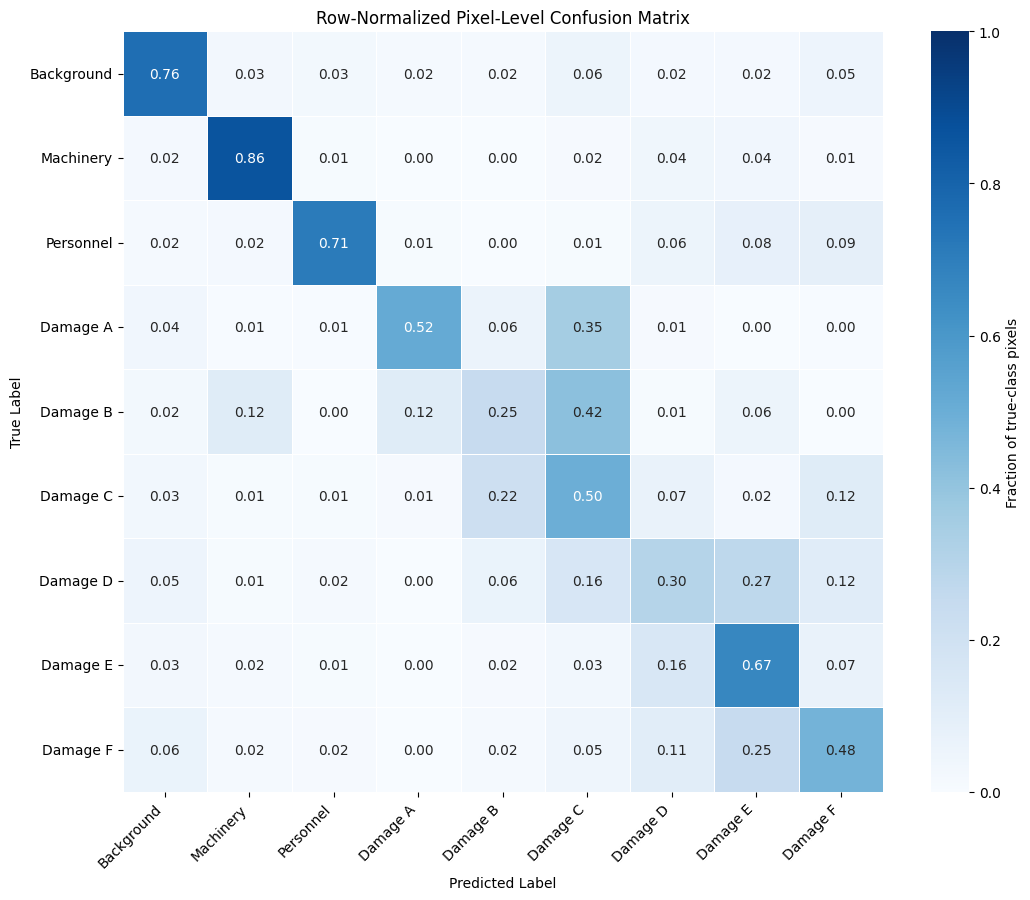

Saved confusion matrix heatmap to: /content/segformer_runtime_checkpoints/metrics/test_confusion_matrix_heatmap_normalized.png
Copied heatmap to Drive: /content/drive/MyDrive/segformer_checkpoints/metrics/test_confusion_matrix_heatmap_normalized.png
Copied CSV to Drive: /content/drive/MyDrive/segformer_checkpoints/metrics/test_confusion_matrix_row_normalized_for_plot.csv


In [ ]:
import shutil
import seaborn as sns

# Get confusion matrix
confusion_matrix_array = cm_total

# Settings
num_classes = NUM_CLASSES

class_names = {
    0: "Background",
    1: "Machinery",
    2: "Personnel",
    3: "Damage A",
    4: "Damage B",
    5: "Damage C",
    6: "Damage D",
    7: "Damage E",
    8: "Damage F",
}

class_labels = [class_names[i] for i in range(num_classes)]

# Row-normalize confusion matrix
# Rows = true labels
# Columns = predicted labels
#
# Row normalization answers:
# "For pixels truly belonging to this class, what fraction were predicted
# as each class?"

row_sums = confusion_matrix_array.sum(axis=1, keepdims=True)

cm_normalized = np.divide(
    confusion_matrix_array.astype(float),
    row_sums,
    out=np.zeros_like(confusion_matrix_array, dtype=float),
    where=row_sums != 0
)

cm_normalized_df = pd.DataFrame(
    cm_normalized,
    index=class_labels,
    columns=class_labels
)

print("Row-normalized confusion matrix:")
display(cm_normalized_df.round(3))

# Choose safe output directory
plot_dir = METRICS_DIR

os.makedirs(plot_dir, exist_ok=True)

plot_path = os.path.join(plot_dir, "test_confusion_matrix_heatmap_normalized.png")
csv_path = os.path.join(plot_dir, "test_confusion_matrix_row_normalized_for_plot.csv")

# Save normalized confusion matrix as CSV
cm_normalized_df.to_csv(csv_path)

print("Saved normalized confusion matrix CSV to:", csv_path)

# Plot heatmap
plt.figure(figsize=(11, 9))

sns.heatmap(
    cm_normalized_df,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Fraction of true-class pixels"}
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Row-Normalized Pixel-Level Confusion Matrix")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved confusion matrix heatmap to:", plot_path)

# Copy to Google Drive if mirroring is on
if DRIVE_CHECKPOINT_DIR is not None:

    drive_metrics_dir = os.path.join(DRIVE_CHECKPOINT_DIR, "metrics")
    os.makedirs(drive_metrics_dir, exist_ok=True)

    drive_plot_path = os.path.join(drive_metrics_dir, os.path.basename(plot_path))
    drive_csv_path = os.path.join(drive_metrics_dir, os.path.basename(csv_path))

    shutil.copy2(plot_path, drive_plot_path)
    shutil.copy2(csv_path, drive_csv_path)

    print("Copied heatmap to Drive:", drive_plot_path)
    print("Copied CSV to Drive:", drive_csv_path)

The manuscript reports an overall accuracy of 56% for this matrix. It is defined as the sum of the nine diagonal values of the row-normalised matrix divided by the number of classes, that is, the mean per-class recall over all nine classes including background, personnel and machinery. Each class has the same weight regardless of how many pixels it has in the test set. From the diagonal printed above (0.7611, 0.8598, 0.7140, 0.5161, 0.2462, 0.4999, 0.3034, 0.6679, 0.4796) this is 5.048 / 9 = 0.561. The next cell computes it from `cm_normalized`; it was added for this version and has no saved output. The value differs from the 0.5025 "Mean Pixel Accuracy" of Section 8.1, which weights every pixel equally within an image and is therefore dominated by background.

In [ ]:
# Overall accuracy as defined in the manuscript: mean of the diagonal of the
# row-normalised confusion matrix, i.e. mean per-class recall over all nine classes
overall_accuracy = np.diag(cm_normalized).mean()
print(f"Overall accuracy (mean per-class recall): {overall_accuracy:.3f}")

Background, machinery, personnel and triage category E are predicted with the highest accuracy: 76% of background pixels, 86% of machinery pixels, 71% of personnel pixels and 67% of category E pixels are labelled correctly. Categories B (25%) and D (30%) are the most confused, followed by F (48%), C (50%) and A (52%).

Confusion is mostly with neighbouring categories rather than with background. Among the lower categories, 42% of B pixels are predicted as C and 12% as A, 22% of C pixels as B, and 35% of A pixels as C. Among the higher categories, 27% of D pixels are predicted as E and 12% as F, 25% of F pixels as E and 11% as D, and 16% of E pixels as D. Errors across larger distances are less frequent; the largest are D predicted as C (16%) and C predicted as F (12%). Category B, the rarest class, is also predicted as machinery for 12% of its pixels. The manuscript notes that structural engineers themselves often disagree on categories B, C and D.

## 9. Image-level triage scores

To be operationally useful, and for the spatial analysis, each photograph needs a single triage score. `aggregate_mask` reduces a class mask to that score using only the triage pixels (IDs 3 to 8); the non-triage classes background, machinery and personnel are excluded, and an image without triage pixels would get NaN (this does not occur in the test set). It implements the two rules introduced in Section 3:

- `"mode"`: the triage category with the largest number of pixels (ties go to the lower category);
- `"weighted average"`: the pixel-weighted mean of the category IDs, a continuous score between 3 (A) and 8 (F), later converted to a class by rounding, flooring or ceiling.

The mode depends only on the largest category in the image, while the weighted average reflects the proportions of all categories. A weighted average can therefore fall on a category that does not occur in the image at all, which is why the manuscript notes that the mode may be the more useful rule operationally.

The next two cells apply both rules to the predicted masks and to the ground-truth masks of the 59 test images, attach the EXIF GPS coordinates, and save `pred_agg_test.csv` and `gt_agg_test.csv`. The predicted masks have the size of the original photographs, and the ground-truth masks are used as stored. Both scores depend only on pixel proportions, so a difference in size between the two does not matter.

In [ ]:
from scipy.stats import mode

def aggregate_mask(mask, method="mode", valid_labels=tuple(DAMAGE_CLASSES), no_damage_value=np.nan):
    """
    Aggregate a pixel-wise segmentation mask into one image-level damage score.

    Only damage-level classes are included:
        3 = Damage A
        4 = Damage B
        5 = Damage C
        6 = Damage D
        7 = Damage E
        8 = Damage F

    Non-damage classes are ignored:
        0 = Background
        1 = Machinery
        2 = Personnel

    Methods
    -------
    "mode":
        Returns the most frequent damage class.

    "weighted average":
        Returns the pixel-count weighted average of the damage class IDs:

            sum(class_id * number_of_pixels_in_class) / total_damage_pixels

    Returns
    -------
    int, float, or np.nan
        Aggregated image-level damage score.
    """

    if isinstance(mask, torch.Tensor):
        mask = mask.detach().cpu().numpy()

    mask = np.asarray(mask)

    if mask.ndim != 2:
        raise ValueError(
            f"Expected a 2D class-ID mask, but got shape {mask.shape}. "
            "If this is an RGB mask, convert it to class IDs first."
        )

    flat = mask.ravel()
    valid_labels = np.array(valid_labels)

    # Keep only A-F damage pixels
    flat_valid = flat[np.isin(flat, valid_labels)]

    if len(flat_valid) == 0:
        return no_damage_value

    if method == "mode":
        return int(mode(flat_valid, keepdims=True).mode[0])

    elif method == "weighted average":
        counts = np.array([
            np.sum(flat_valid == label)
            for label in valid_labels
        ])

        weighted_average = np.sum(valid_labels * counts) / np.sum(counts)

        return float(weighted_average)

    else:
        raise ValueError(
            "Unknown aggregation method. Choose 'mode' or 'weighted average'."
        )

In [ ]:
from PIL import ExifTags

output_dir = OUTPUT_DIR

os.makedirs(output_dir, exist_ok=True)

output_csv_path = os.path.join(output_dir, "pred_agg_test.csv")

print("Output CSV path:", output_csv_path)

# Get test image-mask pairs
def get_pairs_from_dataset(dataset):
    if hasattr(dataset, "pairs"):
        return dataset.pairs

    if hasattr(dataset, "dataset") and hasattr(dataset.dataset, "pairs"):
        return [dataset.dataset.pairs[i] for i in dataset.indices]

    raise AttributeError(
        "Could not find image-mask pairs. Expected dataset.pairs "
        "or dataset.dataset.pairs if using a PyTorch Subset."
    )

test_pairs = get_pairs_from_dataset(test_dataset)

print("Number of test pairs:", len(test_pairs))

# GPS extraction helpers
def rational_to_float(value):
    try:
        if isinstance(value, tuple):
            return float(value[0]) / float(value[1])
        return float(value)
    except Exception:
        return np.nan

def dms_to_decimal(dms, ref):
    degrees = rational_to_float(dms[0])
    minutes = rational_to_float(dms[1])
    seconds = rational_to_float(dms[2])

    decimal = degrees + minutes / 60.0 + seconds / 3600.0

    if ref in ["S", "W"]:
        decimal = -decimal

    return decimal

def extract_gps_coordinates(image_path):
    try:
        image = Image.open(image_path)
        exif_data = image._getexif()

        if not exif_data:
            return np.nan, np.nan

        exif = {
            ExifTags.TAGS.get(tag, tag): value
            for tag, value in exif_data.items()
        }

        gps_raw = exif.get("GPSInfo", None)

        if gps_raw is None:
            return np.nan, np.nan

        gps_info = {
            ExifTags.GPSTAGS.get(key, key): value
            for key, value in gps_raw.items()
        }

        latitude = gps_info.get("GPSLatitude")
        latitude_ref = gps_info.get("GPSLatitudeRef")
        longitude = gps_info.get("GPSLongitude")
        longitude_ref = gps_info.get("GPSLongitudeRef")

        if latitude is None or latitude_ref is None or longitude is None or longitude_ref is None:
            return np.nan, np.nan

        lat = dms_to_decimal(latitude, latitude_ref)
        lon = dms_to_decimal(longitude, longitude_ref)

        return lat, lon

    except Exception as e:
        print(f"GPS extraction failed for {image_path}: {e}")
        return np.nan, np.nan

# Predict and aggregate TEST images
pred_results = []

for idx, (img_path, gt_mask_path) in enumerate(test_pairs):
    try:
        image_np, pred_mask = perform_segmentation(
            image_path=img_path,
            model=model,
            preprocessing=preprocessing,
            device=device
        )

        if pred_mask is None:
            print(f"Skipping {img_path}: prediction failed.")
            continue

        pred_mask = pred_mask.astype(np.uint8)

        mode_value = aggregate_mask(pred_mask, method="mode")
        weighted_avg = aggregate_mask(pred_mask, method="weighted average")

        latitude, longitude = extract_gps_coordinates(img_path)

        pred_results.append({
            "Filename": os.path.basename(img_path),
            "Image Path": img_path,
            "GT Mask Path": gt_mask_path,
            "Latitude": latitude,
            "Longitude": longitude,
            "Mode": mode_value,
            "Weighted Average": weighted_avg,
            "Predicted Classes": sorted(np.unique(pred_mask).astype(int).tolist())
        })

        if (idx + 1) % 10 == 0:
            print(f"Processed {idx + 1}/{len(test_pairs)} test images")

    except Exception as e:
        print(f"Error processing image {img_path}: {e}")
        continue

# Convert to DataFrame and save
pred_test_df = pd.DataFrame(pred_results)

print("\nNumber of aggregated TEST predictions:", len(pred_test_df))
display(pred_test_df.head())

pred_test_df.to_csv(output_csv_path, index=False)

print("Saved TEST prediction aggregation CSV to:", output_csv_path)

# Copy to Google Drive if mirroring is on
if DRIVE_CHECKPOINT_DIR is not None:

    drive_csv_path = os.path.join(DRIVE_CHECKPOINT_DIR, "pred_agg_test.csv")
    shutil.copy2(output_csv_path, drive_csv_path)

    print("Copied TEST prediction aggregation CSV to Drive:", drive_csv_path)

Output CSV path: /content/segformer_runtime_checkpoints/pred_agg_test.csv
Number of test pairs: 59
Processed 10/59 test images
Processed 20/59 test images
Processed 30/59 test images
Processed 40/59 test images
Processed 50/59 test images

Number of aggregated TEST predictions: 59


,Filename,Image Path,GT Mask Path,Latitude,Longitude,Mode,Weighted Average,Predicted Classes
0,1A1C3737-55C9-4D47-80D8-71E9A3C90F97.jpg,/content/turkey_gt_images/1A1C3737-55C9-4D47-8...,/content/turkey_gt_masks/Label_292_1A1C3737-55...,36.495114,36.367932,6,6.827845,"[0, 1, 4, 5, 6, 7, 8]"
1,7E41172C-78FD-4402-9ECF-1583F236ACC3.jpg,/content/turkey_gt_images/7E41172C-78FD-4402-9...,/content/turkey_gt_masks/Label_167_7E41172C-78...,36.216541,36.154213,5,4.996574,"[0, 1, 3, 4, 5, 6, 8]"
2,DE318F6C-D145-4768-8B74-A395A7F008BF.jpg,/content/turkey_gt_images/DE318F6C-D145-4768-8...,/content/turkey_gt_masks/Label_48_DE318F6C-D14...,37.575219,36.933911,7,6.854686,"[0, 1, 2, 4, 5, 6, 7, 8]"
3,BA7A9046-BD7E-4862-850D-A9B2DE988431.jpg,/content/turkey_gt_images/BA7A9046-BD7E-4862-8...,/content/turkey_gt_masks/Label_96_BA7A9046-BD7...,37.574971,36.933431,6,6.268295,"[0, 1, 2, 4, 5, 6, 7, 8]"
4,F0EF1E9D-1E57-47FC-8439-244452934513.jpg,/content/turkey_gt_images/F0EF1E9D-1E57-47FC-8...,/content/turkey_gt_masks/Label_19_F0EF1E9D-1E5...,36.196455,36.160058,5,5.010029,"[0, 1, 3, 4, 5, 6, 7, 8]"


Saved TEST prediction aggregation CSV to: /content/segformer_runtime_checkpoints/pred_agg_test.csv
Copied TEST prediction aggregation CSV to Drive: /content/drive/MyDrive/segformer_checkpoints/pred_agg_test.csv


In [ ]:
output_dir = OUTPUT_DIR

os.makedirs(output_dir, exist_ok=True)

output_csv_path = os.path.join(output_dir, "gt_agg_test.csv")

print("Output CSV path:", output_csv_path)

# TEST image-mask pairs (get_pairs_from_dataset and the GPS helpers are defined above)

gt_pairs = get_pairs_from_dataset(test_dataset)

print("Number of TEST ground-truth pairs:", len(gt_pairs))

# TEST ground-truth aggregation

gt_results = []

for img_path, gt_mask_path in gt_pairs:
    try:
        gt_mask = np.array(Image.open(gt_mask_path))

        if gt_mask.ndim == 3:
            print(f"Skipping RGB/multi-channel mask: {gt_mask_path}")
            continue

        gt_mask = gt_mask.astype(np.uint8)

        mode_value = aggregate_mask(gt_mask, method="mode")
        weighted_avg = aggregate_mask(gt_mask, method="weighted average")

        latitude, longitude = extract_gps_coordinates(img_path)

        gt_results.append({
            "Filename": os.path.basename(img_path),
            "Image Path": img_path,
            "Mask Filename": os.path.basename(gt_mask_path),
            "Mask Path": gt_mask_path,
            "Latitude": latitude,
            "Longitude": longitude,
            "Mode": mode_value,
            "Weighted Average": weighted_avg,
            "GT Classes": sorted(np.unique(gt_mask).astype(int).tolist())
        })

    except Exception as e:
        print(
            f"Error processing pair:\n"
            f"Image: {img_path}\n"
            f"Mask: {gt_mask_path}\n"
            f"Error: {e}"
        )
        continue

# Convert to DataFrame and save
gt_test_df = pd.DataFrame(gt_results)

print("\nNumber of aggregated TEST ground-truth records:", len(gt_test_df))
display(gt_test_df.head())

gt_test_df.to_csv(output_csv_path, index=False)

print("Saved TEST ground-truth aggregation CSV to:", output_csv_path)

# Verify that gt_agg_test.csv matches test_dataset
test_filenames = set(os.path.basename(img_path) for img_path, _ in gt_pairs)
gt_csv_filenames = set(gt_test_df["Filename"].astype(str))

missing_from_gt_csv = sorted(test_filenames - gt_csv_filenames)
extra_in_gt_csv = sorted(gt_csv_filenames - test_filenames)

print("\nVerification:")
print("Number of images in test_dataset:", len(test_filenames))
print("Number of rows in gt_agg_test.csv:", len(gt_test_df))
print("Missing test images from GT CSV:", len(missing_from_gt_csv))
print("Extra GT rows not in test set:", len(extra_in_gt_csv))

if len(missing_from_gt_csv) == 0 and len(extra_in_gt_csv) == 0 and len(gt_test_df) == len(gt_pairs):
    print("✅ gt_agg_test.csv matches the TEST dataset exactly.")
else:
    print("⚠️ gt_agg_test.csv does not perfectly match the TEST dataset.")
    if missing_from_gt_csv:
        print("First missing examples:", missing_from_gt_csv[:10])
    if extra_in_gt_csv:
        print("First extra examples:", extra_in_gt_csv[:10])

# Copy to Google Drive if mirroring is on
if DRIVE_CHECKPOINT_DIR is not None:

    drive_csv_path = os.path.join(DRIVE_CHECKPOINT_DIR, "gt_agg_test.csv")
    shutil.copy2(output_csv_path, drive_csv_path)

    print("Copied TEST ground-truth aggregation CSV to Drive:", drive_csv_path)

Output CSV path: /content/segformer_runtime_checkpoints/gt_agg_test.csv
Number of TEST ground-truth pairs: 59

Number of aggregated TEST ground-truth records: 59


,Filename,Image Path,Mask Filename,Mask Path,Latitude,Longitude,Mode,Weighted Average,GT Classes
0,1A1C3737-55C9-4D47-80D8-71E9A3C90F97.jpg,/content/turkey_gt_images/1A1C3737-55C9-4D47-8...,Label_292_1A1C3737-55C9-4D47-80D8-71E9A3C90F97...,/content/turkey_gt_masks/Label_292_1A1C3737-55...,36.495114,36.367932,8,7.383109,"[0, 4, 6, 7, 8]"
1,7E41172C-78FD-4402-9ECF-1583F236ACC3.jpg,/content/turkey_gt_images/7E41172C-78FD-4402-9...,Label_167_7E41172C-78FD-4402-9ECF-1583F236ACC3...,/content/turkey_gt_masks/Label_167_7E41172C-78...,36.216541,36.154213,4,4.000000,"[0, 4]"
2,DE318F6C-D145-4768-8B74-A395A7F008BF.jpg,/content/turkey_gt_images/DE318F6C-D145-4768-8...,Label_48_DE318F6C-D145-4768-8B74-A395A7F008BF.png,/content/turkey_gt_masks/Label_48_DE318F6C-D14...,37.575219,36.933911,7,7.326547,"[0, 7, 8]"
3,BA7A9046-BD7E-4862-850D-A9B2DE988431.jpg,/content/turkey_gt_images/BA7A9046-BD7E-4862-8...,Label_96_BA7A9046-BD7E-4862-850D-A9B2DE988431.png,/content/turkey_gt_masks/Label_96_BA7A9046-BD7...,37.574971,36.933431,8,7.555524,"[0, 2, 7, 8]"
4,F0EF1E9D-1E57-47FC-8439-244452934513.jpg,/content/turkey_gt_images/F0EF1E9D-1E57-47FC-8...,Label_19_F0EF1E9D-1E57-47FC-8439-244452934513.png,/content/turkey_gt_masks/Label_19_F0EF1E9D-1E5...,36.196455,36.160058,5,5.000000,"[0, 5]"


Saved TEST ground-truth aggregation CSV to: /content/segformer_runtime_checkpoints/gt_agg_test.csv

Verification:
Number of images in test_dataset: 59
Number of rows in gt_agg_test.csv: 59
Missing test images from GT CSV: 0
Extra GT rows not in test set: 0
✅ gt_agg_test.csv matches the TEST dataset exactly.
Copied TEST ground-truth aggregation CSV to Drive: /content/drive/MyDrive/segformer_checkpoints/gt_agg_test.csv


## 10. Image-level evaluation

The next cell merges the ground-truth and predicted scores of the test images by image ID and saves the result as `merged_gt_pred_test_image_level_scores.csv`, the main input of notebook 02. Each score is then converted to a triage class in four ways (the mode directly, and the weighted average rounded, floored or ceiled), and the predicted class is compared with the ground-truth class obtained in the same way. For each rule the cell prints the class counts, the accuracy and the balanced accuracy (mean recall over the classes present in the ground truth), and plots and saves a row-normalised confusion matrix.

The "GT class counts" printed for the four rules are Table 3 of the manuscript (number of test-set images per ground-truth class for each aggregation function). The first heatmap (mode, balanced accuracy 0.43) is Figure 6 and the second (weighted average rounded, balanced accuracy 0.49) is Figure 7.

The original version of this cell contained a duplicated block of code that locates the input CSV files, which is why the first three lines of the saved output appear twice. The duplicate is kept so that the code matches the output; running it twice has no other effect.

Ground-truth test CSV: /content/drive/MyDrive/segformer_checkpoints/gt_agg_test.csv
Prediction test CSV:   /content/drive/MyDrive/segformer_checkpoints/pred_agg_test.csv
Evaluation output directory: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation
Ground-truth test CSV: /content/drive/MyDrive/segformer_checkpoints/gt_agg_test.csv
Prediction test CSV:   /content/drive/MyDrive/segformer_checkpoints/pred_agg_test.csv
Evaluation output directory: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation

GT rows: 59
Prediction rows: 59
Merged rows: 59
GT rows missing prediction: 0
Prediction rows missing GT: 0

Saved merged GT/pred table: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/merged_gt_pred_test_image_level_scores.csv

Test Image-Level Confusion Matrix: Mode Aggregation
Number of evaluated images: 59

GT class counts:
Mode_GT
3     8
4     2
5     7
6    10
7     4
8    28
Name: count, dtype: int64

Predicted class counts:
Mode_Pre

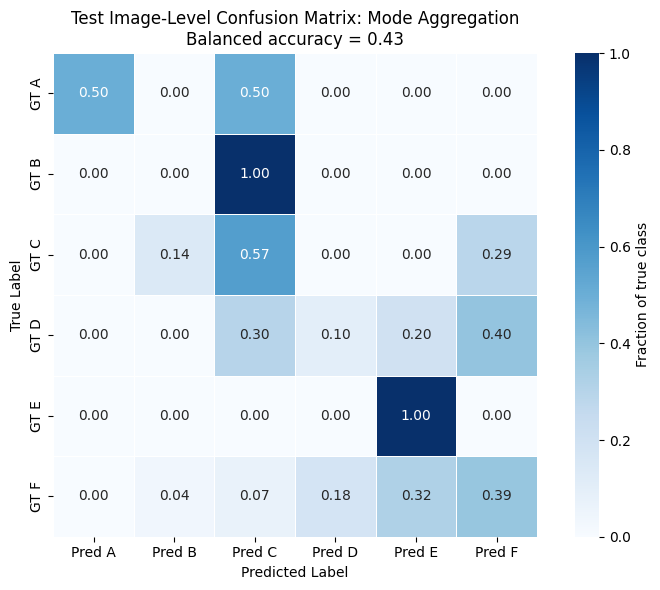

Saved raw confusion matrix: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/test_mode_confusion_raw.csv
Saved normalized confusion matrix: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/test_mode_confusion_row_normalized.csv
Saved heatmap: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/test_mode_confusion_heatmap.png

Test Image-Level Confusion Matrix: Weighted Average Rounded
Number of evaluated images: 59

GT class counts:
Weighted Average_GT
3     8
4     2
5     5
6    15
7    23
8     6
Name: count, dtype: int64

Predicted class counts:
Weighted Average_Pred
3     3
4     6
5     7
6    16
7    22
8     5
Name: count, dtype: int64

Accuracy: 0.5424
Balanced accuracy: 0.4896


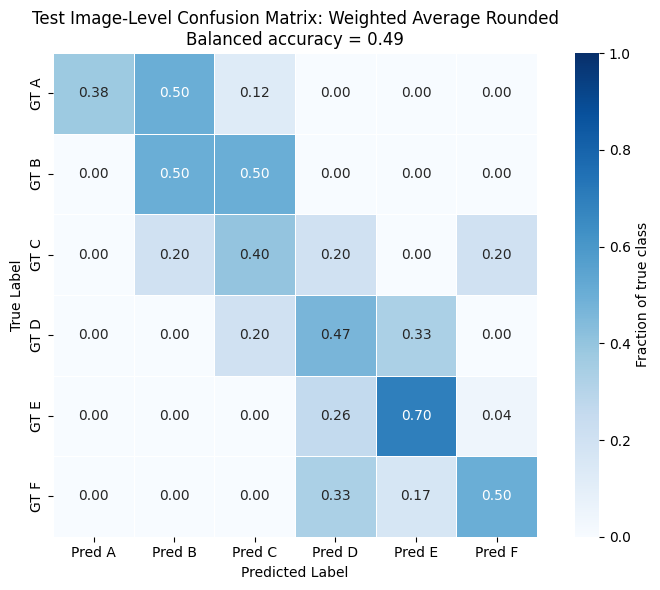

Saved raw confusion matrix: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/test_weighted_average_rounded_confusion_raw.csv
Saved normalized confusion matrix: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/test_weighted_average_rounded_confusion_row_normalized.csv
Saved heatmap: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/test_weighted_average_rounded_confusion_heatmap.png

Test Image-Level Confusion Matrix: Weighted Average Floored
Number of evaluated images: 59

GT class counts:
Weighted Average_GT
3     8
4     3
5     8
6    19
7    21
Name: count, dtype: int64

Predicted class counts:
Weighted Average_Pred
3     4
4     8
5     9
6    24
7    14
Name: count, dtype: int64

Accuracy: 0.5424
Balanced accuracy: 0.6265


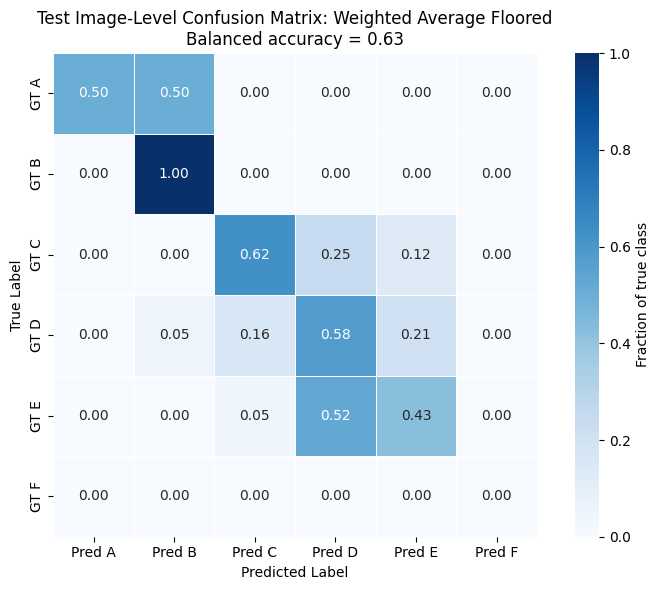

Saved raw confusion matrix: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/test_weighted_average_floored_confusion_raw.csv
Saved normalized confusion matrix: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/test_weighted_average_floored_confusion_row_normalized.csv
Saved heatmap: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/test_weighted_average_floored_confusion_heatmap.png

Test Image-Level Confusion Matrix: Weighted Average Ceiled
Number of evaluated images: 59

GT class counts:
Weighted Average_GT
3     8
4     2
5     3
6     6
7    19
8    21
Name: count, dtype: int64

Predicted class counts:
Weighted Average_Pred
4     4
5     8
6     9
7    24
8    14
Name: count, dtype: int64

Accuracy: 0.4237
Balanced accuracy: 0.3346


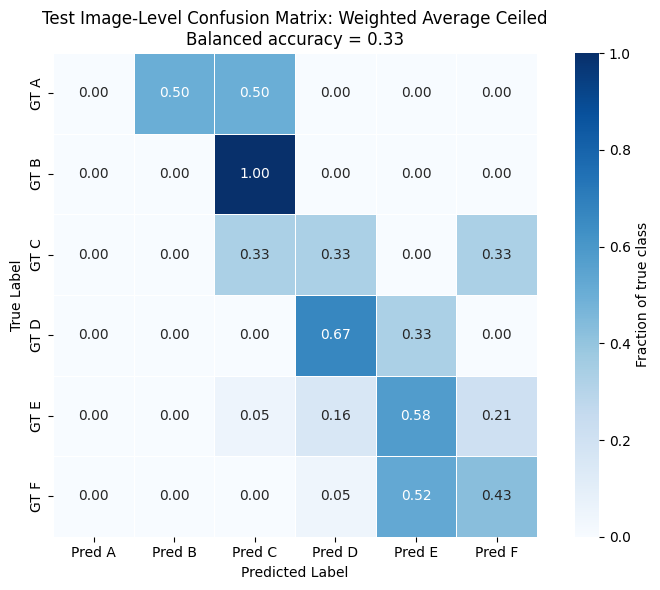

Saved raw confusion matrix: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/test_weighted_average_ceiled_confusion_raw.csv
Saved normalized confusion matrix: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/test_weighted_average_ceiled_confusion_row_normalized.csv
Saved heatmap: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/test_weighted_average_ceiled_confusion_heatmap.png

Saved image-level evaluation summary: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/test_image_level_confusion_summary.csv


,title,filename_prefix,num_images,accuracy,balanced_accuracy,raw_confusion_csv,normalized_confusion_csv,heatmap_path
0,Test Image-Level Confusion Matrix: Mode Aggreg...,test_mode,59,0.406780,0.427381,/content/drive/MyDrive/segformer_checkpoints/i...,/content/drive/MyDrive/segformer_checkpoints/i...,/content/drive/MyDrive/segformer_checkpoints/i...
1,Test Image-Level Confusion Matrix: Weighted Av...,test_weighted_average_rounded,59,0.542373,0.489553,/content/drive/MyDrive/segformer_checkpoints/i...,/content/drive/MyDrive/segformer_checkpoints/i...,/content/drive/MyDrive/segformer_checkpoints/i...
2,Test Image-Level Confusion Matrix: Weighted Av...,test_weighted_average_floored,59,0.542373,0.626504,/content/drive/MyDrive/segformer_checkpoints/i...,/content/drive/MyDrive/segformer_checkpoints/i...,/content/drive/MyDrive/segformer_checkpoints/i...
3,Test Image-Level Confusion Matrix: Weighted Av...,test_weighted_average_ceiled,59,0.423729,0.334586,/content/drive/MyDrive/segformer_checkpoints/i...,/content/drive/MyDrive/segformer_checkpoints/i...,/content/drive/MyDrive/segformer_checkpoints/i...


In [ ]:
import shutil
from sklearn.metrics import confusion_matrix, accuracy_score, balanced_accuracy_score
import seaborn as sns

# The original cell ran this lookup twice (a pasted duplicate), so the saved output
# shows its three lines twice. Kept as run.
# Locate test aggregation CSVs
base_dir = OUTPUT_DIR

gt_path = os.path.join(base_dir, "gt_agg_test.csv")
pred_path = os.path.join(base_dir, "pred_agg_test.csv")

# Fall back to the Drive copy if the local files are missing
if not os.path.exists(gt_path) and DRIVE_CHECKPOINT_DIR is not None:
    drive_gt_path = os.path.join(DRIVE_CHECKPOINT_DIR, "gt_agg_test.csv")
    if os.path.exists(drive_gt_path):
        gt_path = drive_gt_path

if not os.path.exists(pred_path) and DRIVE_CHECKPOINT_DIR is not None:
    drive_pred_path = os.path.join(DRIVE_CHECKPOINT_DIR, "pred_agg_test.csv")
    if os.path.exists(drive_pred_path):
        pred_path = drive_pred_path

print("Ground-truth test CSV:", gt_path)
print("Prediction test CSV:  ", pred_path)

if not os.path.exists(gt_path):
    raise FileNotFoundError(f"Could not find ground-truth test CSV: {gt_path}")

if not os.path.exists(pred_path):
    raise FileNotFoundError(f"Could not find prediction test CSV: {pred_path}")

# Output directory
eval_dir = IMAGE_LEVEL_EVAL_DIR
os.makedirs(eval_dir, exist_ok=True)

print("Evaluation output directory:", eval_dir)

# Locate test aggregation CSVs
base_dir = OUTPUT_DIR

gt_path = os.path.join(base_dir, "gt_agg_test.csv")
pred_path = os.path.join(base_dir, "pred_agg_test.csv")

# Fall back to the Drive copy if the local files are missing
if not os.path.exists(gt_path) and DRIVE_CHECKPOINT_DIR is not None:
    drive_gt_path = os.path.join(DRIVE_CHECKPOINT_DIR, "gt_agg_test.csv")
    if os.path.exists(drive_gt_path):
        gt_path = drive_gt_path

if not os.path.exists(pred_path) and DRIVE_CHECKPOINT_DIR is not None:
    drive_pred_path = os.path.join(DRIVE_CHECKPOINT_DIR, "pred_agg_test.csv")
    if os.path.exists(drive_pred_path):
        pred_path = drive_pred_path

print("Ground-truth test CSV:", gt_path)
print("Prediction test CSV:  ", pred_path)

if not os.path.exists(gt_path):
    raise FileNotFoundError(f"Could not find ground-truth test CSV: {gt_path}")

if not os.path.exists(pred_path):
    raise FileNotFoundError(f"Could not find prediction test CSV: {pred_path}")

# Output directory
eval_dir = IMAGE_LEVEL_EVAL_DIR
os.makedirs(eval_dir, exist_ok=True)

print("Evaluation output directory:", eval_dir)

# Helper functions
def normalize_filename_for_merge(filename):
    """
    Normalize filenames so GT and prediction rows can be matched safely.
    """
    stem = os.path.splitext(os.path.basename(str(filename)))[0]

    prefixes = [
        "pred_mask_ids_",
        "pred_mask_color_",
        "pred_overlay_",
        "seg_",
    ]

    suffixes = [
        "_pred_mask_ids",
        "_pred_colored",
        "_pred_overlay",
        "_comparison",
        "_gt_mask_ids",
    ]

    for prefix in prefixes:
        if stem.startswith(prefix):
            stem = stem[len(prefix):]

    for suffix in suffixes:
        if stem.endswith(suffix):
            stem = stem[:-len(suffix)]

    # Handle GT mask names like Label_138_IMAGEID.png
    parts = stem.split("_")
    if len(parts) >= 3 and parts[0] == "Label" and parts[1].isdigit():
        stem = "_".join(parts[2:])

    return stem

def load_and_merge(gt_path, pred_path):
    """
    Load GT and prediction aggregation CSVs and merge by normalized filename.
    """
    gt_df = pd.read_csv(gt_path)
    pred_df = pd.read_csv(pred_path)

    required_cols = ["Filename", "Mode", "Weighted Average"]

    for col in required_cols:
        if col not in gt_df.columns:
            raise ValueError(f"Missing column '{col}' in GT CSV.")
        if col not in pred_df.columns:
            raise ValueError(f"Missing column '{col}' in prediction CSV.")

    gt_df = gt_df.copy()
    pred_df = pred_df.copy()

    gt_df["merge_id"] = gt_df["Filename"].apply(normalize_filename_for_merge)
    pred_df["merge_id"] = pred_df["Filename"].apply(normalize_filename_for_merge)

    merged = gt_df.merge(
        pred_df,
        on="merge_id",
        how="inner",
        suffixes=("_GT", "_Pred")
    )

    print("\nGT rows:", len(gt_df))
    print("Prediction rows:", len(pred_df))
    print("Merged rows:", len(merged))

    missing_pred = sorted(set(gt_df["merge_id"]) - set(pred_df["merge_id"]))
    extra_pred = sorted(set(pred_df["merge_id"]) - set(gt_df["merge_id"]))

    print("GT rows missing prediction:", len(missing_pred))
    print("Prediction rows missing GT:", len(extra_pred))

    if len(missing_pred) > 0:
        print("First missing predictions:", missing_pred[:10])

    if len(extra_pred) > 0:
        print("First extra predictions:", extra_pred[:10])

    if len(merged) == 0:
        raise ValueError("No matching GT/prediction rows found after merge.")

    return merged

def clean_valid_classes(y, valid_classes):
    """
    Convert labels to numeric and keep only valid A-F class IDs.
    Invalid values become NaN.
    """
    y = pd.to_numeric(y, errors="coerce")
    y = y.where(y.isin(valid_classes), np.nan)
    return y

def show_and_save_confusion(y_true, y_pred, title, filename_prefix, eval_dir):
    """
    Create raw and row-normalized confusion matrices.
    Rows = ground truth.
    Columns = prediction.
    """
    valid_classes = DAMAGE_CLASSES
    class_labels = ["A", "B", "C", "D", "E", "F"]

    y_true = pd.Series(y_true)
    y_pred = pd.Series(y_pred)

    valid_mask = y_true.notna() & y_pred.notna()
    y_true = y_true[valid_mask].astype(int)
    y_pred = y_pred[valid_mask].astype(int)

    valid_class_mask = y_true.isin(valid_classes) & y_pred.isin(valid_classes)
    y_true = y_true[valid_class_mask]
    y_pred = y_pred[valid_class_mask]

    print("\n============================================================")
    print(title)
    print("============================================================")
    print("Number of evaluated images:", len(y_true))

    print("\nGT class counts:")
    print(y_true.value_counts().sort_index())

    print("\nPredicted class counts:")
    print(y_pred.value_counts().sort_index())

    if len(y_true) == 0:
        print("No valid A-F image-level pairs available.")
        return None

    cm_raw = confusion_matrix(
        y_true,
        y_pred,
        labels=valid_classes
    )

    cm_norm = confusion_matrix(
        y_true,
        y_pred,
        labels=valid_classes,
        normalize="true"
    )

    cm_raw_df = pd.DataFrame(
        cm_raw,
        index=[f"GT {label}" for label in class_labels],
        columns=[f"Pred {label}" for label in class_labels]
    )

    cm_norm_df = pd.DataFrame(
        cm_norm,
        index=[f"GT {label}" for label in class_labels],
        columns=[f"Pred {label}" for label in class_labels]
    )

    acc = accuracy_score(y_true, y_pred)
    bal_acc = balanced_accuracy_score(y_true, y_pred)

    print("\nAccuracy:", round(float(acc), 4))
    print("Balanced accuracy:", round(float(bal_acc), 4))

    raw_csv_path = os.path.join(eval_dir, f"{filename_prefix}_confusion_raw.csv")
    norm_csv_path = os.path.join(eval_dir, f"{filename_prefix}_confusion_row_normalized.csv")
    plot_path = os.path.join(eval_dir, f"{filename_prefix}_confusion_heatmap.png")

    cm_raw_df.to_csv(raw_csv_path)
    cm_norm_df.to_csv(norm_csv_path)

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm_norm_df,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        vmin=0,
        vmax=1,
        square=True,
        linewidths=0.5,
        cbar_kws={"label": "Fraction of true class"}
    )

    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(f"{title}\nBalanced accuracy = {bal_acc:.2f}")
    plt.tight_layout()
    plt.savefig(plot_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("Saved raw confusion matrix:", raw_csv_path)
    print("Saved normalized confusion matrix:", norm_csv_path)
    print("Saved heatmap:", plot_path)

    return {
        "title": title,
        "filename_prefix": filename_prefix,
        "num_images": int(len(y_true)),
        "accuracy": float(acc),
        "balanced_accuracy": float(bal_acc),
        "raw_confusion_csv": raw_csv_path,
        "normalized_confusion_csv": norm_csv_path,
        "heatmap_path": plot_path
    }

# Main evaluation
def evaluate_predictions(gt_path, pred_path, eval_dir):
    """
    Evaluate image-level predicted damage scores against ground truth.

    Includes:
    1. Mode
    2. Weighted Average rounded
    3. Weighted Average floored
    4. Weighted Average ceiled
    """
    valid_classes = DAMAGE_CLASSES

    merged = load_and_merge(gt_path, pred_path)

    merged_path = os.path.join(eval_dir, "merged_gt_pred_test_image_level_scores.csv")
    merged.to_csv(merged_path, index=False)

    print("\nSaved merged GT/pred table:", merged_path)

    results = []

    # Mode comparison
    gt_mode = clean_valid_classes(merged["Mode_GT"], valid_classes)
    pred_mode = clean_valid_classes(merged["Mode_Pred"], valid_classes)

    result = show_and_save_confusion(
        y_true=gt_mode,
        y_pred=pred_mode,
        title="Test Image-Level Confusion Matrix: Mode Aggregation",
        filename_prefix="test_mode",
        eval_dir=eval_dir
    )

    if result is not None:
        results.append(result)

    # Weighted average rounded
    gt_wa_rounded = pd.to_numeric(merged["Weighted Average_GT"], errors="coerce").round()
    pred_wa_rounded = pd.to_numeric(merged["Weighted Average_Pred"], errors="coerce").round()

    gt_wa_rounded = clean_valid_classes(gt_wa_rounded, valid_classes)
    pred_wa_rounded = clean_valid_classes(pred_wa_rounded, valid_classes)

    result = show_and_save_confusion(
        y_true=gt_wa_rounded,
        y_pred=pred_wa_rounded,
        title="Test Image-Level Confusion Matrix: Weighted Average Rounded",
        filename_prefix="test_weighted_average_rounded",
        eval_dir=eval_dir
    )

    if result is not None:
        results.append(result)

    # Weighted average floored
    gt_wa_floored = np.floor(pd.to_numeric(merged["Weighted Average_GT"], errors="coerce"))
    pred_wa_floored = np.floor(pd.to_numeric(merged["Weighted Average_Pred"], errors="coerce"))

    gt_wa_floored = clean_valid_classes(gt_wa_floored, valid_classes)
    pred_wa_floored = clean_valid_classes(pred_wa_floored, valid_classes)

    result = show_and_save_confusion(
        y_true=gt_wa_floored,
        y_pred=pred_wa_floored,
        title="Test Image-Level Confusion Matrix: Weighted Average Floored",
        filename_prefix="test_weighted_average_floored",
        eval_dir=eval_dir
    )

    if result is not None:
        results.append(result)

    # Weighted average ceiled
    gt_wa_ceiled = np.ceil(pd.to_numeric(merged["Weighted Average_GT"], errors="coerce"))
    pred_wa_ceiled = np.ceil(pd.to_numeric(merged["Weighted Average_Pred"], errors="coerce"))

    gt_wa_ceiled = clean_valid_classes(gt_wa_ceiled, valid_classes)
    pred_wa_ceiled = clean_valid_classes(pred_wa_ceiled, valid_classes)

    result = show_and_save_confusion(
        y_true=gt_wa_ceiled,
        y_pred=pred_wa_ceiled,
        title="Test Image-Level Confusion Matrix: Weighted Average Ceiled",
        filename_prefix="test_weighted_average_ceiled",
        eval_dir=eval_dir
    )

    if result is not None:
        results.append(result)

    # Save summary
    summary_df = pd.DataFrame(results)
    summary_path = os.path.join(eval_dir, "test_image_level_confusion_summary.csv")
    summary_df.to_csv(summary_path, index=False)

    print("\nSaved image-level evaluation summary:", summary_path)

    # Copy the whole evaluation folder to Drive if mirroring is on
    if DRIVE_CHECKPOINT_DIR is not None:
        drive_eval_dir = os.path.join(DRIVE_CHECKPOINT_DIR, "image_level_evaluation")
        os.makedirs(drive_eval_dir, exist_ok=True)

        for filename in os.listdir(eval_dir):
            src = os.path.join(eval_dir, filename)
            dst = os.path.join(drive_eval_dir, filename)

            if os.path.isfile(src):
                shutil.copy2(src, dst)

        print("Copied image-level evaluation outputs to Drive:", drive_eval_dir)

    return merged, summary_df
# Run evaluation
merged_test_image_level_df, test_image_level_summary_df = evaluate_predictions(
    gt_path=gt_path,
    pred_path=pred_path,
    eval_dir=eval_dir
)

display(test_image_level_summary_df)

Results on the 59 test images:

| Rule | Accuracy | Balanced accuracy |
|---|---|---|
| Mode | 0.4068 | 0.4274 |
| Weighted average, rounded | 0.5424 | 0.4896 |
| Weighted average, floored | 0.5424 | 0.6265 |
| Weighted average, ceiled | 0.4237 | 0.3346 |

Mode (Figure 6). Category E is classified correctly in all its test images and A is split evenly between A and C (0.50 each). B is always predicted as C, so the model does not recover this rare category under mode aggregation. C is mostly correct (0.57), with some images overestimated as F (0.29). D is spread over C (0.30), E (0.20) and F (0.40), and F is often predicted as E (0.32) or D (0.18). Several rows rest on few images: under the mode the test set contains only 2 images of category B and 4 of E (Table 3), so values such as 1.00 must be read with caution. In the ground truth F is the mode of 28 of the 59 test images, but in the predictions of only 17; the predicted modes move mainly to C and E (15 images each, against 7 and 4 in the ground truth). This follows from the pixel-level confusion between neighbouring categories in Section 8.2: a moderate shift of pixels from F to E changes the largest category of an image but changes its weighted average only a little.

Weighted average, rounded (Figure 7). The balanced accuracy is higher than with the mode. E is classified best (0.70), followed by B and F (0.50), D (0.47), C (0.40) and A (0.38). The errors for D fall on the neighbouring categories C (0.20) and E (0.33). C is spread over four categories (B, C, D and F), and F is predicted as D in 0.33 of its images; apart from C and F, most errors fall on neighbouring or nearby categories.

Weighted average, floored and ceiled. The floored rule has the highest balanced accuracy. Under flooring neither the ground truth nor the predictions reach F, because a floored weighted average equals 8 only when every triage pixel is F; its balanced accuracy is therefore a mean over the five categories A to E. Under ceiling, no test image is predicted as A, so the 8 test images whose ground truth is A are all misclassified.

The mean absolute errors of the image-level scores (Table 5 of the manuscript) are computed in notebook 02 from `merged_gt_pred_test_image_level_scores.csv`.

The last cell of this section shows how much aggregation hides minority categories: 26 of the 59 test images contain pixels of category A, but A is the ground-truth mode of only 8 of them.

In [ ]:
# Check pixel-level presence of class A in test GT masks
test_pairs = get_pairs_from_dataset(test_dataset)

class_3_pixel_presence = 0
class_3_image_level_mode = 0

for img_path, gt_mask_path in test_pairs:
    gt_mask = np.array(Image.open(gt_mask_path))

    if np.any(gt_mask == 3):
        class_3_pixel_presence += 1

    gt_mode = aggregate_mask(gt_mask, method="mode")
    if gt_mode == 3:
        class_3_image_level_mode += 1

print("Test images with any class A pixels:", class_3_pixel_presence)
print("Test images with GT mode = A:", class_3_image_level_mode)

Test images with any class A pixels: 26
Test images with GT mode = A: 8


### 10.1 Distribution of predicted classes

The next cell counts how many test images fall into each predicted triage class under each rule and saves the counts, the percentages, the per-image labels and a plot. The corresponding ground-truth counts (Table 3) are printed by the evaluation cell above.

Prediction test CSV: /content/drive/MyDrive/segformer_checkpoints/pred_agg_test.csv
Output directory: /content/drive/MyDrive/segformer_checkpoints/image_level_evaluation

Predicted test-set class distribution by aggregation method

Number of prediction rows: 59

Counts table:


,Class_Name,Mode,Weighted Average Rounded,Weighted Average Floored,Weighted Average Ceiled
Class_ID,,,,,
3,A,4,3,4,0
4,B,2,6,8,4
5,C,15,7,9,8
6,D,6,16,24,9
7,E,15,22,14,24
8,F,17,5,0,14



Percent table:


,Class_Name,Mode,Weighted Average Rounded,Weighted Average Floored,Weighted Average Ceiled
Class_ID,,,,,
3,A,6.779661,5.084746,6.779661,0.000000
4,B,3.389831,10.169492,13.559322,6.779661
5,C,25.423729,11.864407,15.254237,13.559322
6,D,10.169492,27.118644,40.677966,15.254237
7,E,25.423729,37.288136,23.728814,40.677966
8,F,28.813559,8.474576,0.000000,23.728814



Saved per-image aggregation labels:
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/predicted_test_image_level_aggregation_labels.csv

Saved counts table:
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/predicted_test_class_distribution_by_aggregation_method_counts.csv

Saved percent table:
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/predicted_test_class_distribution_by_aggregation_method_percent.csv


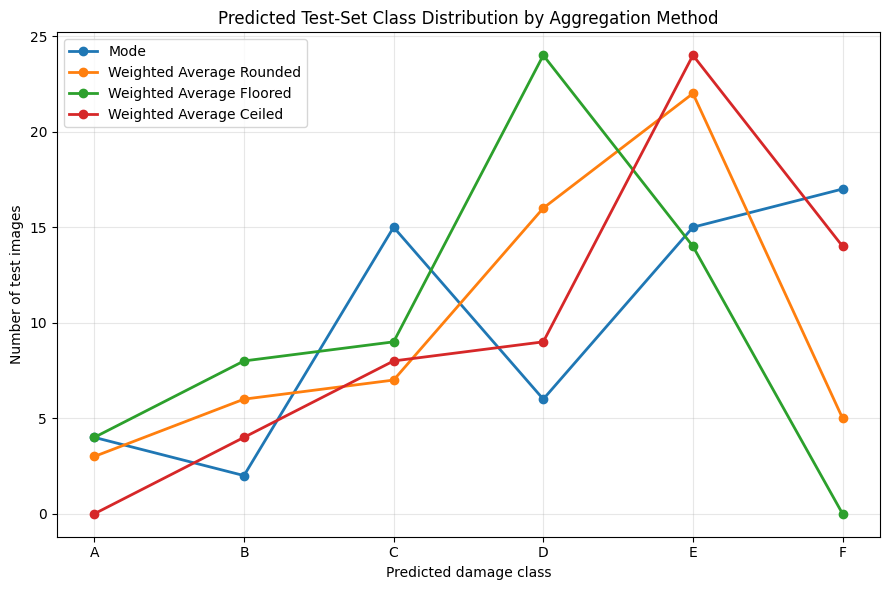


Saved plot:
/content/drive/MyDrive/segformer_checkpoints/image_level_evaluation/predicted_test_class_distribution_by_aggregation_method_plot.png


In [ ]:
import shutil

# Locate prediction aggregation CSV
base_dir = OUTPUT_DIR

pred_path = os.path.join(base_dir, "pred_agg_test.csv")

# Fall back to the Drive copy if the local file is missing
if not os.path.exists(pred_path) and DRIVE_CHECKPOINT_DIR is not None:
    drive_pred_path = os.path.join(DRIVE_CHECKPOINT_DIR, "pred_agg_test.csv")
    if os.path.exists(drive_pred_path):
        pred_path = drive_pred_path

print("Prediction test CSV:", pred_path)

if not os.path.exists(pred_path):
    raise FileNotFoundError(f"Could not find prediction test CSV: {pred_path}")

# Output directory
output_dir = IMAGE_LEVEL_EVAL_DIR
os.makedirs(output_dir, exist_ok=True)

print("Output directory:", output_dir)

# Main function
def compute_predicted_test_distribution_from_csv(
    pred_csv_path,
    output_dir,
    valid_classes=DAMAGE_CLASSES,
    class_names=None,
    show_plot=True
):
    """
    Computes predicted test-set image-level class distributions
    according to several aggregation methods.

    Input CSV must contain:
    - Filename
    - Mode
    - Weighted Average

    Outputs:
    1. Per-image table with predicted aggregation labels
    2. Count table by class and aggregation method
    3. Percent table by class and aggregation method
    4. Plot comparing distributions
    """

    if class_names is None:
        class_names = {
            3: "A",
            4: "B",
            5: "C",
            6: "D",
            7: "E",
            8: "F"
        }

    os.makedirs(output_dir, exist_ok=True)

    pred_df = pd.read_csv(pred_csv_path)

    required_cols = ["Filename", "Mode", "Weighted Average"]
    for col in required_cols:
        if col not in pred_df.columns:
            raise ValueError(f"Missing required column in prediction CSV: {col}")

    df = pred_df.copy()

    # Convert aggregation values
    df["Mode_Pred"] = pd.to_numeric(df["Mode"], errors="coerce")
    df["Weighted Average_Pred"] = pd.to_numeric(df["Weighted Average"], errors="coerce")

    df["WA_round_Pred"] = df["Weighted Average_Pred"].round()
    df["WA_floor_Pred"] = np.floor(df["Weighted Average_Pred"])
    df["WA_ceil_Pred"] = np.ceil(df["Weighted Average_Pred"])

    aggregation_cols = {
        "Mode": "Mode_Pred",
        "Weighted Average Rounded": "WA_round_Pred",
        "Weighted Average Floored": "WA_floor_Pred",
        "Weighted Average Ceiled": "WA_ceil_Pred"
    }

    # Keep only valid A-F damage classes
    for col in aggregation_cols.values():
        df[col] = pd.to_numeric(df[col], errors="coerce")
        df[col] = df[col].where(df[col].isin(valid_classes), np.nan)

    # Save per-image table
    per_image_cols = [
        "Filename",
        "Mode_Pred",
        "Weighted Average_Pred",
        "WA_round_Pred",
        "WA_floor_Pred",
        "WA_ceil_Pred"
    ]

    pred_agg_df = df[per_image_cols].copy()

    per_image_path = os.path.join(
        output_dir,
        "predicted_test_image_level_aggregation_labels.csv"
    )

    pred_agg_df.to_csv(per_image_path, index=False)

    # Count classes for each aggregation method
    counts_table = pd.DataFrame(index=valid_classes)

    for method_name, col in aggregation_cols.items():
        counts = (
            df[col]
            .dropna()
            .astype(int)
            .value_counts()
            .reindex(valid_classes, fill_value=0)
            .sort_index()
        )

        counts_table[method_name] = counts

    counts_table.index.name = "Class_ID"
    counts_table.insert(
        0,
        "Class_Name",
        [class_names[c] for c in counts_table.index]
    )

    counts_path = os.path.join(
        output_dir,
        "predicted_test_class_distribution_by_aggregation_method_counts.csv"
    )

    counts_table.to_csv(counts_path)

    # Percent table
    # Percent is computed within each aggregation method
    percent_table = counts_table.copy()

    for method_name in aggregation_cols.keys():
        total = counts_table[method_name].sum()

        if total > 0:
            percent_table[method_name] = (
                counts_table[method_name] / total * 100
            )
        else:
            percent_table[method_name] = np.nan

    percent_path = os.path.join(
        output_dir,
        "predicted_test_class_distribution_by_aggregation_method_percent.csv"
    )

    percent_table.to_csv(percent_path)

    # Print results
    print("\n============================================================")
    print("Predicted test-set class distribution by aggregation method")
    print("============================================================")

    print("\nNumber of prediction rows:", len(df))

    print("\nCounts table:")
    display(counts_table)

    print("\nPercent table:")
    display(percent_table)

    print("\nSaved per-image aggregation labels:")
    print(per_image_path)

    print("\nSaved counts table:")
    print(counts_path)

    print("\nSaved percent table:")
    print(percent_path)

    # Plot counts
    plot_df = counts_table.drop(columns=["Class_Name"]).copy()
    plot_df.index = [class_names[c] for c in valid_classes]

    plot_path = os.path.join(
        output_dir,
        "predicted_test_class_distribution_by_aggregation_method_plot.png"
    )

    plt.figure(figsize=(9, 6))

    for method_name in plot_df.columns:
        plt.plot(
            plot_df.index,
            plot_df[method_name],
            marker="o",
            linewidth=2,
            label=method_name
        )

    plt.xlabel("Predicted damage class")
    plt.ylabel("Number of test images")
    plt.title("Predicted Test-Set Class Distribution by Aggregation Method")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(plot_path, dpi=300, bbox_inches="tight")

    if show_plot:
        plt.show()
    else:
        plt.close()

    print("\nSaved plot:")
    print(plot_path)

    # Copy to Google Drive if mirroring is on
    if DRIVE_CHECKPOINT_DIR is not None:
        drive_output_dir = os.path.join(
            DRIVE_CHECKPOINT_DIR,
            "image_level_evaluation"
        )

        os.makedirs(drive_output_dir, exist_ok=True)

        for path in [per_image_path, counts_path, percent_path, plot_path]:
            if os.path.exists(path):
                shutil.copy2(
                    path,
                    os.path.join(drive_output_dir, os.path.basename(path))
                )

        print("\nCopied outputs to Drive:")
        print(drive_output_dir)

    return pred_agg_df, counts_table, percent_table

# Run
pred_test_agg_df, pred_test_counts_table, pred_test_percent_table = (
    compute_predicted_test_distribution_from_csv(
        pred_csv_path=pred_path,
        output_dir=output_dir,
        show_plot=True
    )
)

## 11. Outputs and the next notebook

Everything is written to `OUTPUT_DIR` (and mirrored to `DRIVE_OUTPUT_DIR` where the code copies to Drive):

- model and training: `best_model.pt`, `latest_runtime_checkpoint.pt`, `checkpoint_epoch_XXX.pt`, `final_model_state_dict.pt`, `class_weights.pt`, `class_weights.csv`, `training_history.csv`, `training_summary.json`, `loss_curve.png`;
- data: `matched_image_mask_gps.csv`, `split_assignment.csv`;
- image-level scores of the test set: `pred_agg_test.csv`, `gt_agg_test.csv`;
- `metrics/`: per-class and per-image IoU (`test_mean_iou_per_class.csv`, `test_iou_per_image.csv` and `.npy` versions), the pixel-level confusion matrices (`test_confusion_matrix_raw_pixels.csv`, `test_confusion_matrix_row_normalized.csv`, `test_confusion_matrix_row_normalized_for_plot.csv`, `test_confusion_matrix_summary.json`) and the heatmap `test_confusion_matrix_heatmap_normalized.png`;
- `image_level_evaluation/`: the full-dataset ground-truth aggregation from Section 3, the merged test scores, the image-level confusion matrices and heatmaps for each rule (`test_mode_*`, `test_weighted_average_rounded_*`, `test_weighted_average_floored_*`, `test_weighted_average_ceiled_*`), `test_image_level_confusion_summary.csv`, and the predicted class distribution from Section 10.1;
- figures and masks: `inference_outputs/`, `image_comparisons/`, `comparison_original_images/`, `comparison_gt_masks/`, `pred_masks_final/`.

`02_prediction_error_and_spatial_analysis.ipynb` continues from three of these files:

1. `image_level_evaluation/merged_gt_pred_test_image_level_scores.csv`, the ground-truth and predicted mode and weighted average for each test image, with GPS coordinates (used for Table 5 and the test-set heatmaps);
2. `image_level_evaluation/full_dataset_gt_image_level_aggregations_from_raw_masks.csv`, the ground-truth mode and weighted average for all 361 annotated images;
3. `best_model.pt`, the trained model, which notebook 02 uses to predict all 361 images (the same file is available from Hugging Face, Section 6.1).

By default notebook 02 expects them under `/content/drive/MyDrive/segformer_checkpoints`, which is where they are when this notebook runs with `MIRROR_TO_DRIVE = True`. The evaluation cell of Section 10 copies the whole `image_level_evaluation` folder, including the full-dataset table from Section 3, to Drive. The Drive copy of `best_model.pt` is refreshed only at the 5-epoch backups; in the reported run the best epoch (21) was copied at epoch 25 and did not change afterwards. Otherwise, copy the three files to that folder by hand.